# LSST Y1 × DESI: the paper model and model B against $k_\mathrm{max}$

The forecast fits the DESI band powers $C_\ell^{gg}$ of thin redshift bins,
computed without the Limber approximation, on four bin layouts: bins of equal
comoving width $\Delta d_\mathrm{com} = 62$ Mpc, and bins of fixed redshift
width $\Delta z = 0.02$, $0.05$ and $0.2$. This notebook forecasts with the
one-loop bias model B of `notes/higher_order_bias` and with the paper model,
which is model B + tilts without the radial counterterm $\alpha_2$. It
scans the scale cut for four results:

1. the figures of merit of model B against $k_\mathrm{max}$ (section 6);
2. the $k_\mathrm{max}$ at which model B breaks, under the truths outside
   its prior, and the shifts of the truths it models with a prior
   (section 7);
3. the data of the correlated-prior note's figure of the FoM against
   $k_\mathrm{max}$ (section 8);
4. the paper model on the pessimistic linear-bias prior: its FoMs, shifts,
   break point and error-bar test at every cut, and the data of the summary
   note's figures (section 9), with the study of $\alpha_2$ against the
   Fingers-of-God dispersions $\sigma_v$ that chose it (section 11).

**Symbols.** $D(z)$ is the linear growth factor with $D(0) = 1$;
$w(a) = w_0 + w_a(1 - a)$ the dark-energy equation of state, with $a$ the scale
factor; $\Omega_m$ the matter density today in units of the critical density;
$A_s$ the amplitude of the primordial curvature power spectrum, sampled as
`As_1e9` $= 10^9 A_s$. ${\rm FoM}(w_0, w_a) = [\det \mathrm{Cov}(w_0, w_a)]^{-1/2}$
is the inverse area of the marginalized $(w_0, w_a)$ error ellipse, and
${\rm FoM}(\Omega_m, 10^9 A_s)$ the same for $(\Omega_m, 10^9 A_s)$. $\sigma$ is
a parameter's marginalized one-sigma error.

**Model B.** The linear bias $b_{1,i}$ of bin $i$ is free per bin under a
linear-bias prior. The quadratic bias $b_2$ and the tidal bias $b_{s^2}$ follow
it through calibrations plus one offset per tracer group $g$:
$b_{2,i} = b_2^\mathrm{L}(b_{1,i}) + \Delta_{2,g}$, with $b_2^\mathrm{L}$ the
Lazeyras et al. fit (arXiv:1511.01096), and
$b_{s^2,i} = -\tfrac{4}{7}(b_{1,i} - 1) + \Delta_{s,g}$ (co-evolution). Each group
also carries a $k^2$ counterterm $\alpha_0$, in $h^{-2}\,\mathrm{Mpc}^2$, the
radial counterterm $\alpha_2$ in the DESI DR1 convention (the counterterm
density is $\tfrac{1}{2}(b_1\alpha_0 + f\mu^2\alpha_2)\,k^2\delta_\mathrm{L}$,
with $f$ the linear growth rate, $\mu$ the cosine of the angle to the line of
sight and $\delta_\mathrm{L}$ the linear density contrast), a white noise
$\mathrm{SN}_0$ beyond Poisson, in units of the bin's Poisson power
$1/\bar n_i$ ($\bar n_i$ the tracer density), and the stochastic term
$\mathrm{SN}_2\,k^2\mu^2$, in units of $f_\mathrm{sat}\sigma_\mathrm{sat}^2/\bar n_i$:
$f_\mathrm{sat}$ the satellite fraction and $\sigma_\mathrm{sat}$ the satellites'
velocity dispersion in distance units (DESI DR1 values per sample,
`SN2_UNIT` of `likelihood/desi_cl.py`; not the Fingers-of-God dispersion
$\sigma_v$ that smooths the bins' redshift distributions). $\mathrm{SN}_2$
projects through the radial derivatives of the bin kernels, so adjacent bins,
which share an edge, get an anticorrelated cross term that $\mathrm{SN}_0$
cannot mimic. CosmoLike has no redshift-space one-loop terms, so model B
carries none. The Gaussian priors are centered on zero:

| parameter | width |
|---|---|
| $\Delta_2$ | 2.0 |
| $\Delta_s$ | 1.0 |
| $\alpha_0$ [$h^{-2}\,\mathrm{Mpc}^2$] | $0.5/k_\mathrm{max}^2$ |
| $\alpha_2$ [$h^{-2}\,\mathrm{Mpc}^2$] | $0.5/k_\mathrm{max}^2$ |
| $\mathrm{SN}_0$ [$1/\bar n_i$] | 2 |
| $\mathrm{SN}_2$ [$f_\mathrm{sat}\sigma_\mathrm{sat}^2/\bar n_i$] | 5 |

The counterterm widths are the DESI rule of a 50% correction at the cut,
evaluated at every cut: $88.9\,h^{-2}\,\mathrm{Mpc}^2$ at
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$, DESI's $12.5$ at $0.2$.

**Variants.** Model B has one offset, counterterm and stochastic amplitude per
group; model B + tilts also tilts $\Delta_2$, $\Delta_s$, $\alpha_0$ and
$\alpha_2$ linearly in redshift across the group, with flat priors on the
tilts. $\mathrm{SN}_0$ and $\mathrm{SN}_2$ never tilt: their Poisson part is
known bin by bin. The code labels are `'B'` and `'B tilts'`. **The paper
model** is model B + tilts with $\alpha_2$ and its tilts fixed at zero and
every $\sigma_v$ prior width multiplied by 6 (code label
`'B tilts noA2 sv x6'`, the example yamls `EXAMPLE_EVALUATE1-4.yaml`); the
widened $\sigma_v$ absorb the $\alpha_2$ the model lacks (section 11).

**Linear-bias priors.** The fits use three of the four priors of the
correlated-prior note, `notes/correlated_bias_prior_v2`: baseline, pessimistic
and free (code label `'independent'`). The growth-tied prior is omitted from
the FoM figures: it fails that note's accuracy test, so its FoM means nothing.
Section 9 shows that it fails under model B + tilts too.

**The scale cut.** Bin $i$ is cut at $k_\mathrm{max}/D(\bar z_i)$, with
$\bar z_i$ its mean redshift, by the non-Limber ultraviolet-fraction criterion
(arXiv:2603.13031): a band is kept while less than $\alpha = 0.05$ of it comes
from the power spectrum above that wavenumber, within the shipped mask. The
fraction is computed on the paper model's own fiducial spectra (section 3).
Every $k_\mathrm{max}$ here is quoted at $z = 0$.

**Inputs and outputs.** Two kinds of expensive results are cached in
`chains/`, each with explicit compute, save and load cells: the scale cuts on
the paper fiducial (section 3) and the derivative base of each layout
(section 4). The committed notebook runs only the load cells; a cache whose
settings or fingerprint differ from the notebook's is refused, never
recomputed silently. `scripts/compute_fisher_base_mpi.py` writes the same
derivative caches on MPI ranks. The notebook writes the data of two figure
folders of the correlated-prior note (`fom_kmax_models`, `growth_tied_kmax`),
four of the summary note, `notes/bias_model_summary` (`summary_fom_kmax`,
`summary_fom_untied`, `summary_prior_draws`, `summary_pair_threshold`), four
of the Fingers-of-God note, `notes/fog_parameter_degeneracy_study`, and one of
the cross-correlations note, `notes/cross_correlations` (`pair_threshold`).

## 1. Set up Python and the Fisher module

Imports and the paths to CosmoLike and to the project's interface. The
project's Fisher module, imported as `fm`, builds the paper likelihood in
sections 3 and 4.

In [1]:
import importlib
import importlib.util
import inspect
import json
import os
import pickle
import re
import subprocess
import sys
import tempfile
import time
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import scipy.integrate
import scipy.linalg
import scipy.special
from IPython.display import Image, display

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_lssty1xdesi_fisher as fm
from cobaya.yaml import yaml_dump, yaml_load_file
print('Using the Fisher module at %s' % fm.__file__)
pd.set_option('display.float_format', '{:.4g}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 220)
# print every row of the long tables (pandas elides rows beyond 60)
pd.set_option('display.max_rows', 200)

Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py


## 2. The settings

- `COSMO`: the seven cosmological parameters ($10^9 A_s$, $n_s$, $H_0$,
  $\Omega_b$, $\Omega_m$, $w_0$, $w_a$), all with flat priors.
- `INVCOV_SCALE`: the DESI covariance is computed for 14,000 deg$^2$; its
  inverse is rescaled to the survey's 12,300 deg$^2$.
- `DERIVATIVE_TIER` and `LAYOUTS`: the four layouts on the paper yamls
  (`EXAMPLE_EVALUATE1`–`4.yaml`), at the derivative accuracy of one tier of
  `fm.derivative_settings`. The **final** tier holds the converged settings
  that the derivative convergence study of `tests/studies/` chose, above the
  examples' MCMC settings, CAMB included; it is the tier of every figure in a
  paper or in a note's final version, and it needs CAMB built with the
  halofit tolerance patch, which `fm.check_halofit_patch` verifies.
  `bias_params` names each layout's linear-bias parameter file, whose ties
  say which group amplitude $B_g$ (`DESI_B1_<g>`) each bin follows.
- `EXPLORATION_PARAMS`: the linear parameter files of the exploration fits,
  whose Gaussian $\sigma_v$ priors are the widths of model B and model B +
  tilts. The paper yamls carry the same widths times `PAPER_SIGV_SCALE` $= 6$;
  section 4 checks that.
- `DERIV_CACHE`, `TEMPLATE_CACHE`, `OPERATOR_STEPS`, `ALPHA2_SETTER`,
  `ALPHA2_KEYWORD`, `A2_STEP` and `COMPUTE_BASE`: the two derivative caches of
  each layout, the finite-difference steps of section 4, the compiled
  interface's per-bin $\alpha_2$ setter, and the switch of the compute and
  save cells of section 4.
- `SCALE_CUTS_CACHE`, `STUDY_SCRIPT`, `CUT_STUDY_CONFIG` and
  `COMPUTE_SCALE_CUTS`: the cache of the scale cuts, the study script whose
  settings compute them, its configuration, and the switch of the compute and
  save cells of section 3.
- `FIXED_WIDTHS` and `COUNTERTERM_FRACTION`: the prior widths of the table
  above; `prior_widths` returns them at one cut.
- `ALPHA2_TRUTH`, `SN2_TRUTH`, `CAL_DRIFT`, `SCENARIOS`, `SHIFT_THRESHOLD`
  and `ONE_SIGMA`: the truths of sections 7 and 9, the threshold of the break
  point, $\sigma/3$, and the content of a $1\sigma$ region, 68.3%.
- `LSST_Y1_SRD_FOM` $= 17.26$ and `LSST_Y1_SRD_FOM_OM_AS` $= 214.9$: the LSST Y1
  3x2pt references of the `lsst_y1` project, FoM$(w_0, w_a)$ and
  FoM$(\Omega_m, 10^9 A_s)$ from one Fisher matrix.
- `NOTE_PLOTS`: the correlated-prior note's plots folder, where section 8
  writes.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
CHAINS = ROOTDIR + '/projects/lssty1xdesi/chains/'
DESI_DATA = ROOTDIR + '/projects/lssty1xdesi/data/'
# the correlated-prior note's plots, where section 8 writes
NOTE_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior_v2/plots/'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
# one footprint for every probe [deg^2]; the DESI covariance files are built
# at DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
INVCOV_SCALE = AREA_DEG2/DESI_COV_AREA_DEG2
# the relative stencil step of the sampled parameters (fm.H_DEFAULT)
H_MAIN = 0.02
# LSST Y1 3x2pt in real space, the SRD setup (lsst_y1 project): the FoM of
# (w0, wa) and of (Omega_m, 10^9 A_s) from the Fisher matrix of its
# EXAMPLE_EVALUATE2.ipynb (chains/EXAMPLE_EVALUATE2_FISHER_3x2pt.pkl)
LSST_Y1_SRD_FOM = 17.26
LSST_Y1_SRD_FOM_OM_AS = 214.9

# The derivative accuracy tier (fm.derivative_settings): 'final', the
# converged settings of the convergence study tests/studies/run_fisher_derivatives.py,
# for every figure of a paper or of a note's final version, which needs CAMB
# built with the halofit tolerance patch (fm.check_halofit_patch stops here
# without it); 'exploration', the fast settings, for quick looks only. The
# tier is stored in every cache and hashed into its fingerprint, so a cache
# of the other tier is refused.
DERIVATIVE_TIER = 'final'
if DERIVATIVE_TIER == 'final':
    fm.check_halofit_patch()


def paper_layout(n, dataset, bias_params):
    '''One LAYOUTS entry: paper yaml n, its dataset and its linear-bias file.

    'overrides', 'camb' and 'accuracy_boost' are the tier's likelihood
    options, CAMB arguments and overall boost; 'stencil' names the rule of
    the per-bin columns, so a cache of another rule is refused.
    '''
    accuracy = fm.derivative_settings(dataset, DERIVATIVE_TIER)
    return {'yaml': PROJECT + f'EXAMPLE_EVALUATE{n}.yaml',
            'dataset': dataset,
            'bias_params': PROJECT + 'likelihood/' + bias_params,
            'overrides': accuracy['likelihood_overrides'],
            'camb': accuracy['camb_overrides'],
            'accuracy_boost': accuracy['accuracy_boost'],
            'tier': DERIVATIVE_TIER,
            'stencil': 'five-point'}


# The four layouts, in the order of the cache numbers n = 1, 2, 3, 4. The
# linear-bias file is the paper model's (the pessimistic prior): bin n of
# group g has DESI_B1_<n> = B_g (1 + delta_n), B_g = DESI_B1_<g>.
LAYOUTS = {
    'Delta d_com = 62 Mpc': paper_layout(1, 'lssty1xdesi_desi_dr3',
                                         'params_desi_bias_pessimistic.yaml'),
    'Delta z = 0.02': paper_layout(2, 'lssty1xdesi_desi_dr1_dz0p02',
                                   'params_desi_dr1_dz0p02_bias_pessimistic.yaml'),
    'Delta z = 0.05': paper_layout(3, 'lssty1xdesi_desi_dr1_dz0p05',
                                   'params_desi_dr1_dz0p05_bias_pessimistic.yaml'),
    'Delta z = 0.2': paper_layout(4, 'lssty1xdesi_desi_dr1_dz0p20',
                                  'params_desi_dr1_dz0p20_bias_pessimistic.yaml'),
}
# The linear parameter files of the exploration fits: their Gaussian sigma_v
# priors are the widths of model B and model B + tilts (section 4 reads them)
EXPLORATION_PARAMS = {
    'Delta d_com = 62 Mpc': PROJECT + 'likelihood/params_desi.yaml',
    'Delta z = 0.02': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
    'Delta z = 0.05': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
    'Delta z = 0.2': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
}
# the paper model widens every sigma_v prior of the exploration fits by this
# factor (the paper yamls carry the widened widths; section 4 checks them)
PAPER_SIGV_SCALE = 6.0


def comparable(settings):
    '''The part of a cache's settings that must match the current ones.

    The file names are dropped: the fingerprint (fm.settings_fingerprint, the
    sha256 of the fully resolved model - the example yaml, the likelihood's
    options and parameter fragments, the priors, the accuracy settings and
    the fiducial point) covers their content. A file that moves keeps its
    cache; a file edited under the same name does not.'''
    out = dict(settings)
    for field in ('yaml', 'bias_params'):
        out.pop(field, None)
    return out


def layout_fingerprint(key):
    '''The fingerprint of one layout's model at its derivative settings.'''
    s = LAYOUTS[key]
    return fm.settings_fingerprint(s['yaml'], likelihood_overrides=s['overrides'],
                                   accuracy_boost=s['accuracy_boost'],
                                   camb_overrides=s['camb'], tier=s['tier'])


FINGERPRINT = {key: layout_fingerprint(key) for key in LAYOUTS}

LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
# colorblind-safe layout colors (Okabe-Ito, without its green): no red or
# green in any figure
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': '#0072B2', 'Delta z = 0.02': '#E69F00',
                 'Delta z = 0.05': '#CC79A7', 'Delta z = 0.2': '#56B4E9'}

# The derivative base of section 4, two caches per layout ({:d} = n):
# DERIV_CACHE holds the stencil columns, the per-bin operator columns, the
# SN0 templates, the fiducial vector and biases; TEMPLATE_CACHE the alpha_2
# columns and the SN0 and SN2 templates.
DERIV_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_DERIVATIVES_{:d}.pkl'
TEMPLATE_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_TEMPLATES_{:d}.pkl'
# the steps d of the per-bin operator columns, each a five-point stencil at
# +-d and +-2d: b1 relative, b2 and bs2 absolute, alpha_0 in h^-2 Mpc^2
OPERATOR_STEPS = {'b1': 0.01, 'b2': 0.02, 'bs2': 0.02, 'a0': 5.0}
# The compiled interface's per-bin alpha_2 setter, called as setter(A2=array)
# with alpha_2 in h^-2 Mpc^2; the step is central and the term is linear, so
# any step gives the same column.
ALPHA2_SETTER = 'set_nuisance_bias_alpha2'
ALPHA2_KEYWORD = 'A2'
A2_STEP = 5.0
# True runs the compute and save cells of section 4 (hours per layout); the
# committed notebook loads the caches instead
COMPUTE_BASE = False

# The scale cuts of section 3, on the paper fiducial: one cache for the four
# layouts, computed at the reference settings of the derivative convergence
# study (CUT_STUDY_CONFIG of STUDY_SCRIPT) with its k_max list and UV fraction
SCALE_CUTS_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_SCALE_CUTS.pkl'
STUDY_SCRIPT = ROOTDIR + '/projects/lssty1xdesi/tests/studies/run_fisher_derivatives.py'
CUT_STUDY_CONFIG = 'reference'
# True runs the compute and save cells of section 3 (about an hour); the
# committed notebook loads the cache instead
COMPUTE_SCALE_CUTS = False

# The Gaussian prior widths that do not depend on the cut (notes/
# higher_order_bias, section "The model as implemented"): the b2 and bs2
# offsets, and SN0 and SN2 in their units (Poisson power; f_sat sigma_sat^2
# times it).
FIXED_WIDTHS = {
    'B': {'DB2': 2.0, 'DBS': 1.0, 'SN0': 2.0, 'SN2': 5.0},
}
# the counterterm widths: a correction of this fraction of the linear
# spectrum at k_max, width = COUNTERTERM_FRACTION/k_max^2 [h^-2 Mpc^2]
COUNTERTERM_FRACTION = 0.5
# the per-group parameter families of model B, and the tilt that model B +
# tilts adds (SN0 and SN2 never tilt)
MODEL_FAMILIES = {'B': ['DB2', 'DBS', 'A0', 'A2', 'SN0', 'SN2']}
TILT_OF = {'DB2': 'TB2', 'DBS': 'TBS', 'A0': 'TA0', 'A2': 'TA2'}
VARIANTS = ['B', 'B tilts']
# the names the printed tables and the figures give the variants
VARIANT_LABELS = {'B': 'model B', 'B tilts': 'model B + tilts'}
# the linear-bias priors of the fits ('independent' is the free prior)
FIT_PRIORS = ['baseline', 'pessimistic', 'independent']
PRIOR_LABELS = {'baseline': 'baseline', 'pessimistic': 'pessimistic',
                'independent': 'free'}
BIAS_GROUP_NAMES = ['BGS', 'LRG1', 'LRG2', 'LRG3', 'ELG1', 'ELG2']
BIAS_ASSUMPTIONS = {
    'baseline': {'L': 0.2, 'sigma_b': {'BGS': 0.03, 'LRG1': 0.01, 'LRG2': 0.01,
                                       'LRG3': 0.01, 'ELG1': 0.01, 'ELG2': 0.01}},
    'pessimistic': {'L': 0.05, 'sigma_b': {name: 0.03 for name in BIAS_GROUP_NAMES}},
}


def prior_widths(model, kmax):
    '''The Gaussian prior widths of one model's per-group parameters at a cut.

    Arguments:
      model = 'B'.
      kmax  = the cut [h/Mpc at z = 0]; it sets the counterterm widths.

    Returns:
      dict {family: width}: DB2, DBS, A0, A2, SN0 and SN2.
    '''
    widths = dict(FIXED_WIDTHS[model])
    widths['A0'] = COUNTERTERM_FRACTION/kmax**2
    widths['A2'] = COUNTERTERM_FRACTION/kmax**2
    return widths


# The bias truths of sections 7 and 9, each at one sigma and the same in
# every bin (the drift: linear across each group):
#   alpha_2: +-1 sigma of model B's own prior, COUNTERTERM_FRACTION/k_max^2
#     at each cut, and the DESI-size ALPHA2_TRUTH h^-2 Mpc^2 (section 9);
#   SN2 = +-SN2_TRUTH units of f_sat sigma_sat^2/nbar;
#   the b2 and bs2 offsets at +-1 sigma of model B's widths;
#   the calibration drift: the offsets linear in redshift across each group,
#     with zero mean, changing by CAL_DRIFT from the group's first bin to its
#     last (the tilts of model B + tilts absorb it; its alpha_0 and alpha_2
#     tilts are not exercised).
ALPHA2_TRUTH = 12.5
SN2_TRUTH = 5.0
CAL_DRIFT = {'b2': 1.0, 'bs2': 0.5}
# the two scenarios of the figure: the baseline linear-bias prior with model
# B, and the pessimistic prior with model B + tilts
SCENARIOS = {
    'baseline': {'prior': 'baseline', 'B': 'B'},
    'pessimistic': {'prior': 'pessimistic', 'B': 'B tilts'},
}
SHIFT_THRESHOLD = 1.0/3.0
# the probability inside a fit's one-sigma region: the 1 sigma interval of
# one parameter, and the (w0, wa) ellipse with the same content
ONE_SIGMA = float(scipy.special.erf(1.0/np.sqrt(2.0)))
# Bias errors move the clustering amplitude, b^2 A_s D^2, and the growth
# history first: the matter density and the primordial amplitude are scored
# next to (w0, wa), each in units of its own marginalized sigma.
SINGLE_PARAMS = ['omegam', 'As_1e9']

# Directions of a Fisher matrix whose eigenvalue, after scaling every
# parameter to unit diagonal, is below this fraction of the largest carry no
# information; stable_inverse drops them.
PINV_RTOL = 1.0e-12
# A parameter whose information at a cut (data and prior) is below this
# fraction of its information on the shipped mask has no data at that cut
# and leaves the fit.
NO_DATA_RTOL = 1.0e-10
# A dropped direction may touch the scored parameters by at most this
# component (scaled basis); a larger one means the cut leaves a scored
# parameter unconstrained, and the system gives no fit.
NULL_OVERLAP_MAX = 1.0e-6
# The two caches of a layout must hold the same fiducial vector, to this
# delta chi2 on the shipped mask (one run gives zero); a larger value means
# they come from different runs of different code.
M0_DCHI2_MAX = 1.0e-2


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


## 3. Data files and the scale cuts on the paper fiducial

Readers for the project's data files: `layout_tables` reads a layout's bin
table, cross-pair list, band centers and shipped mask, and `layout_covariance`
its covariance as a dense matrix.

**The scale cut.** The ultraviolet-fraction criterion (arXiv:2603.13031) keeps
a band of a spectrum while $|C_\mathrm{UV}|/(|C_\mathrm{UV}| + |C_\mathrm{IR}|)
< \alpha = 0.05$, where $C_\mathrm{UV}$ is the part of the band power that
comes from wavenumbers above the bin's cut, $k_\mathrm{max}/D(\bar z_i)$, and
$C_\mathrm{IR}$ the part from below it. CosmoLike's `gg_scale_cuts_tomo`
computes both parts from the spectra of the last evaluated point, so the cut
depends on the model and the point at which it is computed. Here that point is
the paper fiducial: the paper yaml `EXAMPLE_EVALUATE<n>.yaml` at its evaluate
point, with $b_2$ and $b_{s^2}$ on their calibrations. The linear notebook's
cuts (`EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl`) are computed on the
linear-bias spectra and serve the linear-bias experiments; the two differ
mostly through $b_2$ (`notes/scale_cut_fiducial_dependence`).

The cuts are computed at the reference settings of the derivative convergence
study (`tests/studies/run_fisher_derivatives.py`, configuration `'reference'`:
every accuracy control above its MCMC value), with its list of cuts,
$k_\mathrm{max} = 0.05, 0.075, \ldots, 0.25\,h/\mathrm{Mpc}$, and its
$\alpha$. The list matters: where the ultraviolet fraction is not monotonic in
$k_\mathrm{max}$, the cut of one $k_\mathrm{max}$ is shortened to that of the
next larger one.

Three cells follow the definitions. The compute cell runs only with
`COMPUTE_SCALE_CUTS = True` (one model per layout, about an hour for the
four); the save cell then writes `SCALE_CUTS_CACHE` and refuses to replace an
existing file unless it is called with `overwrite=True`; the load cell reads
the cache and stops when its settings or fingerprints differ from this
notebook's. The fingerprint is `fm.settings_fingerprint` of each layout's
paper yaml at the study's settings, so an edited yaml, prior, parameter file
or dataset file is caught.

In [3]:
def read_rows(path):
    '''The data rows of a text file (lines starting with # skipped).'''
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    '''The value of one "key = value" line of a .dataset file.'''
    for row in open(DESI_DATA + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


def layout_tables(key):
    '''The bin table, pair list, band centers and shipped mask of one layout.

    The data vector is [EE | gs | gg | gg-cross]: the shear and galaxy-shear
    blocks first (n_ee entries, empty here), then one block of bands per
    clustering auto spectrum and per measured cross pair. The mask file lists
    every entry once, so its length is the vector length n.

    Returns:
      dict: 'bins' and 'pairs' (rows of the bin table and the pair list),
      'ells', 'mask' (bool, n), 'n' and 'n_ee'.
    '''
    stem = LAYOUTS[key]['dataset']
    bins = read_rows(DESI_DATA + stem + '_bins.txt')
    pairs = [(int(r[0]), int(r[1])) for r in read_rows(DESI_DATA + stem + '_pairs.txt')]
    ells = np.loadtxt(DESI_DATA + dataset_entry(stem, 'ell_file')).ravel()
    mask_rows = read_rows(DESI_DATA + dataset_entry(stem, 'mask_file'))
    n = len(mask_rows)
    mask = np.zeros(n, dtype=bool)
    for row in mask_rows:
        mask[int(float(row[0]))] = float(row[1]) > 0
    n_ee = n - (len(bins) + len(pairs))*len(ells)
    if n_ee < 0:
        raise ValueError(f'{stem}: {len(bins)} autos and {len(pairs)} pairs of '
                         f'{len(ells)} bands do not fit in the mask\'s {n} entries')
    return {'bins': bins, 'pairs': pairs, 'ells': ells, 'mask': mask, 'n': n,
            'n_ee': n_ee}


def layout_covariance(key, n):
    '''The covariance of one layout as a dense n x n matrix (its cov_file).'''
    stem = LAYOUTS[key]['dataset']
    rows = np.loadtxt(DESI_DATA + dataset_entry(stem, 'cov_file'), usecols=(0, 1, 2))
    if int(rows[:, :2].max()) + 1 != n:
        width = int(rows[:, :2].max()) + 1
        raise ValueError(f'{stem}: the covariance is {width} entries wide, the vectors '
                         f'have {n}: the derivatives and the dataset disagree on the '
                         'layout')
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    return C


TABLES = {key: layout_tables(key) for key in LAYOUTS}
BIN_ZBAR = {key: np.array([float(row[4]) for row in TABLES[key]['bins']])
            for key in LAYOUTS}


def study_module():
    '''The derivative convergence study script as a module (its settings and
    its cut list), imported without writing bytecode into the project.'''
    spec = importlib.util.spec_from_file_location('run_fisher_derivatives', STUDY_SCRIPT)
    module = importlib.util.module_from_spec(spec)
    saved = sys.dont_write_bytecode
    sys.dont_write_bytecode = True
    try:
        spec.loader.exec_module(module)
    finally:
        sys.dont_write_bytecode = saved
    return module


rfd = study_module()
# the study's name of each layout
STUDY_LAYOUT = {'Delta d_com = 62 Mpc': 'dcom62', 'Delta z = 0.02': 'dz0p02',
                'Delta z = 0.05': 'dz0p05', 'Delta z = 0.2': 'dz0p20'}


def cut_settings(key):
    '''The settings of one layout's scale cut, as the cache stores them.

    Returns:
      dict: 'yaml' and 'dataset'; 'study_config' and 'study_settings' (the
      study's resolved configuration); 'likelihood_overrides' and
      'camb_overrides' (what ModelFisher receives); 'kmax' (the cut list,
      h/Mpc at z = 0) and 'alpha' (the UV-fraction threshold); 'fingerprint'
      (fm.settings_fingerprint of the paper yaml at these settings).
    '''
    s = LAYOUTS[key]
    study = rfd.resolve_settings(STUDY_LAYOUT[key], CUT_STUDY_CONFIG)
    overrides = rfd.likelihood_overrides(study)
    camb = rfd.camb_overrides(study)
    return {'yaml': s['yaml'], 'dataset': s['dataset'],
            'study_config': CUT_STUDY_CONFIG, 'study_settings': study,
            'likelihood_overrides': overrides, 'camb_overrides': camb,
            'kmax': [float(k) for k in rfd.CUT_KMAX], 'alpha': float(rfd.ALPHA_UV),
            'fingerprint': fm.settings_fingerprint(s['yaml'],
                                                   likelihood_overrides=overrides,
                                                   camb_overrides=camb)}


CUT_SETTINGS = {key: cut_settings(key) for key in LAYOUTS}


def compute_scale_cuts(key):
    '''The UV-fraction cuts of one layout on the paper fiducial.

    The study's run_cuts with the paper yaml in place of the linear one: the
    paper model at its fiducial point, then CosmoLike's gg_scale_cuts_tomo at
    every cut of the list.

    Returns:
      dict of numpy arrays, as gg_scale_cuts_tomo returns them: 'kmax'
      (nk, 1), 'ell', 'mask' (spectra, bands, nk; 1 where a band is kept,
      spectra in data-vector order), 'uv_fraction', 'lmax', 'nautos', ...;
      plus 'seconds'.
    '''
    s = CUT_SETTINGS[key]
    start = time.time()
    model = fm.ModelFisher(s['yaml'], COSMO,
                           likelihood_overrides=s['likelihood_overrides'],
                           camb_overrides=s['camb_overrides'])
    model.dv()
    cuts = fm.ci.gg_scale_cuts_tomo(np.array(s['kmax'], dtype=float), s['alpha'])
    out = {name: np.array(value) for name, value in cuts.items()}
    out['seconds'] = time.time() - start
    del model
    return out


def save_scale_cuts(cuts, overwrite=False):
    '''Write the cuts of the four layouts, with their settings, to
    SCALE_CUTS_CACHE.

    Raises:
      ValueError when a layout is missing; FileExistsError when the file
      exists and overwrite is False (nothing is written).
    '''
    missing = [key for key in LAYOUTS if key not in cuts]
    if missing:
        raise ValueError(f'no cuts for {missing}: the cache holds all four layouts')
    if os.path.exists(SCALE_CUTS_CACHE) and not overwrite:
        raise FileExistsError(f'{SCALE_CUTS_CACHE} exists: call save_scale_cuts(..., '
                              'overwrite=True) to replace it')
    payload = {'cuts': {key: cuts[key] for key in LAYOUTS},
               'settings': {key: dict(CUT_SETTINGS[key]) for key in LAYOUTS},
               'fingerprint': {key: CUT_SETTINGS[key]['fingerprint'] for key in LAYOUTS}}
    with open(SCALE_CUTS_CACHE, 'wb') as f:
        pickle.dump(payload, f)
    print(f'wrote {SCALE_CUTS_CACHE}')


def load_scale_cuts():
    '''The cuts of the four layouts from SCALE_CUTS_CACHE.

    Raises:
      RuntimeError when the cache is missing or its settings or
      fingerprints differ from CUT_SETTINGS (the yaml paths excepted).
    '''
    if not os.path.exists(SCALE_CUTS_CACHE):
        raise RuntimeError(f'{SCALE_CUTS_CACHE} is missing: set COMPUTE_SCALE_CUTS = '
                           'True and run the compute and save cells')
    with open(SCALE_CUTS_CACHE, 'rb') as f:
        cached = pickle.load(f)
    for key in LAYOUTS:
        stored = dict(cached['settings'][key])
        now = dict(CUT_SETTINGS[key])
        stored.pop('yaml', None)
        now.pop('yaml', None)
        same_fingerprint = cached['fingerprint'][key] == CUT_SETTINGS[key]['fingerprint']
        if stored != now or not same_fingerprint:
            raise RuntimeError(f'{SCALE_CUTS_CACHE}: the cuts of {key} were computed '
                               f'with {cached["settings"][key]}; this notebook expects '
                               f'{CUT_SETTINGS[key]}')
    return cached['cuts']


# the order of the compute cell: the cheapest layouts first
CUT_COMPUTE_ORDER = ['Delta z = 0.2', 'Delta z = 0.05', 'Delta d_com = 62 Mpc',
                     'Delta z = 0.02']
for key in LAYOUTS:
    print(f'{key}: {len(TABLES[key]["bins"])} bins, {len(TABLES[key]["pairs"])} cross '
          f'pairs, vector length {TABLES[key]["n"]}; cut fingerprint '
          f'{CUT_SETTINGS[key]["fingerprint"][:12]}...')

Delta d_com = 62 Mpc: 76 bins, 107 cross pairs, vector length 10494; cut fingerprint f7d499481264...
Delta z = 0.02: 90 bins, 133 cross pairs, vector length 12614; cut fingerprint 1d1af2550293...
Delta z = 0.05: 36 bins, 52 cross pairs, vector length 5459; cut fingerprint 5507370972b2...
Delta z = 0.2: 10 bins, 13 cross pairs, vector length 2014; cut fingerprint 2975fba0916f...


In [4]:
# compute: one model per layout (about an hour for the four)
if COMPUTE_SCALE_CUTS:
    SCALE_CUTS_RUN = {}
    for key in CUT_COMPUTE_ORDER:
        SCALE_CUTS_RUN[key] = compute_scale_cuts(key)
        print(f'{key}: cuts in {SCALE_CUTS_RUN[key]["seconds"]:.0f} s', flush=True)

In [5]:
# save: refuses to replace an existing cache unless overwrite=True
if COMPUTE_SCALE_CUTS:
    save_scale_cuts(SCALE_CUTS_RUN, overwrite=False)

In [6]:
# load: the cache, checked against this notebook's settings and fingerprints
CUTS = load_scale_cuts()

The cuts in use: `KMAX_CUTS` $= 0.05, 0.075, \ldots, 0.2\,h/\mathrm{Mpc}$
(`KMAX_MAX`; the cache's larger cuts are not used), and `CUT_MASK`, the bands
each keeps. The table counts the band powers each cut keeps together with the
shipped mask, and the same with the linear notebook's cuts, for comparison.

In [7]:
# The cached k_max column is (nk, 1): flatten it. The scan stops at
# KMAX_MAX [h/Mpc at z = 0]; the cache's larger cuts are not used. The cuts
# rise, so the kept ones are the cache's first ones and keep its indices.
KMAX_MAX = 0.2
KMAX_ALL = np.asarray(CUTS['Delta d_com = 62 Mpc']['kmax'], dtype=float).ravel()
KMAX_CUTS = KMAX_ALL[KMAX_ALL <= KMAX_MAX + 1.0e-9]
NK = len(KMAX_CUTS)
CUT_MASK = {}
for key in LAYOUTS:
    if not np.array_equal(np.ravel(CUTS[key]['kmax']), KMAX_ALL):
        raise RuntimeError(f'{SCALE_CUTS_CACHE}: {key} has other cuts than {KMAX_ALL}')
    # (spectra, bands, cuts): 1 where a band is kept, spectra in data-vector order
    CUT_MASK[key] = np.asarray(CUTS[key]['mask'])
    tables = TABLES[key]
    if CUT_MASK[key].shape[:2] != (len(tables['bins']) + len(tables['pairs']),
                                   len(tables['ells'])):
        raise RuntimeError(f'{key}: the cut mask is {CUT_MASK[key].shape[:2]}, the '
                           'layout has other spectra or bands')
print('k_max of the cuts [h/Mpc at z = 0]:', KMAX_CUTS)

# the linear notebook's cuts on the linear-bias spectra, for the comparison only
with open(CHAINS + 'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl', 'rb') as f:
    LINEAR_CUTS = pickle.load(f)['cuts']
counts = {}
for key in LAYOUTS:
    tables = TABLES[key]
    shipped = tables['mask'][tables['n_ee']:]
    linear = np.asarray(LINEAR_CUTS[key]['mask'])
    for m, k in enumerate(KMAX_CUTS):
        counts.setdefault((key, 'paper fiducial'), {})[float(k)] = int(
            np.sum(shipped & (CUT_MASK[key][:, :, m].ravel() > 0)))
        counts.setdefault((key, 'linear fiducial'), {})[float(k)] = int(
            np.sum(shipped & (linear[:, :, m].ravel() > 0)))
print('band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at '
      'z = 0]')
display(pd.DataFrame(counts).T)

k_max of the cuts [h/Mpc at z = 0]: [0.05  0.075 0.1   0.125 0.15  0.175 0.2  ]
band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at z = 0]


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc paper fiducial     239   1697   2732   3545   4439   5260   5526
                     linear fiducial    241   1715   2771   3559   4462   5272   5530
Delta z = 0.02       paper fiducial       0   1835   4371   5739   6033   6526   7500
                     linear fiducial      0   1856   4399   5817   6100   6572   7512
Delta z = 0.05       paper fiducial     434    819   1198   1663   1815   2226   2399
                     linear fiducial    437    846   1214   1670   1818   2295   2447
Delta z = 0.2        paper fiducial     166    276    378    445    475    561    666
                     linear fiducial    166    280    378    445    475    588    631

## 4. The derivative base

Every Fisher matrix of this notebook is a linear combination of a few base
columns per layout: derivatives of the data vector $m$ (the band powers) at
the fiducial point of the paper yaml, every higher-order bias parameter at
zero. They come in four kinds.

- **Stencil columns** of the seven cosmological parameters, the six group
  amplitudes $B_g$ and the seven velocity-dispersion leaders $\sigma_v$, each
  a five-point stencil of the likelihood (`model.derivatives`),
  $[-m(p + 2d) + 8m(p + d) - 8m(p - d) + m(p - 2d)]/(12d)$, with $d$ the step
  $h = 0.02$ times the parameter's value ($w_a = 0$ takes the absolute step
  $h$). No step depends on a prior.
- **Per-bin operator columns** $\partial m/\partial b_{1,i}$,
  $\partial m/\partial b_{2,i}$, $\partial m/\partial b_{s^2,i}$ and
  $\partial m/\partial \alpha_{0,i}$, each at fixed values of the other three,
  by the same five-point stencil. An $\alpha_0$ step enters CosmoLike's $k^2$
  slot, $2 b_1 b_K k^2 P_\mathrm{mm}$, as $b_K = \alpha_0/[2 b_1 (c/H_0)^2]$,
  because CosmoLike's $k$ is in units of $H_0/c$.
- **Per-bin $\alpha_2$ columns** $\partial m/\partial \alpha_{2,i}$ (the
  paper model fixes $\alpha_2 = 0$; model B needs the columns). $\alpha_2$
  enters the vector linearly, so the central difference at $\pm$`A2_STEP` is
  exact; the forward and backward differences check it.
- **Stochastic templates**: the likelihood's exact columns of $\mathrm{SN}_0$
  and $\mathrm{SN}_2$ (`stochastic_templates`, orders 0 and 2), read at the
  fiducial point. $\mathrm{SN}_0$ projects a constant power through the
  Fingers-of-God-convolved kernels $W_i$; $k^2\mu^2 = k_\parallel^2$ is the
  Fourier image of a second radial derivative, so integrating by parts
  projects $\mathrm{SN}_2$ exactly as
  $\int d\chi\, W_i'(\chi)\,W_j'(\chi)/\chi^2$ times its unit, with $\chi$ the
  comoving distance and $W_i' = dW_i/d\chi$.

**How a per-bin step reaches CosmoLike.** No sampled parameter moves one bin's
$b_1$ alone (the parameter files tie $b_2$ and $b_{s^2}$ to $b_1$), so a per-bin
column needs the arrays the likelihood hands to CosmoLike, shifted for a set of
bins. `scripts/compute_fisher_base_mpi_classes.py` defines a subclass of each
paper likelihood (`PerBinStepMixin`) that can add such a step:
`set_per_bin_step` stores it, the next evaluation runs the likelihood's own
`set_lens_related` in full and then calls the stepped operator's compiled
setter once more with the step added, and `clear_per_bin_step` removes it.
Without a step the subclass evaluates exactly what its parent does.
`step_yaml` writes a copy of the paper yaml whose likelihood block names that
class (its keys `class` and `python_path`), and `check_step_yaml` verifies that
the copy resolves to the same cobaya input (options, parameters, priors and
fiducial point) as the paper yaml.

A per-bin column moves a batch of bins at once. A greedy coloring of the
cross-pair graph (`pair_coloring`) puts two bins joined by a measured cross
pair in different batches ("colors"), so every spectrum involves at most one
shifted bin, and one stencil gives the columns of every bin of a batch. Every
layout needs four colors, so an operator costs sixteen evaluations instead of
four per bin.

**The order of the evaluations** is that of
`scripts/compute_fisher_base_mpi.py` on one rank, with the same classes: the
fiducial point (its vector, templates and per-bin biases), the operator
stencils (operator by operator, color by color, offset by offset), the stencil
points of `model.derivatives`, the $\alpha_2$ steps (color by color, $+$ then
$-$), and the fiducial point again. CosmoLike's setters keep a stored value when a new
one differs from it by less than a relative $10^{-13}$, so the order could
leave a last-digit trace; in this order this notebook and the script on one
rank, or on 2 ranks of 4 threads, write the same caches bit for bit.

Three cells follow the definitions: compute (only with `COMPUTE_BASE = True`,
from 25 minutes on $\Delta z = 0.2$ to hours on the thin layouts), save
(refuses to replace an existing file unless called with `overwrite=True`),
and load (stops when a cache's settings or fingerprint differ from this
notebook's). Both caches store the settings and the fingerprint of their
layout: the sha256 of the resolved paper yaml (its options, parameter files,
priors and fiducial point), the tier, and the content of the dataset files.

In [8]:
def alpha2_setter():
    '''The compiled interface's alpha_2 setter.

    Raises:
      RuntimeError naming the interface file when it has no ALPHA2_SETTER.
    '''
    setter = getattr(fm.ci, ALPHA2_SETTER, None)
    if setter is None:
        raise RuntimeError(
            f'the compiled interface {fm.ci.__file__} has no {ALPHA2_SETTER}: the '
            'alpha_2 columns need the model B counterterm in CosmoLike. Rebuild the '
            'interface with it, or set ALPHA2_SETTER to the name it was given.')
    return setter


def require_sn2_templates(like):
    '''Stop unless the likelihood's stochastic_templates projects SN2 (order = 2).'''
    parameters = inspect.signature(like.stochastic_templates).parameters
    if 'order' not in parameters:
        raise RuntimeError(
            f'{inspect.getsourcefile(like.stochastic_templates)}: stochastic_templates '
            'has no order argument, so it cannot project SN2. Install the model B '
            'version of likelihood/desi_cl.py.')


def pair_coloring(nbins, pairs):
    '''A greedy coloring of the pair graph: no pair joins two bins of one color.

    Bin i takes the smallest color that none of its lower-numbered neighbors
    (the bins it shares a measured cross pair with) has.'''
    neighbors = [set() for _ in range(nbins)]
    for a, b in pairs:
        neighbors[a].add(b)
        neighbors[b].add(a)
    color = []
    for i in range(nbins):
        used = {color[j] for j in neighbors[i] if j < i}
        c = 0
        while c in used:
            c += 1
        color.append(c)
    return color


def spectrum_rows(nbins, pairs, nell, n_ee):
    '''rows[i] = the data-vector entries of every spectrum that involves bin i.'''
    rows = []
    for i in range(nbins):
        r = list(range(n_ee + i*nell, n_ee + (i + 1)*nell))
        for p, (a, b) in enumerate(pairs):
            if i in (a, b):
                start = n_ee + (nbins + p)*nell
                r += list(range(start, start + nell))
        rows.append(np.array(r))
    return rows


def bias_leaders(key):
    '''leader[i] = the group amplitude DESI_B1_<g> that bin i + 1 follows.

    The linear-bias file writes each bin's DESI_B1_<n> as a function of its
    group's amplitude (and of the group's tilt and residuals):
    'lambda DESI_B1_<g>, ...: DESI_B1_<g>*(1.0 + ...)'. The first argument
    names the group; a sampled DESI_B1_<n> is its own leader.'''
    params = yaml_load_file(LAYOUTS[key]['bias_params'])
    params = params.get('params', params)
    leader = {}
    for name, spec in params.items():
        if not re.fullmatch(r'DESI_B1_\d+', name):
            continue
        value = str(spec.get('value', '')) if isinstance(spec, dict) else ''
        found = re.search(r'lambda\s+(DESI_B1_\w+?)\s*[,:]', value)
        leader[name] = found.group(1) if found else name
    return [leader[f'DESI_B1_{i + 1}'] for i in range(len(leader))]


STEP_CLASSES_DIR = ROOTDIR + '/projects/lssty1xdesi/scripts'
STEP_CLASSES_MODULE = 'compute_fisher_base_mpi_classes'


def step_classes():
    '''The module of the per-bin step classes (scripts/), imported without
    writing bytecode into the project.'''
    if STEP_CLASSES_DIR not in sys.path:
        sys.path.insert(0, STEP_CLASSES_DIR)
    saved = sys.dont_write_bytecode
    sys.dont_write_bytecode = True
    try:
        module = importlib.import_module(STEP_CLASSES_MODULE)
    finally:
        sys.dont_write_bytecode = saved
    return module


def step_yaml(key, folder, classes):
    '''Write a copy of one layout's paper yaml whose likelihood is its step class.

    The likelihood block keeps its name and every option and gains 'class'
    (the subclass with PerBinStepMixin) and 'python_path' (its folder), so
    the model is the paper yaml's.

    Returns:
      str, the path of the copy (in folder).

    Raises:
      ValueError when the yaml has not exactly one likelihood, or one without
      a step class.
    '''
    path = LAYOUTS[key]['yaml']
    info = yaml_load_file(path)
    names = list(info['likelihood'])
    if len(names) != 1 or names[0] not in classes.STEP_CLASS_OF:
        raise ValueError(f'{path}: the likelihoods {names}; exactly one, with a step '
                         f'class (one of {list(classes.STEP_CLASS_OF)}), is needed')
    block = dict(info['likelihood'][names[0]])
    block['class'] = STEP_CLASSES_MODULE + '.' + classes.STEP_CLASS_OF[names[0]]
    block['python_path'] = STEP_CLASSES_DIR
    info['likelihood'] = {names[0]: block}
    copy = os.path.join(folder, 'step_' + os.path.basename(path))
    with open(copy, 'w') as f:
        f.write(yaml_dump(info))
    return copy


def check_step_yaml(key, copy):
    '''Stop unless the step copy resolves to the paper yaml's cobaya input.

    Compares the resolved likelihood options (without 'class' and
    'python_path'), theory, parameters, priors and fiducial point, each as
    sorted JSON text, the form fm.settings_fingerprint hashes.

    Raises:
      RuntimeError naming the blocks that differ.
    '''
    from cobaya.input import update_info
    s = LAYOUTS[key]
    resolved = {}
    for label, path in (('original', s['yaml']), ('copy', copy)):
        info, point = fm.model_info(path, likelihood_overrides=s['overrides'],
                                    accuracy_boost=s['accuracy_boost'],
                                    camb_overrides=s['camb'])
        resolved[label] = (update_info(info), point)
    (original, point_o), (stepped, point_c) = resolved['original'], resolved['copy']
    name = list(original['likelihood'])[0]
    block = dict(stepped['likelihood'][name])
    block.pop('class', None)
    block.pop('python_path', None)
    pairs = {'likelihood': (original['likelihood'][name], block),
             'theory': (original.get('theory'), stepped.get('theory')),
             'params': (original.get('params'), stepped.get('params')),
             'prior': (original.get('prior'), stepped.get('prior')),
             'point': (point_o, point_c)}
    different = [label for label, (a, b) in pairs.items()
                 if json.dumps(a, sort_keys=True, default=str)
                 != json.dumps(b, sort_keys=True, default=str)]
    if different:
        raise RuntimeError(f'{key}: the step copy resolves to another cobaya input '
                           f'in {different}: the step class would not evaluate the paper '
                           'model')


def evaluate_with_step(model, like, operator, members, step):
    '''The data vector with one per-bin step: operator ('b1', 'b2', 'bs2', 'a0'
    or 'a2'), the 0-based bins members, and the step (relative for b1, in
    h^-2 Mpc^2 for a0 and a2). The step is removed afterwards, even when the
    evaluation fails.'''
    like.set_per_bin_step(operator=operator, bins=members, step=step)
    try:
        vector = model.dv()
    finally:
        like.clear_per_bin_step()
    return vector


def fisher_base(key):
    '''Every base column of one layout at the paper fiducial, in one model.

    The model is the paper yaml's on its step class (step_yaml). The
    evaluations run in the order of compute_fisher_base_mpi.py on one rank:
    the fiducial point (then its templates and per-bin biases), the operator
    stencils, the stencil points of model.derivatives, the alpha_2 steps,
    and the fiducial point again.

    Returns:
      (derivs, templates):
        derivs = 'names', 'fiducial' (the stencil parameters and their
          fiducial values), 'm0' (the fiducial vector), 'D' (the stencil
          columns), 'priors' ({name: Gaussian sigma} of the paper yaml), the
          fiducial per-bin 'b1', 'b2', 'bs2', 'ops' ({operator: (n, nbins)}:
          'b1' per unit b1, 'b2', 'bs2', 'a0' per h^-2 Mpc^2 of alpha_0), 'T'
          (the SN0 templates), 'leaders', 'colors' and 'seconds';
        templates = 'm0', 'a2' ((n, nbins): dm/d alpha_2,i per h^-2 Mpc^2),
          'T0' and 'T2' (dm/dSN0_i and dm/dSN2_i), 'sn2_unit' ({sample: f_sat
          sigma_sat^2 in (Mpc/h)^2}), 'nonlinearity' (max |forward - backward|
          / max |central| of the alpha_2 differences), 'reset' (max |m after
          every step - m0| / max |m0|), 'colors' and 'seconds'.

    Raises:
      RuntimeError when the interface lacks the alpha_2 setter, when the
      likelihood cannot project SN2, when the step copy is not the paper
      model, or when an alpha_2 step leaves the vector unchanged; ValueError
      when the vector does not fit the dataset.
    '''
    s = LAYOUTS[key]
    start = time.time()
    alpha2_setter()
    classes = step_classes()
    # cobaya reads the step copy only while the model is built
    with tempfile.TemporaryDirectory(prefix='fisher_base_') as folder:
        copy = step_yaml(key, folder, classes)
        check_step_yaml(key, copy)
        model = fm.ModelFisher(copy, COSMO, extra_prefixes=('DESI_B1_', 'DESI_SIGV_'),
                               likelihood_overrides=s['overrides'],
                               invcov_scale=INVCOV_SCALE,
                               accuracy_boost=s['accuracy_boost'],
                               camb_overrides=s['camb'])
    like = model.model.likelihood[model.likelihood_name]
    require_sn2_templates(like)
    tables = TABLES[key]
    nbins = len(tables['bins'])
    rows = spectrum_rows(nbins, tables['pairs'], len(tables['ells']), tables['n_ee'])
    color = pair_coloring(nbins, tables['pairs'])
    # 1. the fiducial point, its templates (the kernels of the last
    # evaluation are the fiducial ones) and its per-bin biases
    m0 = model.dv()
    if len(m0) != tables['n']:
        raise ValueError(f'{key}: the vector has {len(m0)} entries, the dataset\'s mask '
                         f'lists {tables["n"]}')
    T0 = like.stochastic_templates(order=0)
    T2 = like.stochastic_templates(order=2)
    passed = like.passed_biases()
    b1 = passed['B1']
    # 2. the per-bin operator columns: the five-point stencil at +-step and
    # +-2 step, since no operator is linear in the vector (b1, b2 and bs2
    # enter the loops quadratically, and every term passes through the
    # low-rank engine's SVD of sqrt(P_g) and the cross pairs' geometric mean)
    ops = {}
    for op, step in OPERATOR_STEPS.items():
        Dop = np.zeros((len(m0), nbins))
        for c in range(max(color) + 1):
            members = np.array([i for i in range(nbins) if color[i] == c])
            vectors = []
            for offset in fm.FIVE_POINT_OFFSETS:
                vectors.append(evaluate_with_step(model, like, op, members, offset*step))
            d = fm.five_point(vectors, step)
            for i in members:
                # the b1 step is relative: (b1 dm/db1)/b1 = dm/db1
                Dop[rows[i], i] = d[rows[i]]/(b1[i] if op == 'b1' else 1.0)
        ops[op] = Dop
    # 3. the stencil columns of the sampled parameters
    D = model.derivatives(h=H_MAIN)
    # 4. the alpha_2 columns: alpha_2 rides the Kaiser transfer of every gg
    # engine, so the vector is linear in it and the central difference is the
    # exact column at any step; forward against backward checks it
    A2 = np.zeros((len(m0), nbins))
    nonlinearity = 0.0
    for c in range(max(color) + 1):
        members = np.array([i for i in range(nbins) if color[i] == c])
        plus = evaluate_with_step(model, like, 'a2', members, A2_STEP)
        minus = evaluate_with_step(model, like, 'a2', members, -A2_STEP)
        central = (plus - minus)/(2.0*A2_STEP)
        forward = (plus - m0)/A2_STEP
        backward = (m0 - minus)/A2_STEP
        size = float(np.max(np.abs(central)))
        if size == 0.0:
            raise RuntimeError(
                f'{key}: an alpha_2 step of {A2_STEP} on color {c} left the vector '
                f'unchanged: {ALPHA2_SETTER} has no effect, or the likelihood does not '
                'call it at every point')
        nonlinearity = max(nonlinearity, float(np.max(np.abs(forward - backward)))/size)
        for i in members:
            A2[rows[i], i] = central[rows[i]]
    # 5. the fiducial point after every step: no step may survive
    m_after = model.dv()
    seconds = time.time() - start
    priors = {model.names[i]: sig for i, sig in model.prior_sigmas().items()}
    desi_cl_module = importlib.import_module('cobaya.likelihoods.lssty1xdesi.desi_cl')
    derivs = {'names': list(model.names), 'fiducial': np.array(model.fiducial), 'm0': m0,
              'D': D, 'priors': priors, 'b1': b1, 'b2': passed['B2'],
              'bs2': passed['BS2'], 'ops': ops, 'T': T0, 'leaders': bias_leaders(key),
              'colors': max(color) + 1, 'seconds': seconds}
    templates = {'m0': m0, 'a2': A2, 'T0': T0, 'T2': T2,
                 'sn2_unit': dict(desi_cl_module.SN2_UNIT), 'nonlinearity': nonlinearity,
                 'reset': float(np.max(np.abs(m_after - m0))/np.max(np.abs(m0))),
                 'colors': max(color) + 1, 'seconds': seconds}
    del model
    return derivs, templates


def base_settings(key):
    '''The settings each cache of one layout stores, as {'derivatives': ...,
    'templates': ...}: the layout's entry of LAYOUTS plus the steps and the
    fingerprint.'''
    return {'derivatives': {**LAYOUTS[key], 'steps': dict(OPERATOR_STEPS), 'h': H_MAIN,
                            'fingerprint': FINGERPRINT[key]},
            'templates': {**LAYOUTS[key], 'a2_step': A2_STEP,
                          'alpha2_setter': ALPHA2_SETTER,
                          'alpha2_keyword': ALPHA2_KEYWORD,
                          'fingerprint': FINGERPRINT[key]}}


def base_paths(key):
    '''{'derivatives': path, 'templates': path} of one layout's caches.'''
    n = list(LAYOUTS).index(key) + 1
    return {'derivatives': DERIV_CACHE.format(n), 'templates': TEMPLATE_CACHE.format(n)}


def save_base(key, derivs, templates, overwrite=False):
    '''Write one layout's two caches, both or neither.

    Raises:
      FileExistsError when a cache exists and overwrite is False (nothing is
      written).
    '''
    paths = base_paths(key)
    present = [p for p in paths.values() if os.path.exists(p)]
    if present and not overwrite:
        raise FileExistsError(f'{present} exist: call save_base(..., overwrite=True) to '
                              'replace them')
    settings = base_settings(key)
    payloads = {'derivatives': {'derivs': derivs, 'settings': settings['derivatives']},
                'templates': {'templates': templates, 'settings': settings['templates']}}
    for kind, path in paths.items():
        with open(path, 'wb') as f:
            pickle.dump(payloads[kind], f)
        print(f'wrote {path}')


def load_base(key):
    '''One layout's (derivs, templates) from its two caches.

    Raises:
      RuntimeError when a cache is missing or holds other settings than
      base_settings (the yaml and parameter-file paths excepted: the
      fingerprint covers their content).
    '''
    paths = base_paths(key)
    settings = base_settings(key)
    out = {}
    for kind, path in paths.items():
        if not os.path.exists(path):
            raise RuntimeError(f'{path} is missing: set COMPUTE_BASE = True and run the '
                               'compute and save cells, or run '
                               'scripts/compute_fisher_base_mpi.py')
        with open(path, 'rb') as f:
            cached = pickle.load(f)
        if comparable(cached['settings']) != comparable(settings[kind]):
            raise RuntimeError(f'{path} was computed with {cached["settings"]}; this '
                               f'notebook expects {settings[kind]}')
        out[kind] = cached['derivs' if kind == 'derivatives' else 'templates']
    return out['derivatives'], out['templates']


# the order of the compute cell: the cheapest layout first
BASE_COMPUTE_ORDER = ['Delta z = 0.2', 'Delta z = 0.05', 'Delta d_com = 62 Mpc',
                      'Delta z = 0.02']

In [9]:
# compute: one model per layout, from 25 minutes to hours each
if COMPUTE_BASE:
    BASE_RUN = {}
    for key in BASE_COMPUTE_ORDER:
        BASE_RUN[key] = fisher_base(key)
        print(f'{key}: {BASE_RUN[key][0]["colors"]} bin colors, '
              f'{BASE_RUN[key][0]["seconds"]:.0f} s', flush=True)

In [10]:
# save: refuses to replace existing caches unless overwrite=True
if COMPUTE_BASE:
    for key in BASE_COMPUTE_ORDER:
        save_base(key, *BASE_RUN[key], overwrite=False)

In [11]:
# load: the two caches of every layout, checked against this notebook's settings
derivs, templates = {}, {}
for key in LAYOUTS:
    derivs[key], templates[key] = load_base(key)

**The checks of the base.** Three tables test the caches against the
likelihood and against each other.

1. *The chain rule.* The paper model ties $b_2$ and $b_{s^2}$ to $b_1$, so the
   per-bin columns must add up to what the likelihood does when a group
   amplitude moves. A change of $B_g$ moves the linear bias of every bin of
   group $g$ by $b_{1,i}/B_g = 1/D(\bar z_i)$ per unit, and $b_{2,i}$ and
   $b_{s^2,i}$ follow:
   $$\frac{\partial m}{\partial B_g} = \sum_{i \in g} \frac{b_{1,i}}{B_g}\left[
   \frac{\partial m}{\partial b_{1,i}}
   + b_2^{\mathrm{L}\,\prime}(b_{1,i})\,\frac{\partial m}{\partial b_{2,i}}
   - \frac{4}{7}\,\frac{\partial m}{\partial b_{s^2,i}}\right],$$
   with $b_2^{\mathrm{L}\,\prime}$ the slope of the Lazeyras fit
   (`lazeyras_slope`). The check compares the sum over each group with the
   stencil column of $B_g$, on the entries where the vector is nonzero. The
   two routes are independent: the operator columns go through the bias
   setter, the stencil through the full likelihood.
2. *The templates.* The order-0 templates of the template cache equal the
   derivative cache's $\mathrm{SN}_0$ templates, the two fiducial vectors are
   equal, the vector after the $\alpha_2$ steps equals the one before (the
   setter was reset), and the $\alpha_2$ columns are linear. The last column
   compares the size of the two stochastic templates on the auto spectra.
3. *The priors.* The Gaussian $\sigma_v$ priors of the paper yaml, stored in
   the derivative cache, equal `PAPER_SIGV_SCALE` times those of the
   exploration fits (`EXPLORATION_PARAMS`). The exploration widths are the
   priors of model B and model B + tilts in every later section
   (`EXPLORATION_PRIORS`); the paper model widens them by `PAPER_SIGV_SCALE`
   (section 9).

In [12]:
def lazeyras_slope(b1):
    '''d b2_Lazeyras / d b1.'''
    return -2.143 + 2.0*0.929*b1 + 3.0*0.008*b1**2


def bias_groups(key):
    '''(group name, leader name, bin indices) per bias group, BGS..ELG2.'''
    leaders = derivs[key]['leaders']
    out = []
    for name, leader in zip(BIAS_GROUP_NAMES, dict.fromkeys(leaders)):
        if leader != f'DESI_B1_{name}':
            raise RuntimeError(f'{key}: the group {name} follows {leader}; the groups '
                               f'are {BIAS_GROUP_NAMES} in this order')
        members = np.array([i for i, x in enumerate(leaders) if x == leader])
        out.append((name, leader, members))
    return out


def fiducial_of(key):
    der = derivs[key]
    return dict(zip(der['names'], der['fiducial']))


def gaussian_widths(path):
    '''{name: sigma} of every parameter with a Gaussian prior in a parameter file.'''
    params = yaml_load_file(path)
    params = params.get('params', params)
    out = {}
    for name, spec in params.items():
        prior = spec.get('prior') if isinstance(spec, dict) else None
        if isinstance(prior, dict) and prior.get('dist') in ('norm', 'truncnorm'):
            out[name] = float(prior['scale'])
    return out


# 1. the chain rule
check = {}
for key in LAYOUTS:
    der = derivs[key]
    fid = fiducial_of(key)
    b1 = der['b1']
    amp = np.array([fid[ld] for ld in der['leaders']])
    total = (der['ops']['b1'] + der['ops']['b2']*lazeyras_slope(b1)[None, :]
             - 4.0/7.0*der['ops']['bs2'])*(b1/amp)[None, :]
    live = der['m0'] != 0.0
    worst = 0.0
    for name, leader, idx in bias_groups(key):
        ref = der['D'][:, der['names'].index(leader)]
        diff = total[:, idx].sum(axis=1) - ref
        worst = max(worst, float(np.max(np.abs(diff[live]))/np.max(np.abs(ref[live]))))
    check[key] = {'bin colors': der['colors'],
                  'max |sum - stencil| / max |stencil|': worst}
print('chain rule: per-bin columns summed per group against the stencil column of each '
      'group amplitude')
display(pd.DataFrame(check).T)

# 2. the templates
check = {}
for key in LAYOUTS:
    der, tpl, tables = derivs[key], templates[key], TABLES[key]
    nell = len(tables['ells'])
    # the SN2 template over the SN0 template of each auto spectrum (both are
    # constant in ell), on its kept bands
    ratios = []
    for i in range(len(tables['bins'])):
        r = tables['n_ee'] + i*nell + np.arange(nell)
        kept = tpl['T0'][r, i] != 0.0
        if np.any(kept):
            ratios.append(float(np.mean(tpl['T2'][r[kept], i]/tpl['T0'][r[kept], i])))
    check[key] = {
        'SN0: max |template cache - derivative cache| / max': float(
            np.max(np.abs(tpl['T0'] - der['T']))/np.max(np.abs(der['T']))),
        'm0: max |template cache - derivative cache| / max': float(
            np.max(np.abs(tpl['m0'] - der['m0']))/np.max(np.abs(der['m0']))),
        'alpha_2: max |fwd - bwd| / max |central|': tpl['nonlinearity'],
        'after the steps: max |m - m0| / max |m0|': tpl['reset'],
        'SN2/SN0 per unit, autos, median': float(np.median(ratios)),
    }
print('f_sat sigma_sat^2 of each sample [(Mpc/h)^2]:',
      templates['Delta z = 0.2']['sn2_unit'])
display(pd.DataFrame(check).T)

# 3. the priors: the exploration sigma_v widths (model B and model B + tilts)
# and the paper yaml's, PAPER_SIGV_SCALE times wider
EXPLORATION_PRIORS = {}
check = {}
for key in LAYOUTS:
    der = derivs[key]
    exploration = gaussian_widths(EXPLORATION_PARAMS[key])
    stencil_gauss = [n for n in der['names'] if n in exploration]
    if sorted(stencil_gauss) != sorted(der['priors']):
        raise RuntimeError(f'{key}: the Gaussian priors of the stencil parameters are '
                           f'{sorted(der["priors"])} in the paper yaml and '
                           f'{sorted(stencil_gauss)} in {EXPLORATION_PARAMS[key]}')
    EXPLORATION_PRIORS[key] = {n: exploration[n] for n in stencil_gauss}
    worst = max(abs(der['priors'][n]/(PAPER_SIGV_SCALE*exploration[n]) - 1.0)
                for n in stencil_gauss)
    check[key] = {'Gaussian stencil priors': len(stencil_gauss),
                  'max |paper / (scale x exploration) - 1|': worst}
    if worst > 1.0e-12:
        raise RuntimeError(f'{key}: the paper yaml\'s sigma_v priors are not '
                           f'{PAPER_SIGV_SCALE:g} times the exploration ones')
print(f'sigma_v priors: the paper yaml against {PAPER_SIGV_SCALE:g} x the exploration '
      'widths')
display(pd.DataFrame(check).T)
for key in LAYOUTS:
    sizes = [len(idx) for name, leader, idx in bias_groups(key)]
    print(f'{key}: {len(BIN_ZBAR[key])} bins, {len(TABLES[key]["pairs"])} cross pairs, '
          f'group sizes {sizes}')

chain rule: per-bin columns summed per group against the stencil column of each group amplitude


,bin colors,max |sum - stencil| / max |stencil|
Delta d_com = 62 Mpc,4,1.448e-09
Delta z = 0.02,4,1.497e-09
Delta z = 0.05,4,1.172e-09
Delta z = 0.2,4,1.265e-09


f_sat sigma_sat^2 of each sample [(Mpc/h)^2]: {'bgs': 6.084, 'lrg': 6.084, 'elg': 0.8410000000000001}


,SN0: max |template cache - derivative cache| / max,m0: max |template cache - derivative cache| / max,alpha_2: max |fwd - bwd| / max |central|,after the steps: max |m - m0| / max |m0|,"SN2/SN0 per unit, autos, median"
Delta d_com = 62 Mpc,0,0,1.769e-11,0,0.02183
Delta z = 0.02,0,0,1.551e-11,0,0.0172
Delta z = 0.05,0,0,4.303e-11,0,0.006481
Delta z = 0.2,0,0,1.605e-10,0,0.00171


sigma_v priors: the paper yaml against 6 x the exploration widths


,Gaussian stencil priors,max |paper / (scale x exploration) - 1|
Delta d_com = 62 Mpc,7,0
Delta z = 0.02,7,0
Delta z = 0.05,7,0
Delta z = 0.2,7,0


Delta d_com = 62 Mpc: 76 bins, 107 cross pairs, group sizes [18, 11, 9, 11, 12, 15]
Delta z = 0.02: 90 bins, 133 cross pairs, group sizes [15, 10, 10, 15, 15, 25]
Delta z = 0.05: 36 bins, 52 cross pairs, group sizes [6, 4, 4, 6, 6, 10]
Delta z = 0.2: 10 bins, 13 cross pairs, group sizes [2, 1, 1, 2, 2, 2]


**Reading the checks.** On every layout the per-bin sums reproduce the stencil
column of each group amplitude to at most $1.5\times10^{-9}$ of the column's
largest entry, the truncation error of the two stencils, so the per-bin
columns and the chain rule agree with the likelihood. The two caches describe
one point: the order-0 templates and the fiducial vectors are equal, and the
vector after the $\alpha_2$ steps equals the one before, bit for bit. Every
bin's $\alpha_2$ column is nonzero, and the forward and backward differences
agree to at most $1.6\times10^{-10}$ of the column ($4.3\times10^{-11}$ on the
three thinner layouts): the term is linear. The paper yaml's $\sigma_v$
priors are exactly six times the exploration widths. Per unit, the
$\mathrm{SN}_2$ template of an auto spectrum is $0.022$, $0.017$, $0.0065$ and
$0.0017$ times the $\mathrm{SN}_0$ template ($\Delta d_\mathrm{com} = 62$ Mpc,
$\Delta z = 0.02$, $0.05$, $0.2$): its kernel derivative grows as the bins thin.
Adjacent bins of one sample get negative $\mathrm{SN}_2$ cross terms.

## 5. The Fisher systems at every cut

Every Fisher matrix of this notebook is a linear combination of the base
columns of section 4: the stencil derivatives of the cosmology and of the
velocity dispersions, the per-bin columns of $b_1$, $b_2$, $b_{s^2}$,
$\alpha_0$ and $\alpha_2$, and the per-bin $\mathrm{SN}_0$ and $\mathrm{SN}_2$
templates. With $B$ the matrix of base columns, a variant's derivatives are
$D = BM$, for a small matrix $M$ (`variant_columns`), and on the entries a cut
keeps
$$F_\mathrm{data} = M^\mathsf{T} G M, \qquad G = B^\mathsf{T} C^{-1} B ,$$
with $C$ the covariance of the kept entries (its inverse rescaled to the survey
area). `layout_grams` computes $G$ once per cut, through a Cholesky
factorization of the kept covariance block; every variant, prior and truth then
costs small matrix products. A last base column, the difference between the
fiducial vectors of the template cache and of the derivative cache, gives
their $\Delta\chi^2$ for free, which must vanish.

`variant_columns` builds $M$ for each variant, in this parameter order:

1. the cosmological parameters (flat priors) and the velocity dispersions
   (the Gaussian priors of the exploration fits, `EXPLORATION_PRIORS`);
2. the variant's per-group parameters, each column the sum of the group's
   per-bin columns, with the widths of `prior_widths` at the cut; in model B +
   tilts also the tilts
   $\sum_{i \in g}(\bar z_i - \bar z_g)\,\partial m/\partial b_{2,i}$ (likewise
   for $b_{s^2}$, $\alpha_0$ and $\alpha_2$), flat, in every group of more than
   one bin, with $\bar z_g$ the group's mean bin redshift;
3. one amplitude per bin, $\beta_i = b_{1,i} D(z_i)$, whose column is the chain
   rule of section 4: $b_2$ and $b_{s^2}$ follow $b_1$ through the
   calibrations.

`fit_system` adds the priors: the diagonal Gaussian ones, and on the per-bin
amplitudes the memory-model precision of the baseline or pessimistic prior
(`group_bias_precision`, the projected precision of the correlated-prior
note), or nothing for the free prior. At small cuts some bins keep no band; a parameter whose information
falls below `NO_DATA_RTOL` of its information on the shipped mask has no data
and leaves the fit (a Gaussian prior keeps it in). A cut that leaves a
cosmological parameter without data gives no fit. `stable_inverse` inverts
the rest: the matrix is scaled to unit diagonal and
diagonalized, and directions below `PINV_RTOL` of the largest eigenvalue are
dropped. A dropped direction must not touch the scored parameters, $(w_0, w_a)$,
$\Omega_m$ and $A_s$; one that does, beyond `NULL_OVERLAP_MAX`, means the cut
leaves them unconstrained, and the system gives no fit either.

In [13]:
# the base block of each per-group parameter family
FAMILY_BLOCK = {'DB2': 'b2', 'DBS': 'bs2', 'A0': 'a0', 'A2': 'a2', 'SN0': 'T0',
                'SN2': 'T2'}


def base_matrix(key):
    '''The base columns of one layout and the index of each block in them.

    Returns:
      (B, info): B = (n, n_base) array; info = {'blocks': {block: column
      indices}, 'stencil_names': the names of the stencil block, 'n': n_base}.
      The blocks: 'stencil' (COSMO and the velocity-dispersion leaders), 'b1',
      'b2', 'bs2', 'a0', 'a2' (per bin), 'T0', 'T2' (per bin) and 'check'
      (the template cache's fiducial vector minus the derivative cache's).
    '''
    der, tpl = derivs[key], templates[key]
    stencil_names = [nm for nm in der['names'] if not nm.startswith('DESI_B1_')]
    keep = [der['names'].index(nm) for nm in stencil_names]
    pieces = [('stencil', der['D'][:, keep]),
              ('b1', der['ops']['b1']), ('b2', der['ops']['b2']),
              ('bs2', der['ops']['bs2']), ('a0', der['ops']['a0']),
              ('a2', tpl['a2']), ('T0', der['T']), ('T2', tpl['T2']),
              ('check', (tpl['m0'] - der['m0'])[:, None])]
    blocks = {}
    start = 0
    for name, X in pieces:
        blocks[name] = np.arange(start, start + X.shape[1])
        start += X.shape[1]
    B = np.hstack([X for name, X in pieces])
    return B, {'blocks': blocks, 'stencil_names': stencil_names, 'n': start}


def kept_rows(key, m):
    '''The data-vector entries a cut keeps: the shipped mask AND the
    UV-fraction cut KMAX_CUTS[m] ('shipped': the shipped mask alone).'''
    tables = TABLES[key]
    mask = tables['mask'].copy()
    if m != 'shipped':
        mask[tables['n_ee']:] &= CUT_MASK[key][:, :, m].ravel() > 0
    return np.where(mask)[0]


def layout_grams(key, B):
    '''G = B^T C^-1 B (times INVCOV_SCALE) at every cut and on the shipped mask.

    The kept covariance block is Cholesky-factorized, C = L L^T, and
    W = L^-1 B solved by forward substitution, so G = W^T W without forming
    C^-1. A cut that keeps no entry gets None.

    Returns:
      ({m or 'shipped': G or None}, {m or 'shipped': number of kept entries}).
    '''
    C = layout_covariance(key, B.shape[0])
    grams, counts = {}, {}
    for m in ['shipped', *range(NK)]:
        kept = kept_rows(key, m)
        counts[m] = int(kept.size)
        if kept.size == 0:
            grams[m] = None
            continue
        L = scipy.linalg.cholesky(C[np.ix_(kept, kept)], lower=True, overwrite_a=True,
                                  check_finite=False)
        W = scipy.linalg.solve_triangular(L, B[kept], lower=True, check_finite=False)
        grams[m] = INVCOV_SCALE*(W.T @ W)
        del L, W
    del C
    return grams, counts


def variant_columns(key, variant):
    '''The map M from the base columns to one variant's parameters (D = B M).

    Returns:
      (M, names, tags): M = (n_base, n_par); names = the parameter names;
      tags[j] = how parameter j's prior is set: ('flat',), ('gauss', sigma)
      or ('family', family), the last read from prior_widths at each cut.
    '''
    der = derivs[key]
    info = BASE[key]
    blocks = info['blocks']
    model = variant.split()[0]
    tilts = variant.endswith('tilts')
    zbar = BIN_ZBAR[key]
    columns, names, tags = [], [], []
    # 1. the cosmology and the velocity-dispersion leaders, the latter on the
    # Gaussian priors of the exploration fits (the paper model widens them,
    # section 9)
    for j, name in enumerate(info['stencil_names']):
        col = np.zeros(info['n'])
        col[blocks['stencil'][j]] = 1.0
        columns.append(col)
        names.append(name)
        if name in EXPLORATION_PRIORS[key]:
            tags.append(('gauss', EXPLORATION_PRIORS[key][name]))
        else:
            tags.append(('flat',))
    # 2. the per-group parameters and, in model B + tilts, their tilts
    for family in MODEL_FAMILIES[model]:
        block = blocks[FAMILY_BLOCK[family]]
        for name, leader, idx in bias_groups(key):
            col = np.zeros(info['n'])
            col[block[idx]] = 1.0
            columns.append(col)
            names.append(f'DESI_{family}_{name}')
            tags.append(('family', family))
            if tilts and family in TILT_OF and len(idx) > 1:
                col = np.zeros(info['n'])
                col[block[idx]] = zbar[idx] - zbar[idx].mean()
                columns.append(col)
                names.append(f'DESI_{TILT_OF[family]}_{name}')
                tags.append(('flat',))
    # 3. one amplitude per bin: d m/d beta_i = (b1_i/beta_i) [dm/db1 +
    # b2L'(b1) dm/db2 - 4/7 dm/dbs2] at bin i
    b1 = der['b1']
    fid = fiducial_of(key)
    amp = np.array([fid[ld] for ld in der['leaders']])
    slope = lazeyras_slope(b1)
    for i in range(len(b1)):
        col = np.zeros(info['n'])
        col[blocks['b1'][i]] = b1[i]/amp[i]
        col[blocks['b2'][i]] = slope[i]*b1[i]/amp[i]
        col[blocks['bs2'][i]] = -4.0/7.0*b1[i]/amp[i]
        columns.append(col)
        names.append(f'DESI_B1_{i + 1}')
        tags.append(('flat',))
    return np.column_stack(columns), names, tags


def prior_diagonal(tags, model, kmax):
    '''The diagonal Gaussian prior precision of one variant at a cut.'''
    widths = prior_widths(model, kmax)
    out = np.zeros(len(tags))
    for j, tag in enumerate(tags):
        if tag[0] == 'gauss':
            out[j] = 1.0/tag[1]**2
        elif tag[0] == 'family':
            out[j] = 1.0/widths[tag[1]]**2
        elif tag[0] == 'family_scaled':
            # the family width times a factor (the free-per-bin comparison)
            out[j] = 1.0/(widths[tag[1]]*tag[2])**2
    return out


def group_bias_precision(key, L, sigma_by_group, free_tilt=True):
    '''The memory-model prior precision on the bin biases: per group, the
    precision of a residual of width sigma_g B_g correlated over L in redshift,
    projected so that it charges neither the group's level nor its line.'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    P = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z))] + ([z - z.mean()] if free_tilt else []))
        if len(idx) <= U.shape[1]:
            continue
        width = sigma_by_group[name]*fiducial[leader]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


def stable_inverse(F):
    '''The inverse of a symmetric Fisher matrix, safe when it is singular.

    A parameter set can leave a direction with no information at all (on the
    62 Mpc layout at k_max = 0.075 only 7 of the 18 BGS bins keep data, and the
    flat-prior BGS tilts of a variant with tilts then leave one combination of
    them unconstrained). np.linalg.inv amplifies round-off along such a
    direction by ~1e16. Here F is scaled to unit diagonal (so the parameter
    units do not matter), diagonalized, and the directions below PINV_RTOL of
    the largest eigenvalue are dropped (a pseudo-inverse).

    Returns:
      (F_inv, null): null holds the dropped directions as columns, in the
      scaled basis (zero entries mark the parameters they leave alone).
    '''
    s = 1.0/np.sqrt(np.diag(F))
    w, V = np.linalg.eigh(F*s[:, None]*s[None, :])
    keep = w > PINV_RTOL*w.max()
    F_inv = (s[:, None]*V[:, keep]) @ np.diag(1.0/w[keep]) @ (V[:, keep].T*s[None, :])
    return F_inv, V[:, ~keep]


INFO_REF = {}
# {(layout, variant): function(key, kmax) -> (n_par, n_par) precision} of the
# variants whose prior is not diagonal beyond the linear-bias block (the
# correlated higher-order residuals of section 9); fit_system adds it
EXTRA_PRECISION = {}


def fit_system(key, m, variant, prior):
    '''The Fisher system of one layout, cut, variant and linear-bias prior.

    Arguments:
      key = a LAYOUTS key; m = the index of the cut in KMAX_CUTS;
      variant = a VARIANTS entry; prior = a FIT_PRIORS entry.

    Returns:
      (system, status). status is 'fit', 'no band kept', 'cosmology without
      data' or 'scored parameters unconstrained'; system is None unless it
      is 'fit', and then a dict with 'live' (the indices of the kept
      parameters), 'F_inv', 'F0' (data plus diagonal priors, without the
      linear-bias precision), 'iw', 'ip' (positions of w0, wa and of
      SINGLE_PARAMS), 'Cw', 'Ci', 'sigma', 'fom', 'fom_om_as', 'dropped'
      and 'overlap'.
    '''
    gram = GRAM[key][m]
    if gram is None:
        return None, 'no band kept'
    M, names, tags = COLUMNS[(key, variant)]
    model = variant.split()[0]
    F_data = M.T @ gram @ M
    prior_diag = prior_diagonal(tags, model, KMAX_CUTS[m])
    F = F_data + np.diag(prior_diag)
    nbins = len(BIN_ZBAR[key])
    nx = len(names) - nbins
    if prior in BIAS_ASSUMPTIONS:
        F[nx:, nx:] += PRECISION[(key, prior)]
    if (key, variant) in EXTRA_PRECISION:
        F = F + EXTRA_PRECISION[(key, variant)](key, KMAX_CUTS[m])
    if (key, variant) not in INFO_REF:
        INFO_REF[(key, variant)] = np.einsum('ij,ij->j', M, GRAM[key]['shipped'] @ M)
    # each parameter's information on the shipped mask with this fit's priors
    reference = INFO_REF[(key, variant)] + np.diag(F) - np.diag(F_data)
    live = [j for j in range(len(names)) if F[j, j] > NO_DATA_RTOL*reference[j]]
    used = [names[j] for j in live]
    for p in COSMO:
        if p not in used:
            return None, 'cosmology without data'
    F_inv, null = stable_inverse(F[np.ix_(live, live)])
    iw = [used.index('w0'), used.index('wa')]
    ip = {p: used.index(p) for p in SINGLE_PARAMS}
    scored = iw + list(ip.values())
    overlap = float(np.max(np.abs(null[scored]))) if null.shape[1] else 0.0
    if overlap > NULL_OVERLAP_MAX:
        return None, 'scored parameters unconstrained'
    Cw = F_inv[np.ix_(iw, iw)]
    i_om_as = [ip['omegam'], ip['As_1e9']]
    C_om_as = F_inv[np.ix_(i_om_as, i_om_as)]
    system = {'key': key, 'm': m, 'variant': variant, 'prior': prior, 'live': live,
              'F_inv': F_inv, 'F0': (F_data + np.diag(prior_diag))[np.ix_(live, live)],
              'iw': iw, 'ip': ip, 'Cw': Cw, 'Ci': np.linalg.inv(Cw),
              'sigma': {p: float(np.sqrt(F_inv[i, i])) for p, i in ip.items()},
              'fom': float(1.0/np.sqrt(np.linalg.det(Cw))),
              'fom_om_as': float(1.0/np.sqrt(np.linalg.det(C_om_as))),
              'dropped': int(null.shape[1]), 'overlap': overlap}
    return system, 'fit'


def responses(system, C):
    '''The linear-response shifts of a fit per unit of each column of C.

    dp = F^-1 M^T G c is the fit's shift when the data move by B c, with c
    a column of C in base coordinates.

    Arguments:
      system = a fit_system result; C = (n_base, k) array.

    Returns:
      (w, single): w = (2, k), the (w0, wa) shifts; single = {p: (k,)}, the
      SINGLE_PARAMS shifts in units of their marginalized sigma.
    '''
    M = COLUMNS[(system['key'], system['variant'])][0][:, system['live']]
    dp = system['F_inv'] @ (M.T @ (GRAM[system['key']][system['m']] @ C))
    single = {p: dp[i]/system['sigma'][p] for p, i in system['ip'].items()}
    return dp[system['iw']], single


BASE, GRAM, KEPT_COUNT = {}, {}, {}
for key in LAYOUTS:
    start = time.time()
    B, BASE[key] = base_matrix(key)
    GRAM[key], KEPT_COUNT[key] = layout_grams(key, B)
    del B
    print(f'{key}: {BASE[key]["n"]} base columns, {NK + 1} kept blocks, '
          f'{time.time() - start:.0f} s', flush=True)
COLUMNS = {(key, v): variant_columns(key, v) for key in LAYOUTS for v in VARIANTS}
PRECISION = {(key, p): group_bias_precision(key, BIAS_ASSUMPTIONS[p]['L'],
                                            BIAS_ASSUMPTIONS[p]['sigma_b'])
             for key in LAYOUTS for p in BIAS_ASSUMPTIONS}

check_dchi2 = {}
for key in LAYOUTS:
    i = BASE[key]['blocks']['check'][0]
    check_dchi2[key] = float(GRAM[key]['shipped'][i, i])
print('check: delta chi2 of the template cache\'s fiducial vector against the derivative '
      'cache\'s, shipped mask:', {k: f'{v:.1e}' for k, v in check_dchi2.items()})
if max(check_dchi2.values()) > M0_DCHI2_MAX:
    raise RuntimeError('the two caches of a layout describe different fiducial vectors: '
                       'compute both again (section 4, COMPUTE_BASE = True, or '
                       'scripts/compute_fisher_base_mpi.py)')
counts = {}
for key in LAYOUTS:
    counts[key] = {float(KMAX_CUTS[m]): KEPT_COUNT[key][m] for m in range(NK)}
print('band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at '
      'z = 0]')
display(pd.DataFrame(counts).T)

Delta d_com = 62 Mpc: 547 base columns, 8 kept blocks, 3 s


Delta z = 0.02: 645 base columns, 8 kept blocks, 6 s


Delta z = 0.05: 267 base columns, 8 kept blocks, 0 s


Delta z = 0.2: 85 base columns, 8 kept blocks, 0 s


check: delta chi2 of the template cache's fiducial vector against the derivative cache's, shipped mask: {'Delta d_com = 62 Mpc': '0.0e+00', 'Delta z = 0.02': '0.0e+00', 'Delta z = 0.05': '0.0e+00', 'Delta z = 0.2': '0.0e+00'}
band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at z = 0]


,0.05,0.075,0.1,0.125,0.15,0.175,0.2
Delta d_com = 62 Mpc,239,1697,2732,3545,4439,5260,5526
Delta z = 0.02,0,1835,4371,5739,6033,6526,7500
Delta z = 0.05,434,819,1198,1663,1815,2226,2399
Delta z = 0.2,166,276,378,445,475,561,666


## 6. The figures of merit against $k_\mathrm{max}$

Every layout, cut, variant and linear-bias prior gets its Fisher system: 168
systems (4 layouts, 7 cuts, 2 variants, 3 priors). The cell prints how many
give a fit and how many drop a direction without information, with the largest
component of a dropped direction on the scored parameters (it must vanish).
Then two tables, ${\rm FoM}(w_0, w_a)$ and ${\rm FoM}(\Omega_m, 10^9 A_s)$, with
one row per layout, variant and prior and one column per cut; `NaN` marks a
cut without a fit.

In [14]:
FOM = {}
STATUS = {}
SINGULAR = []
for key in LAYOUTS:
    for m in range(NK):
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                STATUS[status] = STATUS.get(status, 0) + 1
                if system is None:
                    FOM[(key, m, variant, prior)] = None
                    continue
                FOM[(key, m, variant, prior)] = {'fom': system['fom'],
                                                 'fom_om_as': system['fom_om_as']}
                if system['dropped']:
                    SINGULAR.append(system['overlap'])
print(f'{len(FOM)} Fisher systems:', STATUS)
print(f'systems with directions without information: {len(SINGULAR)}; largest component '
      f'on the scored parameters {max(SINGULAR, default=0.0):.1e}')


def fom_table(field):
    '''One row per layout, variant and prior, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                values = {}
                for m, k in enumerate(KMAX_CUTS):
                    entry = FOM[(key, m, variant, prior)]
                    values[float(k)] = np.nan if entry is None else entry[field]
                rows[(key, VARIANT_LABELS[variant], PRIOR_LABELS[prior])] = values
    return pd.DataFrame(rows).T


print('FoM(w0, wa) of DESI C_gg alone (LSST Y1 3x2pt: %g); columns: k_max [h/Mpc at '
      'z = 0]' % LSST_Y1_SRD_FOM)
display(fom_table('fom'))
print('FoM(Omega_m, 10^9 A_s) of DESI C_gg alone (LSST Y1 3x2pt: %g)'
      % LSST_Y1_SRD_FOM_OM_AS)
display(fom_table('fom_om_as'))

168 Fisher systems: {'fit': 162, 'no band kept': 6}
systems with directions without information: 11; largest component on the scored parameters 3.3e-10
FoM(w0, wa) of DESI C_gg alone (LSST Y1 3x2pt: 17.26); columns: k_max [h/Mpc at z = 0]


0.05    0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc model B         baseline     0.01454  0.5947  1.778   3.99   5.66  7.592  8.462
                                     pessimistic  0.01291  0.5835  1.751  3.957  5.618  7.553  8.423
                                     free        0.009753  0.5793  1.722  3.931  5.591  7.538   8.41
                     model B + tilts baseline    0.003672  0.4318  1.353  3.325  4.882  6.561  7.645
                                     pessimistic 0.003264  0.4071  1.293  3.247  4.797   6.44  7.534
                                     free        0.002261  0.3972   1.27  3.212  4.774  6.338  7.492
Delta z = 0.02       model B         baseline         NaN  0.4885  2.008  5.115  6.433  8.624  9.912
                                     pessimistic      NaN  0.4744  1.965   5.06  6.375   8.56  9.858
                                     free             NaN  0.4624  1.912  5.023  6.351  8.538  9.846
                     model B + tilts baseline         NaN  0.2531  1.516  4.163  5.225  7.274  8.532
                                     pessimistic      NaN   0.237   1.48  4.097   5.14  7.164  8.424
                                     free             NaN  0.2219  1.458  4.064  5.113  7.075  8.349
Delta z = 0.05       model B         baseline     0.06296  0.2525 0.7075  1.641  1.992  2.634  2.773
                                     pessimistic  0.05602  0.2395 0.6864  1.617  1.964  2.613  2.757
                                     free         0.05322  0.2142 0.6597  1.595  1.937  2.602  2.754
                     model B + tilts baseline     0.04263  0.1685 0.5259  1.405    1.7  2.364   2.49
                                     pessimistic   0.0378  0.1554 0.5027  1.379  1.676  2.329  2.453
                                     free         0.03396  0.1491 0.4649  1.321  1.654  2.276  2.405
Delta z = 0.2        model B         baseline     0.02903 0.06758 0.1616 0.2948 0.3466 0.4516 0.4782
                                     pessimistic  0.02903 0.06758 0.1616 0.2948 0.3466 0.4516 0.4782
                                     free         0.02903 0.06758 0.1616 0.2948 0.3466 0.4516 0.4782
                     model B + tilts baseline     0.01752 0.04231 0.1011 0.1921 0.2289 0.2821 0.3003
                                     pessimistic  0.01752 0.04231 0.1011 0.1921 0.2289 0.2821 0.3003
                                     free         0.01752 0.04231 0.1011 0.1921 0.2289 0.2821 0.3003

FoM(Omega_m, 10^9 A_s) of DESI C_gg alone (LSST Y1 3x2pt: 214.9)


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc model B         baseline     0.0448  2.767  9.892   26.4  38.79  55.05  62.53
                                     pessimistic 0.03762  2.719  9.759  26.22  38.56  54.81  62.29
                                     free        0.02657  2.701   9.62  26.08  38.41  54.72  62.21
                     model B + tilts baseline     0.0169  2.095  7.627  22.36  33.67  47.46  56.78
                                     pessimistic 0.01479  2.001  7.303   21.9  33.11  46.59  55.99
                                     free        0.01018  1.959  7.198  21.69  32.98  45.79  55.69
Delta z = 0.02       model B         baseline        NaN  1.877  9.254  30.25  41.36  57.55  67.53
                                     pessimistic     NaN  1.831  9.071  29.98  41.05  57.21  67.22
                                     free            NaN   1.79  8.839  29.79  40.92  57.09  67.16
                     model B + tilts baseline        NaN  1.087  7.106   25.6  34.81  49.89  58.86
                                     pessimistic     NaN  1.021  6.949  25.25  34.27  49.13  58.12
                                     free            NaN 0.9594  6.846  25.05  34.09  48.43  57.52
Delta z = 0.05       model B         baseline     0.4387  1.581  5.033  13.52  17.12  22.89  24.26
                                     pessimistic   0.404  1.509  4.894  13.36  16.93  22.75  24.15
                                     free         0.3874  1.362  4.713  13.21  16.72  22.66  24.12
                     model B + tilts baseline     0.3102  1.069  3.658  11.49  14.52  20.58  21.81
                                     pessimistic  0.2665 0.9897  3.499   11.3  14.33  20.29   21.5
                                     free         0.2261 0.9506  3.233  10.77  14.16  19.81  21.07
Delta z = 0.2        model B         baseline     0.2726 0.5465  1.399  2.805  3.451  4.656  4.956
                                     pessimistic  0.2726 0.5465  1.399  2.805  3.451  4.656  4.956
                                     free         0.2726 0.5465  1.399  2.805  3.451  4.656  4.956
                     model B + tilts baseline     0.1597 0.3698 0.8989  1.878  2.296  2.902    3.1
                                     pessimistic  0.1597 0.3698 0.8989  1.878  2.296  2.902    3.1
                                     free         0.1597 0.3698 0.8989  1.878  2.296  2.902    3.1

**Reading the tables.** Each FoM grows with $k_\mathrm{max}$ until the shipped
mask caps the bands (every bin at $k = 0.1185\,\mathrm{Mpc}^{-1}$ with no growth
scaling); $\Delta z = 0.02$ keeps no band at $0.05$. Model B + tilts lies below
model B at every cut: its tilts add parameters. Model B + tilts on the
pessimistic prior gives ${\rm FoM}(w_0, w_a) = 0.407$, $0.237$,
$0.155$ and $0.0423$ at $k_\mathrm{max} = 0.075$, $4.80$, $5.14$, $1.68$ and
$0.229$ at $0.15$, and $7.53$, $8.42$, $2.45$ and $0.300$ at $0.2$
($\Delta d_\mathrm{com} = 62$ Mpc, $\Delta z = 0.02$, $0.05$, $0.2$). Model B on
the baseline prior reaches $8.46$ and $9.91$ on the two thin layouts at $0.2$, below the
LSST Y1 3x2pt $17.26$. ${\rm FoM}(\Omega_m, 10^9 A_s)$ of model B stays below
the LSST Y1 $214.9$ at every cut (at most $67.5$).

## 7. Where model B breaks

A fit is given a truth that carries one term at one prior width, the same in
every bin, or a drift across each group, and the fit's shift is the Fisher
linear response
$$\delta p = F^{-1} D^\mathsf{T} C^{-1} \delta m ,$$
with $F$ and $D$ the fit's Fisher matrix and derivatives on the kept entries,
and $\delta m$ the truth minus the fiducial vector. Each truth is a term the
model fits with a prior, or a drift it does not model (`variant_truths`):

- (a) $\alpha_2$ at $\pm1\sigma$ of model B's own prior, $0.5/k_\mathrm{max}^2$ at
  each cut;
- (b) $\mathrm{SN}_2 = \pm 5$ units, the $1\sigma$ width;
- (c) the offsets at $\pm1\sigma$ of model B's widths,
  $(\Delta_2, \Delta_s) = \pm(2, 1)$;
- (d) the calibration drift: $\Delta_2$ and $\Delta_s$ linear in redshift across
  each group, with zero mean over its bins, changing by $1$ and $0.5$ from its
  first bin to its last (`CAL_DRIFT`). The tilts of model B + tilts absorb it
  exactly; their $\alpha_0$ and $\alpha_2$ tilts are not exercised.

$\delta m$ is exact for (a) and (b), whose terms are linear. For (c) and (d) it
is the first-order change, from the per-bin $b_2$ and $b_{s^2}$ columns: the
vector is quadratic in $b_2$, so these truths are linear only to first order.
The response is linear in $\delta m$, so the $+$ and $-$ truths give equal
scores; a check line prints the largest difference.

Each fit is scored in three numbers: $(w_0, w_a)$ as
$\sqrt{\delta w^\mathsf{T} C_w^{-1}\delta w}$, in units of the fit's own
marginalized $2\times2$ covariance $C_w$, and $\Omega_m$ and $A_s$ as
$|\delta p|/\sigma$. A truth inside the model's own prior ($\alpha_2$,
$\mathrm{SN}_2$ and the offsets) can move the fit by about $1\sigma$ without
making its error bars dishonest, so its shifts are reported and not held to a
threshold. The truth outside the prior, the calibration drift, is tested. The
break point of a layout, variant and prior is the largest cut at which every
score of every tested truth stays below $\sigma/3$, at that cut and at every
smaller cut with a fit (`safe_kmax`, as in the $k_\mathrm{max}$ study of linear
bias). A cut without a fit neither passes nor fails. "fails" means the
smallest fitted cut already fails; "every cut" that none up to
$0.2\,h/\mathrm{Mpc}$ fails. The figure of section 8 shows two scenarios: the
baseline prior with model B, and the pessimistic prior with model B + tilts.
The first table gives the break point of each scenario and layout, with the
truth family and the score that fail first; the next two the largest shift at
every cut, over the tested truths and over the truths inside the prior.

In [15]:
def block_vector(key, amplitudes):
    '''A truth in base coordinates, delta m = B c, from {template block: amplitude}
    with the same amplitude in every bin.'''
    blocks = BASE[key]['blocks']
    c = np.zeros(BASE[key]['n'])
    for block, value in amplitudes.items():
        c[blocks[block]] = value
    return c


def calibration_drift_vector(key):
    '''The calibration drift in base coordinates: the b2 and bs2 offsets linear
    in redshift across each group, with zero mean, changing by CAL_DRIFT from
    the group's first bin to its last; zero in a one-bin group.'''
    blocks = BASE[key]['blocks']
    zbar = BIN_ZBAR[key]
    shape = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        if len(idx) > 1:
            z = zbar[idx]
            shape[idx] = (z - z.mean())/(z.max() - z.min())
    c = np.zeros(BASE[key]['n'])
    c[blocks['b2']] = CAL_DRIFT['b2']*shape
    c[blocks['bs2']] = CAL_DRIFT['bs2']*shape
    return c


def variant_truths(key, variant, m):
    '''{truth name: base vector} of the truths a fit of one variant faces at
    cut m; each name is '<family> +' or '<family> -'. alpha_2 is one model B
    prior width at the cut.'''
    model = variant.split()[0]
    widths = FIXED_WIDTHS[model]
    plus = {}
    plus['alpha2'] = block_vector(key, {'a2': prior_widths(model, KMAX_CUTS[m])['A2']})
    plus['SN2'] = block_vector(key, {'T2': SN2_TRUTH})
    plus['offsets'] = block_vector(key, {'b2': widths['DB2'], 'bs2': widths['DBS']})
    plus['calibration drift'] = calibration_drift_vector(key)
    out = {}
    for family, c in plus.items():
        out[family + ' +'] = c
        out[family + ' -'] = -c
    return out


def truth_family(name):
    '''"calibration drift +" -> "calibration drift".'''
    return name.rsplit(' ', 1)[0]


# The truth families inside the model's own prior: one prior width of a
# parameter the fit carries. A truth drawn from the prior moves the fit by up
# to about 1 sigma without making the error bars dishonest, so these shifts
# are reported and never held to SHIFT_THRESHOLD. The threshold tests the
# truth outside the prior, the calibration drift.
IN_PRIOR_FAMILIES = {'B': ('alpha2', 'SN2', 'offsets')}


def in_prior(variant, truth):
    '''True when a truth lies inside the prior of the variant's model.'''
    return truth_family(truth) in IN_PRIOR_FAMILIES[variant.split()[0]]


def split_scores(scores, variant):
    '''(outside, inside): the scores of the truths outside and inside the
    variant's prior, as two {truth: {score: value}} dicts.'''
    outside = {t: v for t, v in scores.items() if not in_prior(variant, t)}
    inside = {t: v for t, v in scores.items() if in_prior(variant, t)}
    return outside, inside


def truth_scores(system, truths):
    '''{truth: {'w0wa', 'omegam', 'As_1e9'}}: the shifts of a fit to each truth.

    Arguments:
      system = a fit_system result.
      truths = {name: base vector}.
    '''
    C = np.column_stack(list(truths.values()))
    w, single = responses(system, C)
    out = {}
    for j, truth in enumerate(truths):
        out[truth] = {'w0wa': float(np.sqrt(w[:, j] @ system['Ci'] @ w[:, j]))}
        for p in SINGLE_PARAMS:
            out[truth][p] = float(abs(single[p][j]))
    return out


# SCORES: the truths of each variant (None: no fit at that cut)
SCORES = {}
for key in LAYOUTS:
    for m in range(NK):
        truths_of = {v: variant_truths(key, v, m) for v in VARIANTS}
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                if system is None:
                    SCORES[(key, m, variant, prior)] = None
                    continue
                SCORES[(key, m, variant, prior)] = truth_scores(system, truths_of[variant])

def minus_partner(truth):
    '''The '-' truth of a '+' truth ('SN2 +' -> 'SN2 -'), or None for a '-'
    truth.'''
    if truth.endswith(' +'):
        return truth[:-1] + '-'
    if ' + ' in truth:
        return truth.replace(' + ', ' - ')
    return None


worst_pm = 0.0
for scores in SCORES.values():
    if scores is None:
        continue
    for truth in scores:
        partner = minus_partner(truth)
        if partner is None:
            continue
        for score in scores[truth]:
            worst_pm = max(worst_pm, abs(scores[truth][score] - scores[partner][score]))
print(f'check: max |score(+) - score(-)| = {worst_pm:.1e} (linear response: 0)')


def worst_score(scores):
    '''(value, truth, score) of the largest score over every truth of scores.'''
    best = (-1.0, None, None)
    for truth, values in scores.items():
        for score, value in values.items():
            if value > best[0]:
                best = (value, truth, score)
    return best


def safe_kmax(key, variant, prior):
    '''The largest cut below which a variant keeps every score of every truth
    outside its prior under SHIFT_THRESHOLD (truths inside the prior are
    reported, not tested).

    A cut without a fit neither passes nor fails: it cannot be the answer,
    and it does not stop the scan.

    Returns:
      (kmax, passes_every_cut, failure): kmax = the largest safe cut [h/Mpc
      at z = 0], None when the smallest fitted cut already fails;
      failure = (cut, value, truth family, score) at the first failing cut,
      or None.
    '''
    best = None
    for m, kmax in enumerate(KMAX_CUTS):
        scores = SCORES[(key, m, variant, prior)]
        if scores is None:
            continue
        value, truth, score = worst_score(split_scores(scores, variant)[0])
        if value >= SHIFT_THRESHOLD:
            return best, False, (float(kmax), value, truth_family(truth), score)
        best = float(kmax)
    return best, True, None


BREAK = {}
for key in LAYOUTS:
    for variant in VARIANTS:
        for prior in FIT_PRIORS:
            kmax, every, failure = safe_kmax(key, variant, prior)
            BREAK[(key, variant, prior)] = {'kmax': kmax, 'passes_every_cut': every,
                                           'failure': failure}


def break_text(entry):
    '''The break point as a table cell: the safe cut, then the first failure.'''
    if entry['passes_every_cut']:
        return f'{entry["kmax"]:g} (every cut)'
    text = 'fails' if entry['kmax'] is None else f'{entry["kmax"]:g}'
    cut, value, family, score = entry['failure']
    return text + f'; at {cut:g}: {family}, {score} {value:.2f}'


table = {}
for key in LAYOUTS:
    row = {}
    for scenario, spec in SCENARIOS.items():
        row[(scenario, VARIANT_LABELS[spec['B']])] = break_text(
            BREAK[(key, spec['B'], spec['prior'])])
    table[key] = row
print('safe k_max [h/Mpc at z = 0] of each scenario: every score of every truth outside '
      'the model\'s prior below sigma/3; then the first failing cut, truth family, score '
      'and shift [sigma]')
display(pd.DataFrame(table).T)

for side, title in ((0, 'outside the model\'s prior (held to sigma/3)'),
                    (1, 'inside the model\'s prior (reported, not tested)')):
    rows = {}
    for key in LAYOUTS:
        for scenario, spec in SCENARIOS.items():
            variant = spec['B']
            values = {}
            for m, k in enumerate(KMAX_CUTS):
                scores = SCORES[(key, m, variant, spec['prior'])]
                values[float(k)] = (np.nan if scores is None
                                    else worst_score(split_scores(scores, variant)[side])[0])
            rows[(key, scenario, VARIANT_LABELS[variant])] = values
    print(f'largest shift [sigma] over the truths {title} and over (w0, wa), Omega_m '
          'and A_s; columns: k_max')
    display(pd.DataFrame(rows).T)

check: max |score(+) - score(-)| = 0.0e+00 (linear response: 0)
safe k_max [h/Mpc at z = 0] of each scenario: every score of every truth outside the model's prior below sigma/3; then the first failing cut, truth family, score and shift [sigma]


,baseline,pessimistic
,model B,model B + tilts
Delta d_com = 62 Mpc,"0.075; at 0.1: calibration drift, w0wa 0.82",0.2 (every cut)
Delta z = 0.02,"0.075; at 0.1: calibration drift, w0wa 0.86",0.2 (every cut)
Delta z = 0.05,"0.05; at 0.075: calibration drift, w0wa 0.35",0.2 (every cut)
Delta z = 0.2,"0.05; at 0.075: calibration drift, w0wa 0.36",0.2 (every cut)


largest shift [sigma] over the truths outside the model's prior (held to sigma/3) and over (w0, wa), Omega_m and A_s; columns: k_max


0.05      0.075     0.1       0.125     0.15      0.175     0.2  
Delta d_com = 62 Mpc baseline    model B           0.02953    0.2593    0.8161     2.438     2.033     2.201     1.899
                     pessimistic model B + tilts 5.894e-13 4.794e-13 1.379e-12 3.138e-12 2.551e-12 3.656e-12 2.337e-12
Delta z = 0.02       baseline    model B               NaN    0.0618    0.8614     2.097     2.786      2.64     2.488
                     pessimistic model B + tilts       NaN 6.179e-13 4.486e-12 1.796e-12  2.42e-12 1.493e-12  3.31e-13
Delta z = 0.05       baseline    model B            0.1406    0.3525    0.6179     1.711      1.71     1.637     1.727
                     pessimistic model B + tilts 2.826e-13 1.809e-12 2.512e-12 1.242e-12 1.614e-12 9.358e-13 2.183e-12
Delta z = 0.2        baseline    model B           0.07434    0.3565    0.5271     1.092    0.9168     1.053     1.383
                     pessimistic model B + tilts 4.754e-13 5.986e-13 1.498e-12 1.916e-12 2.721e-12 7.893e-12 1.672e-12

largest shift [sigma] over the truths inside the model's prior (reported, not tested) and over (w0, wa), Omega_m and A_s; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc baseline    model B          0.2598  0.874 0.7944 0.6107  0.572 0.5449 0.5235
                     pessimistic model B + tilts    0.12 0.9805 0.8857 0.6235 0.6156  0.594 0.5767
Delta z = 0.02       baseline    model B             NaN 0.7177 0.9957 0.6609 0.6078 0.6368 0.5889
                     pessimistic model B + tilts     NaN 0.5495  1.104 0.7268 0.6783 0.6825 0.6439
Delta z = 0.05       baseline    model B          0.1541 0.2657 0.5518 0.4199 0.3805 0.4139 0.3952
                     pessimistic model B + tilts 0.07469 0.2269 0.4618 0.3319 0.3305 0.4175 0.3986
Delta z = 0.2        baseline    model B          0.1113 0.2579 0.3075 0.1876 0.1868 0.1942 0.2258
                     pessimistic model B + tilts  0.1033 0.2495 0.1315  0.194 0.1939 0.2275 0.2118

**What the break test shows.** The calibration drift is the only truth outside
model B's prior, so it alone sets the break points.

- Baseline scenario (the baseline prior, model B): it breaks at $0.075$ on the two
  thin layouts (the drift moves $(w_0, w_a)$ by $0.82$ and $0.86\sigma$ at $0.1$)
  and at $0.05$ on $\Delta z = 0.05$ and $0.2$ ($0.35$ and $0.36\sigma$ at
  $0.075$). From $0.1$ on, the largest tested shift lies between $0.53\sigma$ and
  $2.79\sigma$ on every layout.
- Pessimistic scenario (the pessimistic prior, model B + tilts): the tilts
  absorb the calibration drift exactly (shifts at the level of round-off), so
  model B + tilts passes every cut on every layout, and the pass carries no
  information on its own. Its accuracy rests on the reported in-prior shifts
  of the next table, up to $0.98\sigma$ at $0.075$ on
  $\Delta d_\mathrm{com} = 62$ Mpc and $1.10\sigma$ at $0.1$ on $\Delta z = 0.02$,
  both through $\alpha_2$; $0.33$–$0.73\sigma$ from $0.125$ on on the three
  thinner layouts; at most $0.25\sigma$ on $\Delta z = 0.2$, and on its honest error bars (section 9,
  the growth-tied comparison).

$\mathrm{SN}_2$ at $\pm5$ units lies inside the prior, so its shifts are
reported, never tested; they stay below $0.26\sigma$ at every cut, in
either scenario.

**Two helpers for section 9.** `residual_covariance` is the covariance of a
linear-bias prior's residuals, $\sigma_g^2 e^{-|\bar z_i - \bar z_j|/L}$ within a
group and zero across groups. `coverage_2d` is the coverage of a fit's
$(w_0, w_a)$ error ellipse: the fraction of universes in which the truth falls
inside the fit's $1\sigma$ region, 68.3% for honest error bars. For one
parameter whose recovered value scatters about the truth with $s$ times its
quoted $\sigma$ (and no mean offset) it is $2\Phi(1/s) - 1$, with $\Phi$ the
standard normal cumulative distribution. For $(w_0, w_a)$ the region is the
ellipse of the same content, and the coverage comes from the two eigenvalues of
$C_w^{-1}K$, with $K$ the covariance of the recovered $(w_0, w_a)$ about the
truth.

In [16]:
def residual_covariance(key, prior):
    '''sigma_g^2 exp(-|z_i - z_j|/L) within a group, zero across.'''
    zbar = BIN_ZBAR[key]
    S = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        S[np.ix_(idx, idx)] = prior['sigma_b'][name]**2*np.exp(
            -np.abs(z[:, None] - z[None, :])/prior['L'])
    return S


def coverage_2d(Ci, K):
    '''The probability that the recovered (w0, wa) falls inside the fit's
    ellipse of content ONE_SIGMA, for a zero-mean error of covariance K.

    chi2 = e^T Ci e with e ~ N(0, K) equals lam_1 z_1^2 + lam_2 z_2^2, with
    lam the eigenvalues of Ci K and z_1, z_2 standard normal. The ellipse is
    chi2 < c with c = -2 ln(1 - ONE_SIGMA) = 2.30, so the probability is the
    integral over z_1 of phi(z_1) P(z_2^2 < (c - lam_1 z_1^2)/lam_2), the
    last factor an error function. lam_1 = lam_2 = 1 gives ONE_SIGMA.
    '''
    lam = np.sort(np.linalg.eigvals(Ci @ K).real)[::-1]
    c = -2.0*np.log(1.0 - ONE_SIGMA)
    edge = np.sqrt(c/lam[0])

    def integrand(z):
        room = max(c - lam[0]*z*z, 0.0)
        density = np.exp(-0.5*z*z)/np.sqrt(2.0*np.pi)
        return density*scipy.special.erf(np.sqrt(room/(2.0*lam[1])))

    value, error = scipy.integrate.quad(integrand, -edge, edge)
    return float(value)

## 8. Export to the correlated-prior note

This cell writes the data of one full-width figure,
`notes/correlated_bias_prior_v2/plots/fom_kmax_models/`, and runs the folder's
standalone `plot_fom_kmax_models.py`, which redraws it from `data.json` alone.
The figure has two rows, the two scenarios, and three columns:

- rows: the baseline prior with model B, and the pessimistic prior with
  model B + tilts, named on the right of column (c); the free prior is not
  drawn, and `data.json` holds it;
- columns: (a) ${\rm FoM}(w_0, w_a)$, (b) ${\rm FoM}(\Omega_m, 10^9 A_s)$ and
  (c) the largest shift over the truths outside the model's prior (the
  calibration drift) and over $(w_0, w_a)$, $\Omega_m$ and $A_s$, with the
  $\sigma/3$ line; the truths inside the prior are reported in `data.json`
  (`worst_in_prior`), not drawn. Model B + tilts absorbs the drift exactly, so
  the pessimistic row of (c) carries a short text instead of a line.

Each layout has a color, a line width and a marker at every cut
($\Delta d_\mathrm{com} = 62$ Mpc the widest line with circles, then squares,
diamonds and triangles), so the figure reads in black and white. Every column
has one logarithmic $y$ axis for both rows, and $k_\mathrm{max}$ runs to
$0.2\,h/\mathrm{Mpc}$. The LSST Y1 3x2pt reference is a gray long-dashed line in
(a) and (b) where it sits within 1.5 times a panel's highest point, and a text
in the panel otherwise; the reference lines carry no legend entry. `data.json`
also holds the shift of every truth and score at every cut, the break points
with the truth that sets them, and the FoMs of both variants on every prior.

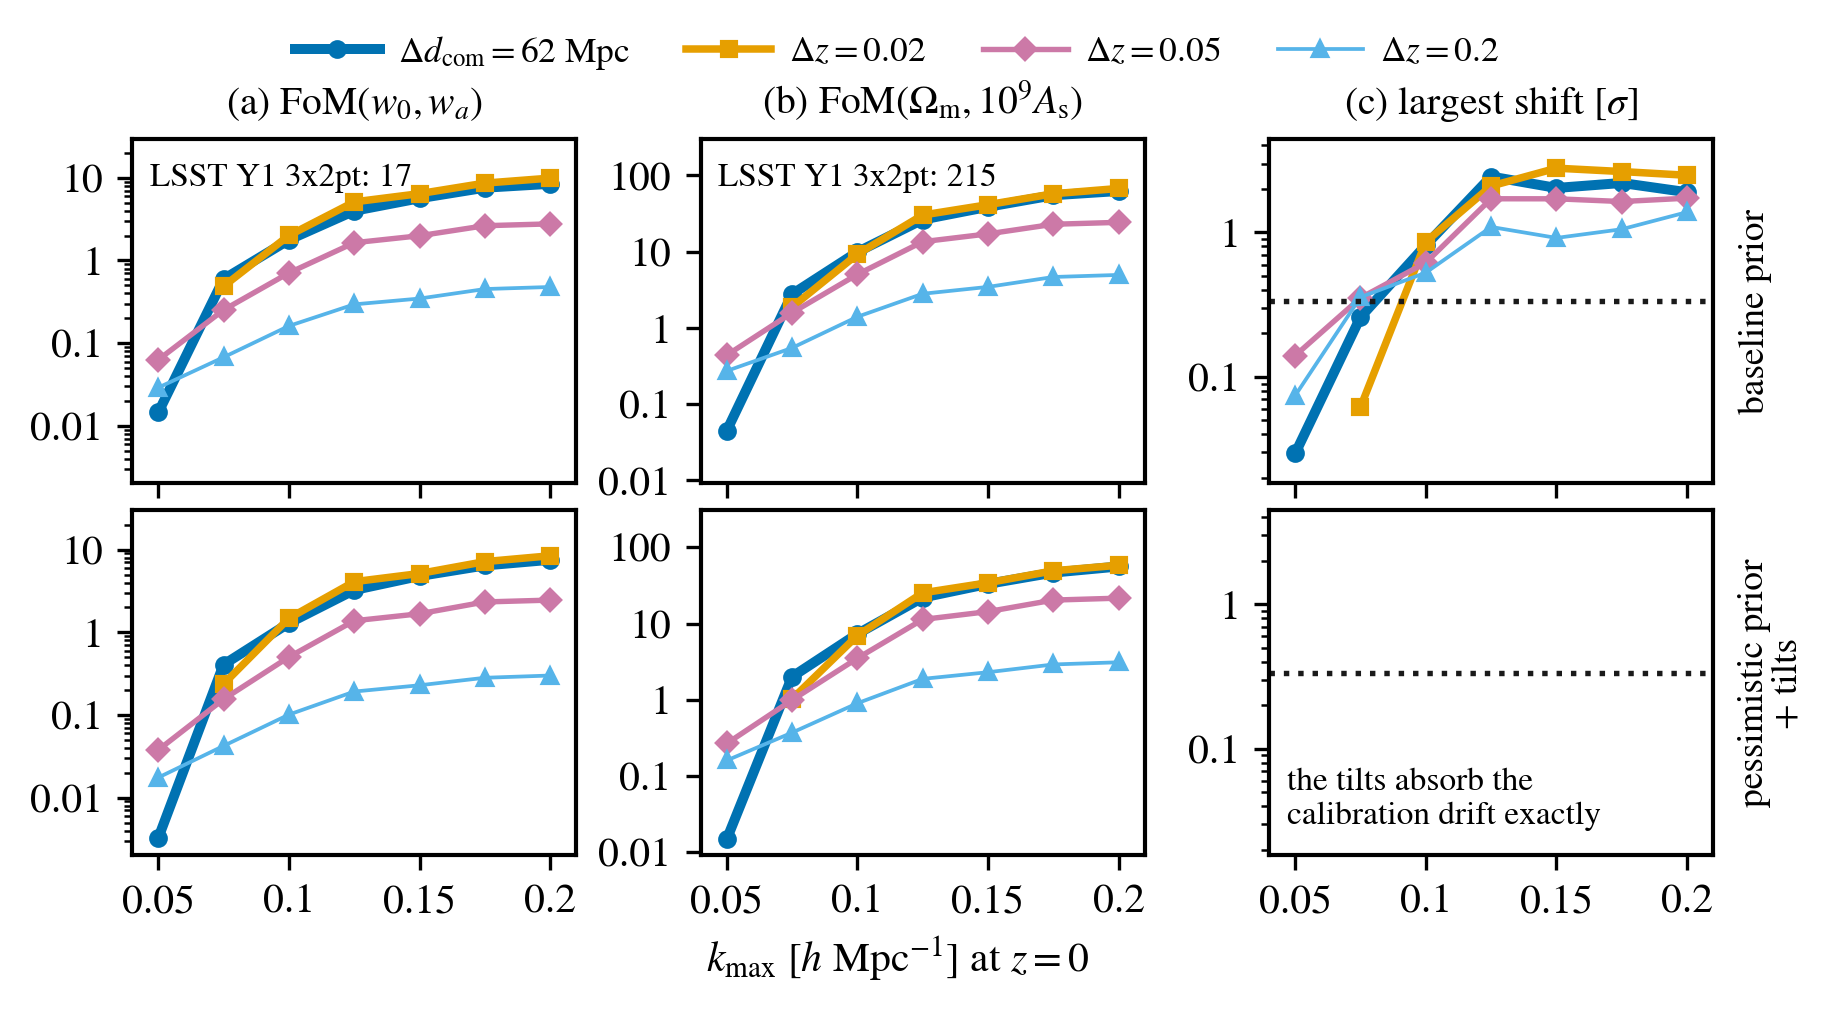

In [17]:
KMAX_LIST = [float(k) for k in KMAX_CUTS]


def per_cut(table, key, variant, prior, field=None):
    '''One entry per cut from a {(key, m, variant, prior): value} table (None: no fit).'''
    out = []
    for m in range(NK):
        entry = table[(key, m, variant, prior)]
        if entry is not None and field is not None:
            entry = entry[field]
        out.append(entry)
    return out


def layout_entry(key):
    '''The name, plotted label and color of one layout.'''
    return {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key]}


def worst_per_cut(key, variant, prior, side):
    '''The largest shift over a variant's truths outside (side 0) or inside
    (side 1) its prior and over the scores, per cut (None: no fit).'''
    out = []
    for scores in per_cut(SCORES, key, variant, prior):
        out.append(None if scores is None
                   else worst_score(split_scores(scores, variant)[side])[0])
    return out


def break_entry(key, variant, prior):
    '''The break point of one variant and prior, with the truth that sets it.'''
    entry = BREAK[(key, variant, prior)]
    failure = None
    if entry['failure'] is not None:
        cut, value, family, score = entry['failure']
        failure = {'kmax': cut, 'value': value, 'truth': family, 'score': score}
    return {'kmax': entry['kmax'], 'passes_every_cut': entry['passes_every_cut'],
            'failure': failure}


fom_data = {
    'about': ('Two scenarios of DESI C_gg alone against the scale cut k_max [h/Mpc; the '
              'z = 0 value of a per-bin cut at k_max/D(zbar_i), D the growth factor, by '
              'the UV-fraction criterion, alpha = 0.05, within the shipped mask, computed '
              'on the paper fiducial]: the baseline linear-bias prior with model B (key '
              'B) and the pessimistic prior with model B + tilts (key B tilts; '
              'notes/higher_order_bias); the figure draws these two rows. fom = '
              'FoM(w0, wa) and fom_om_as = FoM(Omega_m, 10^9 A_s), each '
              'det(marginalized 2x2 covariance)^(-1/2), for every variant and prior '
              '(independent = free); null where a cut leaves no fit. shift: per cut, the '
              'shift of a fit of each variant to each truth, by Fisher linear response, '
              '(w0, wa) in units of the fit\'s ellipse, Omega_m and A_s in their own '
              'sigma; the truths are alpha_2 at +-1 sigma of its prior (0.5/k_max^2), '
              'SN2 = +-5 units of f_sat sigma_sat^2/nbar, the b2 and bs2 offsets at '
              '+-1 sigma of model B\'s widths, and the calibration drift, the offsets '
              'linear in redshift across each group with zero mean, changing by '
              'calibration_drift (the offsets to first order). The truths inside the '
              'model\'s own prior (in_prior_families: alpha_2, SN2 and the offsets) are '
              'reported, never held to shift_threshold; the calibration drift is '
              'tested. worst: the largest shift over the tested truths; worst_in_prior: '
              'the largest over the truths inside the prior. break: the largest k_max '
              'with worst below shift_threshold there and at every smaller fitted cut, '
              'and the truth and score that fail first (kmax null: the smallest fitted '
              'cut fails). LSST Y1 3x2pt references from the lsst_y1 project. Written '
              'by EXAMPLE_EVALUATE_FISHER_MODEL.ipynb.'),
    'kmax_h_per_Mpc': KMAX_LIST, 'shift_threshold': SHIFT_THRESHOLD,
    'in_prior_families': {model: list(f) for model, f in IN_PRIOR_FAMILIES.items()},
    'scenarios': SCENARIOS, 'priors': FIT_PRIORS, 'prior_labels': PRIOR_LABELS,
    'variants': VARIANTS, 'params': ['w0wa', *SINGLE_PARAMS],
    'prior_widths': {model: {**FIXED_WIDTHS[model],
                             'counterterms': f'{COUNTERTERM_FRACTION}/k_max^2'}
                     for model in FIXED_WIDTHS},
    'truths': {'alpha2_h-2Mpc2': {'B': f'{COUNTERTERM_FRACTION}/k_max^2 (one prior width)'},
               'SN2_units': SN2_TRUTH, 'offsets': 'one sigma of the model B widths'},
    'calibration_drift': CAL_DRIFT,
    'lsst_y1_3x2pt_fom': LSST_Y1_SRD_FOM,
    'lsst_y1_3x2pt_fom_om_as': LSST_Y1_SRD_FOM_OM_AS,
    'layouts': [{**layout_entry(key),
                 'fom': {v: {p: per_cut(FOM, key, v, p, 'fom') for p in FIT_PRIORS}
                         for v in VARIANTS},
                 'fom_om_as': {v: {p: per_cut(FOM, key, v, p, 'fom_om_as')
                                   for p in FIT_PRIORS}
                               for v in VARIANTS},
                 'shift': {v: {p: per_cut(SCORES, key, v, p) for p in FIT_PRIORS}
                           for v in VARIANTS},
                 'worst': {v: {p: worst_per_cut(key, v, p, 0) for p in FIT_PRIORS}
                           for v in VARIANTS},
                 'worst_in_prior': {v: {p: worst_per_cut(key, v, p, 1) for p in FIT_PRIORS}
                                    for v in VARIANTS},
                 'break': {v: {p: break_entry(key, v, p) for p in FIT_PRIORS}
                           for v in VARIANTS}}
                for key in LAYOUTS],
}

folder = NOTE_PLOTS + 'fom_kmax_models'
script = folder + '/plot_fom_kmax_models.py'
if not os.path.exists(script):
    raise RuntimeError(f'{script} is missing: the folder needs its plot script')
with open(folder + '/data.json', 'w') as f:
    json.dump(fom_data, f, indent=1)
# the standalone redraw: isolated mode, and a RuntimeWarning (a NaN in a
# reduction, say) stops the script
subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
display(Image(filename=folder + '/fom_kmax_models.png', width=760))

## 9. The summary model: the paper model on the pessimistic prior

The summary note, `notes/bias_model_summary`, quotes one configuration, the
paper model, at every cut: model B + tilts without $\alpha_2$ (its group
values and tilts fixed at 0), with all seven $\sigma_v$ prior widths
multiplied by $s = 6$ (`PAPER_SIGV_SCALE`, `without_alpha2`), on the
pessimistic linear-bias prior. $\alpha_2$ is about 99% degenerate with
$\sigma_v$ on these kernels, and with the $\sigma_v$ priors widened a fit
without $\alpha_2$ absorbs a DESI-size $\alpha_2$ (section 11, items 4, 5
and 8). The paper yamls `EXAMPLE_EVALUATE1`–`4.yaml` hold this model, and
section 4 checked that their $\sigma_v$ priors are these widened widths. This
section
collects what that one model gives, layout by layout and cut by cut, prints
it, and writes the data of one-column figures of the summary note, each into
its own folder under `notes/bias_model_summary/plots/` (the free-per-bin
comparison below adds `summary_fom_untied`, whose dotted line is the version
with per-bin widths equal to the group widths):

- `summary_fom_kmax`: ${\rm FoM}(w_0, w_a)$ and ${\rm FoM}(\Omega_m, 10^9 A_s)$
  (section 6);
- `summary_prior_draws`: the pessimistic-prior draws of the correlated-prior
  note's `prior_draws` figure (its bottom row), copied from that folder's
  `data.json`;
- `summary_pair_threshold`: the paper model's FoMs when only the cross pairs
  above an overlap threshold are kept (section 11, item 7, which computes it).

The cell prints the largest shift of $(w_0, w_a)$, of $\Omega_m$ and of $A_s$
over two sets of fixed truths (`paper_truths`), without a figure. Inside the
model's prior, reported without a threshold: $\mathrm{SN}_2 = \pm5$ and the
offsets at $\pm1\sigma$ of model B's widths. Tested against $\sigma/3$: the
two $\alpha_2$ truths the model lacks, $\pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$ in
every group (`ALPHA2_TRUTH`, DESI's prior width) and one model B prior width,
$\pm 0.5/k_\mathrm{max}^2$ (the truth of section 7), and the calibration drift, which the
tilts absorb exactly; then the break point, the largest cut below which every
tested shift stays under $\sigma/3$, and every failing cut.

The cell also prints $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$ of
$(w_0, w_a)$, $\Omega_m$ and $A_s$ when every bin's linear bias follows its
group's known drift (the $r < 19.5$ flux limit in BGS, a conserved population
elsewhere, `bias_drift`) plus a residual drawn from the pessimistic prior, the
accuracy test of the correlated-prior note; the summary note quotes its
largest values in a sentence, without a figure.

The statistic is the exact average over the truths and the data noise. With
$A$ the fit's response per unit fractional
deviation $\delta_i$ of bin $i$'s linear bias ($b_2$ and $b_{s^2}$ follow $b_1$
through the calibrations), $\delta^0$ the known drift and $S$ the residual
covariance of the pessimistic prior,
$$\langle\chi^2_w\rangle = (A_w\delta^0)^\mathsf{T} C_w^{-1} (A_w\delta^0)
 + \mathrm{tr}\,[C_w^{-1}(A_w S A_w^\mathsf{T} + N_w)],$$
with $N_w$ the $(w_0, w_a)$ block of $F^{-1}F_0F^{-1}$, the share of the data
noise and of the Gaussian priors ($F_0$ the Fisher matrix without the
linear-bias precision), and $n_\mathrm{dof} = 2$; for $\Omega_m$ and $A_s$ the
same with the parameter's own row and $n_\mathrm{dof} = 1$. A value of 1 means
honest error bars.

In [18]:
sys.path.insert(0, NOTE_PLOTS)
import make_theory_data as bias_theory

# the configuration of the summary note: the paper model, model B + tilts
# without alpha_2 (its group values and tilts fixed at 0, so the sigma_v carry
# the line-of-sight damping alone) and with every Gaussian sigma_v prior width
# times PAPER_SIGV_SCALE (section 2), on the pessimistic linear-bias prior. The
# factor covers the alpha_2 truth of section 11 (item 5) on every layout and cut.
SUMMARY_VARIANT, SUMMARY_PRIOR = 'B tilts noA2 sv x6', 'pessimistic'
# an experiment kept for comparison, not the paper model: the two BGS groups
# (BGS0, BGS1) x2, every LRG and ELG group x6 (BGSX2_VARIANT)
BGSX2_SIGV_SCALES = {'bgs': 2.0, 'lrg': 6.0, 'elg': 6.0}
BGSX2_VARIANT = 'B tilts noA2 sv BGSx2'
# the paper model of the correlated-prior note (alpha_2 free, the sigma_v
# widths of the exploration fits): the growth-tied comparison below belongs
# to that note's record and stays on it
V2_VARIANT = 'B tilts'
# the truths inside the paper model's prior, reported and never held to
# SHIFT_THRESHOLD; every other truth is tested: both alpha_2 truths, a term
# the model lacks, and the calibration drift, which its tilts absorb
PAPER_IN_PRIOR = ('SN2', 'offsets')
# its figures go to the summary note, one folder each
SUMMARY_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/bias_model_summary/plots/'
# the known drift laws of the accuracy test: a conserved population in every
# group, replaced in BGS by the r < 19.5 flux limit
DRIFT_LAWS = ['conserved', 'flux_limit']


def bias_drift(key, law):
    '''The fractional deviation of every bin's b1 from B_g/D(z) under a known
    drift (make_theory_data.py of the correlated-prior note); the higher-order
    biases follow b1.'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    delta = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        if law == 'conserved':
            b_center = fiducial[leader]/bias_theory.growth(z.mean())[0]
            bias = bias_theory.conserved_bias(z, z.mean(), b_center)
        elif law == 'flux_limit' and name == 'BGS':
            bias = bias_theory.bgs_flux_limit_bias(z)
        else:
            continue
        delta[idx] = bias_theory.deviation_from_tied(z, bias)
    return delta


def known_drift(key):
    '''delta^0 of the accuracy test: the conserved population, with the BGS
    flux limit in the BGS group.'''
    delta = bias_drift(key, 'conserved')
    bgs = bias_groups(key)[0][2]
    delta[bgs] = bias_drift(key, 'flux_limit')[bgs]
    return delta


def honesty(system, delta0, S, truth_variant=None):
    '''sqrt(<chi2>/n_dof) of one fit under truths delta0 + residual ~ N(0, S).

    The truths move every bin's amplitude: their data change comes from the
    per-bin amplitude columns of truth_variant (None: the fit's own variant;
    a growth-tied fit, which has one amplitude per group, takes them from
    the per-bin variant it ties).

    Returns:
      {'w0wa' or p: {'error_inflation', 'coverage', 'drift_only'}}: the
      statistic, the probability that the truth falls inside the fit's
      one-sigma region (for one parameter 2 Phi(1/s) - 1 is exact only
      without drift, so the coverage is quoted for (w0, wa) and the single
      parameters from the same Gaussian error), and the shift of the drift
      alone in sigma.
    '''
    key = system['key']
    if truth_variant is None:
        truth_variant = system['variant']
    M = COLUMNS[(key, truth_variant)][0]
    nbins = len(BIN_ZBAR[key])
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    A_w, A_p = responses(system, M[:, -nbins:]*beta[None, :])
    noise = system['F_inv'] @ system['F0'] @ system['F_inv']
    Ci, iw = system['Ci'], system['iw']
    d_w = A_w @ delta0
    K_w = np.outer(d_w, d_w) + A_w @ S @ A_w.T + noise[np.ix_(iw, iw)]
    out = {'w0wa': {'error_inflation': float(np.sqrt(np.trace(Ci @ K_w)/2.0)),
                    'coverage': coverage_2d(Ci, K_w),
                    'drift_only': float(np.sqrt(d_w @ Ci @ d_w))}}
    for p, i in system['ip'].items():
        a = A_p[p]
        drift_p = float(a @ delta0)
        # the scatter about the drift, in units of the parameter's sigma
        spread = float(a @ S @ a + noise[i, i]/system['sigma'][p]**2)
        # the probability that |drift + scatter| < 1 sigma for a Gaussian
        # error of mean drift_p and variance spread
        r = np.sqrt(2.0*spread)
        coverage = 0.5*(scipy.special.erf((1.0 - drift_p)/r)
                        + scipy.special.erf((1.0 + drift_p)/r))
        out[p] = {'error_inflation': float(np.sqrt(drift_p**2 + spread)),
                  'coverage': float(coverage), 'drift_only': abs(drift_p)}
    return out


def without_alpha2(columns, sigv_scale=PAPER_SIGV_SCALE, key=None):
    '''A variant's map without the alpha_2 parameters and with wider sigma_v.

    Arguments:
      columns    = (M, names, tags) in variant_columns' format.
      sigv_scale = the factor on every Gaussian sigma_v prior width, or
                   {sample: factor} with sample 'bgs', 'lrg' or 'elg'.
      key        = the layout (a LAYOUTS key) when sigv_scale is per sample:
                   its bin table names the sample of each sigma_v leader.

    Returns:
      (M, names, tags) without the columns DESI_A2_<g> and DESI_TA2_<g> (the
      group values and tilts of alpha_2, fixed at 0) and with every Gaussian
      sigma_v tag widened by sigv_scale. The other columns keep their order,
      so the per-bin amplitudes stay last.
    '''
    M, names, tags = columns
    keep = [j for j, n in enumerate(names) if not n.startswith(('DESI_A2_', 'DESI_TA2_'))]
    new_tags = []
    for j in keep:
        tag = tags[j]
        if 'SIGV' in names[j].upper() and tag[0] == 'gauss':
            factor = sigv_scale
            if isinstance(sigv_scale, dict):
                # DESI_SIGV_<n> leads the group whose first bin is bin n
                sample = TABLES[key]['bins'][int(names[j].split('_')[-1]) - 1][1]
                factor = sigv_scale[sample]
            tag = ('gauss', tag[1]*factor)
        new_tags.append(tag)
    return M[:, keep], [names[j] for j in keep], new_tags


def paper_truths(key, m):
    '''{truth name: base vector} of the fixed truths of the paper model at cut m.

    The truths of model B in section 7 (variant_truths: alpha_2 at one model
    B prior width, SN2, the offsets at model B's widths and the calibration
    drift), with that alpha_2 truth named 'alpha2 model B width', plus the
    DESI-size alpha_2 truth, +-ALPHA2_TRUTH h^-2 Mpc^2 in every group ('alpha2
    12.5'). The two alpha_2 truths coincide at k_max = 0.2.
    '''
    out = {}
    for name, c in variant_truths(key, V2_VARIANT, m).items():
        family, sign = name.rsplit(' ', 1)
        out[('alpha2 model B width' if family == 'alpha2' else family) + ' ' + sign] = c
    a2 = block_vector(key, {'a2': ALPHA2_TRUTH})
    out[f'alpha2 {ALPHA2_TRUTH:g} +'] = a2
    out[f'alpha2 {ALPHA2_TRUTH:g} -'] = -a2
    return out


def paper_split(shift):
    '''(tested, in_prior): the scores of the truths outside and inside the
    paper model's prior (PAPER_IN_PRIOR), as two {truth: {score: value}}.'''
    tested = {t: v for t, v in shift.items() if truth_family(t) not in PAPER_IN_PRIOR}
    inside = {t: v for t, v in shift.items() if truth_family(t) in PAPER_IN_PRIOR}
    return tested, inside


for key in LAYOUTS:
    COLUMNS[(key, SUMMARY_VARIANT)] = without_alpha2(COLUMNS[(key, V2_VARIANT)])
    COLUMNS[(key, BGSX2_VARIANT)] = without_alpha2(COLUMNS[(key, V2_VARIANT)],
                                                   BGSX2_SIGV_SCALES, key)
S_PESS = {key: residual_covariance(key, BIAS_ASSUMPTIONS['pessimistic']) for key in LAYOUTS}
DELTA0 = {key: known_drift(key) for key in LAYOUTS}

# the summary model at every cut: FoMs, shifts (every truth, then the tested
# ones and those inside the prior) and the statistic
SUMMARY = {}
for key in LAYOUTS:
    for m in range(NK):
        truths = paper_truths(key, m)
        system, status = fit_system(key, m, SUMMARY_VARIANT, SUMMARY_PRIOR)
        if system is None:
            SUMMARY[(key, m)] = None
            continue
        shift = truth_scores(system, truths)
        tested, inside = paper_split(shift)
        SUMMARY[(key, m)] = {'fom': system['fom'], 'fom_om_as': system['fom_om_as'],
                             'shift': shift, 'tested': tested, 'in_prior': inside,
                             'honesty': honesty(system, DELTA0[key], S_PESS[key])}

SCORED = ['w0wa', *SINGLE_PARAMS]


def summary_rows(reduce):
    '''One row per layout and score, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for score in SCORED:
            rows[(key, score)] = {float(k): (np.nan if SUMMARY[(key, m)] is None
                                             else reduce(SUMMARY[(key, m)], score))
                                  for m, k in enumerate(KMAX_CUTS)}
    return pd.DataFrame(rows).T


def largest(entry, score):
    return max(v[score] for v in entry['shift'].values())


def largest_truth(entry, score):
    '''The truth family that sets the largest shift of one score.'''
    best = max(entry['shift'], key=lambda t: entry['shift'][t][score])
    return truth_family(best)


def largest_in(field):
    '''largest over the truths of one field of a SUMMARY entry ('tested' or
    'in_prior'), as a summary_rows reduce.'''
    return lambda entry, score: max(v[score] for v in entry[field].values())


def largest_truth_in(field):
    '''The truth family that sets the largest shift of one field.'''
    def get(entry, score):
        return truth_family(max(entry[field], key=lambda t: entry[field][t][score]))
    return get


def paper_break(key):
    '''The break point of the paper model on one layout, as safe_kmax: the
    largest cut below which every score of every tested truth stays under
    SHIFT_THRESHOLD there and at every smaller fitted cut (None: the smallest
    fitted cut fails), and every failing cut as (cut, value, truth family,
    score).'''
    best, failures = None, []
    for m, kmax in enumerate(KMAX_CUTS):
        entry = SUMMARY[(key, m)]
        if entry is None:
            continue
        value, truth, score = worst_score(entry['tested'])
        if value >= SHIFT_THRESHOLD:
            failures.append((float(kmax), value, truth_family(truth), score))
        elif not failures:
            best = float(kmax)
    return {'kmax': best, 'passes_every_cut': not failures, 'failures': failures}


PAPER_BREAK = {key: paper_break(key) for key in LAYOUTS}
TESTED_FAMILIES = [f'alpha2 {ALPHA2_TRUTH:g}', 'alpha2 model B width', 'calibration drift']

print(f'the paper model ({SUMMARY_VARIANT}: model B + tilts without alpha_2, sigma_v '
      f'widths x{PAPER_SIGV_SCALE:g}) on the pessimistic prior. Tested truths (alpha_2 = '
      f'+-{ALPHA2_TRUTH:g}, alpha_2 at one model B width, the calibration drift): '
      'largest shift [sigma]; columns: k_max')
display(summary_rows(largest_in('tested')))
print('the tested truth family that sets it')
display(summary_rows(largest_truth_in('tested')))
rows = {}
for key in LAYOUTS:
    for family in TESTED_FAMILIES:
        rows[(key, family)] = {
            float(k): (np.nan if SUMMARY[(key, m)] is None else
                       max(v[s] for t, v in SUMMARY[(key, m)]['tested'].items()
                           if truth_family(t) == family for s in SCORED))
            for m, k in enumerate(KMAX_CUTS)}
print('each tested truth family: the largest of the three scores [sigma]; columns: k_max')
display(pd.DataFrame(rows).T)
print(f'break point: every tested score below sigma/3 (= {SHIFT_THRESHOLD:.3f})')
for key in LAYOUTS:
    entry = PAPER_BREAK[key]
    if entry['passes_every_cut']:
        print(f'  {key}: passes every cut to {KMAX_CUTS[-1]:g}')
        continue
    first = 'fails at the smallest cut' if entry['kmax'] is None else f'safe to {entry["kmax"]:g}'
    print(f'  {key}: {first}; failing cuts: ' + '; '.join(
        f'{c:g} ({fam}, {sc} {v:.2f})' for c, v, fam, sc in entry['failures']))
print('truths inside the prior (SN2, the offsets at model B\'s widths): largest shift '
      '[sigma], reported, not tested; columns: k_max')
display(summary_rows(largest_in('in_prior')))
print('the in-prior truth family that sets it')
display(summary_rows(largest_truth_in('in_prior')))
print('the paper model on the pessimistic prior, truths = known drifts + pessimistic '
      'scatter: sqrt(<chi2>/n_dof) (1 = honest error bars); columns: k_max')
display(summary_rows(lambda e, s: e['honesty'][s]['error_inflation']))
print('the same truths: coverage of the 68.3% region')
display(summary_rows(lambda e, s: e['honesty'][s]['coverage']))
print('the same truths: the shift of the drift alone [sigma]')
display(summary_rows(lambda e, s: e['honesty'][s]['drift_only']))

the paper model (B tilts noA2 sv x6: model B + tilts without alpha_2, sigma_v widths x6) on the pessimistic prior. Tested truths (alpha_2 = +-12.5, alpha_2 at one model B width, the calibration drift): largest shift [sigma]; columns: k_max


0.05    0.075    0.1     0.125    0.15     0.175     0.2  
Delta d_com = 62 Mpc w0wa    0.1633   1.591   0.8642  0.4673   0.3126   0.2024    0.1545
                     omegam 0.03372  0.8731   0.3944  0.2393   0.1897   0.1474    0.1171
                     As_1e9 0.07905   1.644   0.8775  0.4189   0.2215    0.143    0.1113
Delta z = 0.02       w0wa       NaN   1.145    1.308  0.7142   0.5091   0.3797    0.3153
                     omegam     NaN  0.6976   0.8647  0.3967   0.2996   0.2091    0.1707
                     As_1e9     NaN    1.25    1.016  0.2528   0.1503  0.08436   0.03967
Delta z = 0.05       w0wa   0.08511  0.1631   0.1428   0.202   0.1617   0.1549    0.1085
                     omegam 0.09185   0.217   0.1249  0.1599   0.1049     0.13    0.0918
                     As_1e9  0.1322  0.3419   0.2833  0.3399   0.2601   0.1888    0.1353
Delta z = 0.2        w0wa   0.07019 0.02475  0.03302 0.02337  0.01367  0.01231   0.01005
                     omegam 0.02459 0.01035 0.008949 0.01311 0.006096 0.003733 9.115e-05
                     As_1e9  0.0575 0.05049  0.02905 0.03139  0.02938   0.0455   0.04892

the tested truth family that sets it


0.05                  0.075                 0.1                   0.125                 0.15                  0.175                 0.2  
Delta d_com = 62 Mpc w0wa    alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
                     omegam  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
                     As_1e9  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
Delta z = 0.02       w0wa                     NaN  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
                     omegam                   NaN  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
                     As_1e9                   NaN  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
Delta z = 0.05       w0wa    alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
                     omegam  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
                     As_1e9  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width
Delta z = 0.2        w0wa    alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width           alpha2 12.5
                     omegam  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width           alpha2 12.5
                     As_1e9  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width  alpha2 model B width

each tested truth family: the largest of the three scores [sigma]; columns: k_max


0.05      0.075     0.1       0.125     0.15      0.175     0.2  
Delta d_com = 62 Mpc alpha2 12.5             0.0102    0.2312    0.2194    0.1825    0.1759    0.1549    0.1545
                     alpha2 model B width    0.1633     1.644    0.8775    0.4673    0.3126    0.2024    0.1545
                     calibration drift    4.197e-13 2.625e-13  3.92e-12 2.583e-12 8.945e-13 1.912e-12 7.596e-13
Delta z = 0.02       alpha2 12.5                NaN    0.1758    0.3269     0.279    0.2864    0.2907    0.3153
                     alpha2 model B width       NaN      1.25     1.308    0.7142    0.5091    0.3797    0.3153
                     calibration drift          NaN 3.112e-13 7.485e-13 1.375e-12 1.694e-12 2.219e-12 2.383e-12
Delta z = 0.05       alpha2 12.5           0.008263   0.04807   0.07083    0.1328    0.1463    0.1446    0.1353
                     alpha2 model B width    0.1322    0.3419    0.2833    0.3399    0.2601    0.1888    0.1353
                     calibration drift    3.098e-13 9.771e-13 7.448e-13 1.081e-12 3.736e-12 7.621e-13 1.372e-12
Delta z = 0.2        alpha2 12.5           0.004387    0.0071  0.008256   0.01226   0.01652   0.03483   0.04892
                     alpha2 model B width   0.07019   0.05049   0.03302   0.03139   0.02938    0.0455   0.04892
                     calibration drift    5.996e-13 1.026e-12 1.344e-12 8.285e-13  9.38e-13 3.683e-12 4.845e-12

... (6 outputs left out)

the same truths: coverage of the 68.3% region


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc w0wa   0.6827 0.6827 0.6827 0.6803 0.6814 0.6691 0.6786
                     omegam 0.6827 0.6827 0.6827 0.6807 0.6819 0.6682 0.6785
                     As_1e9 0.6827 0.6827 0.6827 0.6812  0.682 0.6815 0.6818
Delta z = 0.02       w0wa      NaN 0.6825 0.6815 0.6805 0.6805 0.6713 0.6743
                     omegam    NaN 0.6824 0.6812 0.6808 0.6808 0.6704 0.6725
                     As_1e9    NaN 0.6825 0.6819 0.6805  0.681 0.6812 0.6811
Delta z = 0.05       w0wa   0.6826 0.6826 0.6737 0.6769 0.6784 0.6711 0.6724
                     omegam 0.6827 0.6826 0.6714 0.6753  0.678 0.6684 0.6701
                     As_1e9 0.6827 0.6827 0.6805 0.6809 0.6813  0.681 0.6812
Delta z = 0.2        w0wa   0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827
                     omegam 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827
                     As_1e9 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827

the same truths: the shift of the drift alone [sigma]


0.05      0.075     0.1       0.125     0.15      0.175     0.2  
Delta d_com = 62 Mpc w0wa    0.004036  0.008227   0.01012    0.1154   0.08503    0.2769    0.1502
                     omegam  0.002214  0.003494    0.0121   0.09125   0.05617    0.2459    0.1324
                     As_1e9  0.001991  0.004946  0.006782   0.07938   0.05169   0.06952   0.06214
Delta z = 0.02       w0wa         NaN   0.03227   0.08083    0.1098    0.1108    0.2526    0.2156
                     omegam       NaN   0.03362   0.07936   0.08835   0.08806    0.2267    0.2057
                     As_1e9       NaN   0.02843   0.05792   0.09485   0.08306   0.07919   0.08192
Delta z = 0.05       w0wa     0.01882    0.0203    0.2243    0.1791    0.1536    0.2549    0.2401
                     omegam   0.01234   0.02104    0.2173    0.1751    0.1389    0.2444     0.229
                     As_1e9  0.005658   0.01048   0.09497   0.08513   0.07508   0.08275   0.07954
Delta z = 0.2        w0wa   8.034e-13 2.174e-12 2.983e-12 5.919e-13 3.266e-12 3.036e-12 3.361e-12
                     omegam 3.844e-13 9.577e-13 3.266e-12 9.074e-14 3.675e-12 2.314e-12 1.921e-13
                     As_1e9 6.921e-13 9.406e-13 9.153e-13 5.225e-13 5.196e-13 8.272e-13 1.564e-12

**The growth-tied prior under the correlated-prior note's higher-order
model.** The same truths (the known drifts plus the pessimistic scatter) are
fitted with model B + tilts ($\alpha_2$ free, the $\sigma_v$ widths of the
exploration fits: `V2_VARIANT`, the paper model of
`notes/correlated_bias_prior_v2`) on the growth-tied linear-bias prior: every bin of a DESI group
follows the group amplitude, $b_{1,i} = B_g/D(\bar z_i)$, with no tilt and
no residual, so each group keeps one amplitude parameter (`growth_tied_columns`:
the group's per-bin amplitude columns summed). The higher-order sector is
unchanged. `honesty` scores it as above, with the truths acting through the
per-bin amplitude columns. The same model on the correlated (pessimistic)
prior is printed next to it for contrast. The figure goes to
`notes/correlated_bias_prior_v2/plots/growth_tied_kmax/` and stays on that
note's model.

model B + tilts on the growth-tied prior, truths = known drifts + pessimistic scatter: sqrt(<chi2>/n_dof); columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc w0wa    1.114  1.808  2.665  2.946  3.214  3.888  3.738
                     omegam  1.145  1.413  2.401  2.468  2.883  3.648  3.461
                     As_1e9  1.105   1.48  2.146  2.197   2.08  2.474  2.577
Delta z = 0.02       w0wa      NaN  1.386  2.989  3.998  4.136  4.281  4.506
                     omegam    NaN   1.32  2.923  3.214  3.434   3.92  4.215
                     As_1e9    NaN  1.474  3.026  3.159  2.926  3.085  3.235
Delta z = 0.05       w0wa    1.234  1.498  1.512  1.935   2.44  2.889  3.094
                     omegam  1.119  1.372  1.468  1.908  2.508  2.934  3.137
                     As_1e9  1.163  1.326  1.365  1.273  1.408  1.592  1.783
Delta z = 0.2        w0wa    1.016  1.052  1.073  1.038  1.064  1.216  1.512
                     omegam   1.03  1.098  1.131  1.052  1.106  1.363  1.807
                     As_1e9  1.006   1.02   1.03  1.034  1.047  1.109  1.405

the same fit: coverage of the 68.3% region


0.05   0.075   0.1     0.125   0.15    0.175   0.2  
Delta d_com = 62 Mpc w0wa   0.6043 0.3096  0.1827   0.174  0.1661  0.1347  0.1396
                     omegam 0.6176 0.4945  0.1798  0.1832  0.1254 0.04902 0.06337
                     As_1e9 0.6346 0.4829  0.2879  0.2432  0.2658     0.2  0.1774
Delta z = 0.02       w0wa      NaN 0.4642   0.189  0.1338  0.1293   0.125  0.1164
                     omegam    NaN 0.5409 0.09763 0.08379 0.07077  0.0387 0.02458
                     As_1e9    NaN 0.4742  0.1074 0.09173  0.1247  0.1137 0.09962
Delta z = 0.05       w0wa   0.5295 0.4007  0.3972   0.307  0.2374  0.1986  0.1803
                     omegam 0.6287 0.5264  0.4894  0.3531  0.2242  0.1279  0.1047
                     As_1e9   0.61 0.5485  0.5356  0.5633  0.5149  0.4404  0.3748
Delta z = 0.2        w0wa   0.6712 0.6463  0.6326   0.656  0.6386  0.5509  0.4301
                     omegam 0.6686 0.6368  0.6206  0.6579  0.6321  0.5139  0.3522
                     As_1e9   0.68 0.6732   0.668  0.6663  0.6603  0.6306  0.5079

model B + tilts on the correlated (pessimistic) prior, the same truths: sqrt(<chi2>/n_dof)


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc w0wa        1      1      1  1.002  1.001  1.017  1.005
                     omegam      1      1      1  1.003  1.001  1.026  1.008
                     As_1e9      1      1      1  1.002  1.001  1.002  1.002
Delta z = 0.02       w0wa      NaN      1  1.001  1.002  1.001  1.014  1.011
                     omegam    NaN      1  1.002  1.002  1.002  1.024   1.02
                     As_1e9    NaN      1  1.001  1.003  1.002  1.002  1.003
Delta z = 0.05       w0wa        1      1  1.006  1.011  1.005  1.015  1.014
                     omegam      1      1  1.011  1.024  1.009  1.027  1.024
                     As_1e9      1      1  1.002  1.004  1.004  1.003  1.002
Delta z = 0.2        w0wa        1      1      1      1      1      1      1
                     omegam      1      1      1      1      1      1      1
                     As_1e9      1      1      1      1      1      1      1

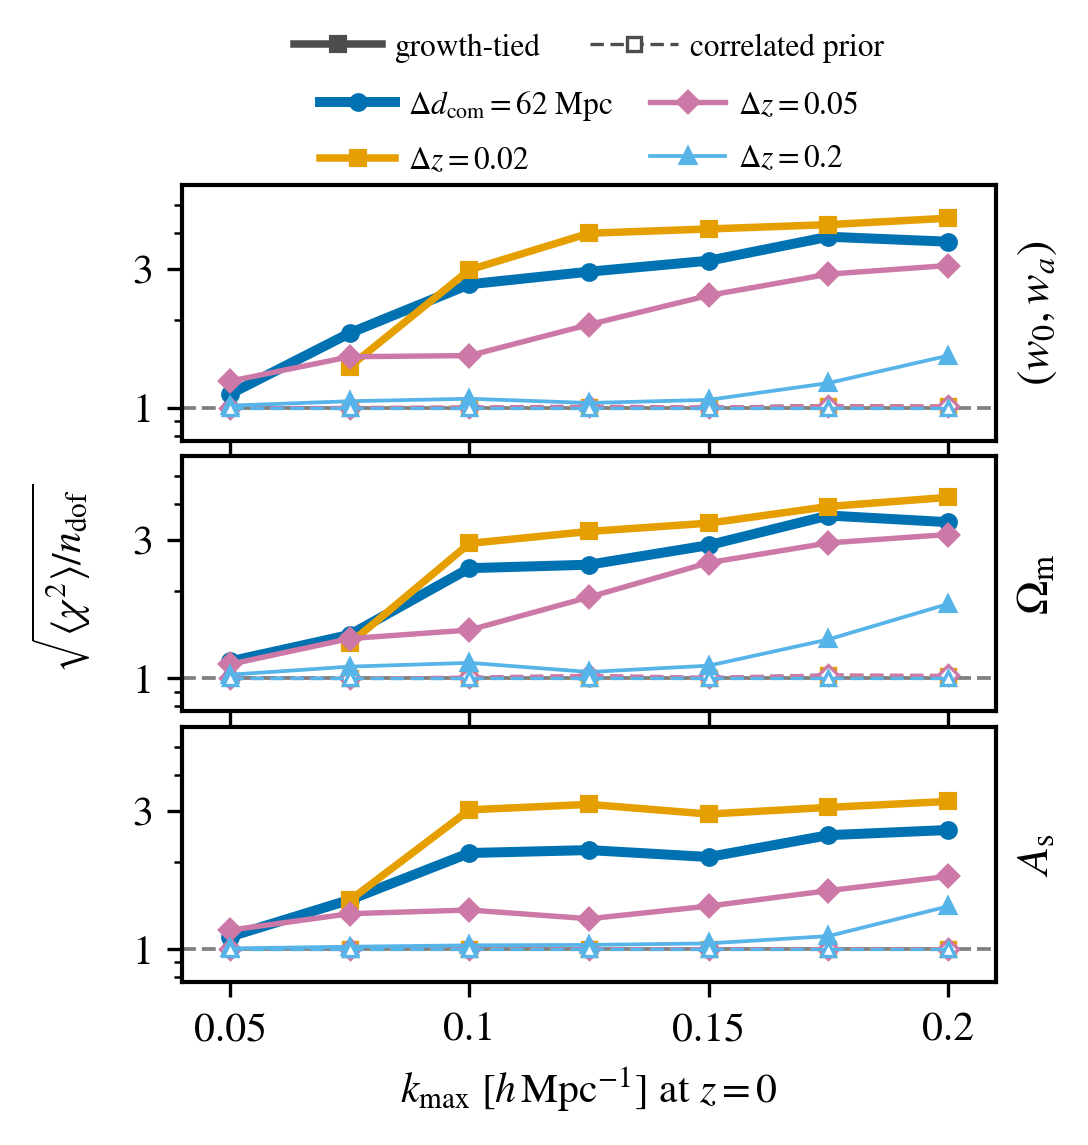

In [19]:
GROWTH_TIED_VARIANT = 'B tilts growth-tied'


def growth_tied_columns(key, variant):
    '''The map M of a variant with the per-bin amplitudes tied to their group.

    Under the growth-tied prior every bin of group g has beta_i = B_g, so the
    column of B_g is the sum of the group's per-bin amplitude columns; the
    other columns and their priors are the variant's.

    Returns:
      (M, names, tags) in variant_columns' format, one amplitude per group.
    '''
    M, names, tags = COLUMNS[(key, variant)]
    nbins = len(BIN_ZBAR[key])
    columns = []
    out_names = []
    out_tags = []
    for j in range(len(names) - nbins):
        columns.append(M[:, j])
        out_names.append(names[j])
        out_tags.append(tags[j])
    amplitudes = M[:, len(names) - nbins:]
    for name, leader, idx in bias_groups(key):
        columns.append(amplitudes[:, idx].sum(axis=1))
        out_names.append(leader)
        out_tags.append(('flat',))
    return np.column_stack(columns), out_names, out_tags


# the correlated-prior note's model (V2_VARIANT, alpha_2 free): this
# comparison is that note's figure and stays on it
for key in LAYOUTS:
    COLUMNS[(key, GROWTH_TIED_VARIANT)] = growth_tied_columns(key, V2_VARIANT)

# sqrt(<chi2>/n_dof) of the growth-tied fit and of the same model on the
# correlated pessimistic prior at every cut; 'tied' adds no linear-bias
# precision in fit_system (one free amplitude per group)
GROWTH_TIED = {}
for key in LAYOUTS:
    for m in range(NK):
        system, status = fit_system(key, m, GROWTH_TIED_VARIANT, 'tied')
        correlated, status_c = fit_system(key, m, V2_VARIANT, SUMMARY_PRIOR)
        if system is None or correlated is None:
            GROWTH_TIED[(key, m)] = None
            continue
        GROWTH_TIED[(key, m)] = {
            'growth_tied': honesty(system, DELTA0[key], S_PESS[key],
                                   truth_variant=V2_VARIANT),
            'correlated': honesty(correlated, DELTA0[key], S_PESS[key])}


def growth_tied_rows(fit, field):
    '''One row per layout and score, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for score in SCORED:
            row = {}
            for m, k in enumerate(KMAX_CUTS):
                entry = GROWTH_TIED[(key, m)]
                row[float(k)] = np.nan if entry is None else entry[fit][score][field]
            rows[(key, score)] = row
    return pd.DataFrame(rows).T


print('model B + tilts on the growth-tied prior, truths = known drifts + pessimistic '
      'scatter: sqrt(<chi2>/n_dof); columns: k_max')
display(growth_tied_rows('growth_tied', 'error_inflation'))
print('the same fit: coverage of the 68.3% region')
display(growth_tied_rows('growth_tied', 'coverage'))
print('model B + tilts on the correlated (pessimistic) prior, the same truths: '
      'sqrt(<chi2>/n_dof)')
display(growth_tied_rows('correlated', 'error_inflation'))

folder = NOTE_PLOTS + 'growth_tied_kmax'
script = folder + '/plot_growth_tied_kmax.py'
if not os.path.exists(script):
    raise RuntimeError(f'{script} is missing: the folder needs its plot script')
growth_tied_data = {
    'about': ('How well the quoted error bars of the paper\'s higher-order model cover '
              'the truth with the growth-tied linear-bias prior, against the same model '
              'on the correlated (pessimistic) prior, at every cut. Fit: model B + tilts; '
              'growth-tied: every bin of a DESI group follows B_g/D(zbar_i), one amplitude '
              'per group, no tilt and no residual; correlated prior: the pessimistic prior '
              '(L = 0.05, 3% per group). Truths: the known drifts (a conserved population, '
              'the r < 19.5 flux limit in BGS) plus a residual drawn from the pessimistic '
              'prior. eta = sqrt(<chi2>/n_dof), averaged exactly over the truths and the '
              'data noise (n_dof = 2 for (w0, wa), 1 for Omega_m or A_s; 1 = honest error '
              'bars); coverage: the probability that the truth falls inside the fit\'s '
              '68.3% region. Written by EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 9) '
              f'at the {DERIVATIVE_TIER} derivative tier.'),
    'kmax_h_per_Mpc': [float(k) for k in KMAX_CUTS],
    'params': SCORED,
    'derivative_tier': DERIVATIVE_TIER,
    'layouts': [],
}
for key in LAYOUTS:
    entry = {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
             'eta': {}, 'coverage': {}}
    for fit in ('growth_tied', 'correlated'):
        entry['eta'][fit] = {}
        entry['coverage'][fit] = {}
        for score in SCORED:
            entry['eta'][fit][score] = [
                None if GROWTH_TIED[(key, m)] is None
                else GROWTH_TIED[(key, m)][fit][score]['error_inflation'] for m in range(NK)]
            entry['coverage'][fit][score] = [
                None if GROWTH_TIED[(key, m)] is None
                else GROWTH_TIED[(key, m)][fit][score]['coverage'] for m in range(NK)]
    growth_tied_data['layouts'].append(entry)
with open(folder + '/data.json', 'w') as f:
    json.dump(growth_tied_data, f, indent=1)
subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
display(Image(filename=folder + '/growth_tied_kmax.png', width=420))

**What the grouping buys.** The summary model ties its higher-order bias
parameters within each tracer group (one offset and one tilt per group) and
correlates the linear biases of neighboring bins through the pessimistic
prior. The comparison frees every bias parameter in every bin: $b_1$ per bin
with a flat prior (the free linear-bias prior), and $\Delta_2$, $\Delta_s$,
$\alpha_0$, $\mathrm{SN}_0$ and $\mathrm{SN}_2$ with one value per bin,
no group offsets and no tilts (`free_bin_columns`). Every version below keeps
the summary model's $\sigma_v$ priors and has no $\alpha_2$. The per-bin
columns are the per-bin derivatives already computed: the Jacobian is the
identity. Each per-bin
higher-order parameter keeps the Gaussian width the model gives its group
parameter, so the ratio
${\rm FoM}(\text{free per bin})/{\rm FoM}(\text{summary model})$ isolates what
the grouping buys. The model is not a special case of this fit: its tilts are
flat, and its group offset lets the common shift of a group's bins vary by a
full width, against a width over $\sqrt{N}$ for the mean of $N$ per-bin values.
A second version therefore adds the per-bin parameters on top of the model's
group offsets and tilts (`nested`); it contains the summary model, so its FoM
can only be lower. A third version puts flat priors on every per-bin
higher-order parameter; its Fisher matrix is reported with the directions the
pseudo-inverse drops (`stable_inverse`) and the condition number of the scaled
matrix, and it is drawn only if it is well defined.

Two more versions make the comparison fair to the grouping. $N_g$ independent
per-bin values of width $w_g$ give their mean a width $w_g/\sqrt{N_g}$, so
(`sqrtn`) every per-bin higher-order parameter gets the width $w_g\sqrt{N_g}$,
$N_g$ the number of bins of the group in the layout (kept bands or not): the
group's common shift then has the model's width $w_g$. The second (`sqrtn_tilt`)
adds a flat linear tilt per group for $\Delta_2$, $\Delta_s$ and $\alpha_0$,
as the model has ($\mathrm{SN}_0$ and $\mathrm{SN}_2$ never tilt). Its
prior covariance on the per-bin values, $N_g w_g^2$ times the identity plus a free
trend, is at least the model's, $w_g^2$ times the matrix of ones plus a free
trend, and $b_1$ is free per bin, so its FoM can only be lower than the model's;
a check line prints its largest ratio.

A last version (`correlated_residuals`) asks what independent stochastic
residuals of the higher-order terms cost. It keeps the model (the group offsets
and flat tilts of $\Delta_2$, $\Delta_s$ and $\alpha_0$, one
$\mathrm{SN}_0$ and $\mathrm{SN}_2$ per group) and adds a per-bin residual
$\epsilon_{X,i}$ to each of $\Delta_2$, $\Delta_s$ and $\alpha_0$,
with the prior form of $b_1$'s: a Gaussian correlated in redshift,
$\langle\epsilon_i\epsilon_j\rangle = w_X^2 e^{-|\bar z_i - \bar z_j|/L}$ with
$L = 0.05$ and $w_X$ the model's group width at the cut, applied as the
projected precision that charges only the deviation from the group's line (the
construction of `group_bias_precision` with a free tilt), so the group's common
shift and trend keep the model's freedom. A group of one or two bins gets no
residual. $b_1$ keeps the model's pessimistic prior, so the residuals are the only
difference from the model; every other version frees $b_1$ per bin. The nested
version is the same idea with $L \to 0$ and no projection (and $b_1$ free per
bin): independent per-bin values of width $w_X$, whose mean and trend the
Gaussian also constrains. The residual
trends duplicate the flat group tilts, so the pseudo-inverse drops those
directions; a table prints how many and their largest component on the scored
parameters, which must vanish.

A sixth version (`constant_per_sample`) is the assumption of an earlier draft
of this analysis: every thin bin inside a wide DESI sample has the same bias,
constant in redshift. It keeps one value per group of every bias parameter,
$b_1$ (constant, not $B_g/D(\bar z_i)$), $\Delta_2$, $\Delta_s$, $\alpha_0$,
$\mathrm{SN}_0$ and $\mathrm{SN}_2$, with the model's priors on the
group values ($b_1$ flat, the others the model B widths), no tilts and no
per-bin residuals. $b_2$ and $b_{s^2}$ follow $b_1$ through the calibrations, so
they are constant too. Its $b_1$ column is the sum over the group's bins of each
bin's total $b_1$ column (`constant_sample_columns`), so it needs no new
evaluation. A constant cannot follow the fiducial's own evolution,
$b_{1,i} = B_g/D(\bar z_i)$: its $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$
counts each bin's deviation of the fiducial from a group constant as part of
every truth's departure (`fiducial_evolution`), on top of the known drifts and
the pessimistic scatter. The group constant itself lies in the span of the
group's $b_1$ column and drops out in linear response. The tables print its FoM
ratio, the statistic, the coverage of the $1\sigma$ region, its largest shift
over the fixed truths and the shift of the evolution alone.

Every version is also scored as the model is: $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$
and the coverage of the $1\sigma$ region under the known drifts plus the
pessimistic scatter, and the largest shift over the fixed truths. Every version
but the constant one holds the per-bin amplitude columns, so the fiducial's own
evolution lies in the span of its columns (a check prints the part outside the
span for each version) and the fiducial is a point of its parameter space: no
evolution term enters. A version with $b_1$ free per bin absorbs any per-bin
departure of $b_1$, so its statistic is 1 and its coverage $68.3\%$ by
construction; the comparison is in its FoM.

In [20]:
# the per-group families of the paper model: model B's without alpha_2
FREE_BIN_FAMILIES = [f for f in MODEL_FAMILIES['B'] if f != 'A2']


def free_bin_columns(key, flat, nested=False, sqrtn=False, group_tilts=False):
    '''The map M from the base columns to the free-per-bin parameters (D = B M):
    the cosmology and velocity dispersions as in the summary model (no alpha_2,
    the sigma_v widths of without_alpha2), one parameter per bin and family of
    FREE_BIN_FAMILIES (the identity on the per-bin base columns), and the
    per-bin amplitudes of variant_columns.

    Arguments:
      flat   = True puts flat priors on the per-bin higher-order parameters;
               False gives each the Gaussian width of its family (prior_widths).
      nested = True keeps the group offsets and tilts of model B + tilts and adds
               the per-bin parameters on top of them, so the fit contains the
               summary model.
      sqrtn  = True widens each per-bin width by sqrt(N_g), N_g the number of
               bins of the group in the layout (kept bands or not): the mean of
               the group's per-bin values then has the group width.
      group_tilts = True adds a flat linear tilt in redshift per group for each
               family that tilts in the model (TILT_OF; SN0 and SN2 never tilt).
    '''
    M, names, tags = without_alpha2(variant_columns(key, 'B tilts' if nested else 'B'))
    blocks = BASE[key]['blocks']
    nbins = len(BIN_ZBAR[key])
    keep = [j for j, tag in enumerate(tags) if nested or tag[0] != 'family']
    head = [j for j in keep if not names[j].startswith('DESI_B1_')]
    amps = [j for j in keep if names[j].startswith('DESI_B1_')]
    columns = [M[:, j] for j in head]
    new_names = [names[j] for j in head]
    new_tags = [tags[j] for j in head]
    zbar = BIN_ZBAR[key]
    size = np.zeros(nbins)
    for name, leader, idx in bias_groups(key):
        size[idx] = len(idx)
    for family in FREE_BIN_FAMILIES:
        block = blocks[FAMILY_BLOCK[family]]
        for i in range(nbins):
            col = np.zeros(BASE[key]['n'])
            col[block[i]] = 1.0
            columns.append(col)
            new_names.append(f'DESI_{family}_bin{i + 1}')
            if flat:
                new_tags.append(('flat',))
            elif sqrtn:
                new_tags.append(('family_scaled', family, float(np.sqrt(size[i]))))
            else:
                new_tags.append(('family', family))
        if group_tilts and family in TILT_OF:
            for name, leader, idx in bias_groups(key):
                if len(idx) > 1:
                    col = np.zeros(BASE[key]['n'])
                    col[block[idx]] = zbar[idx] - zbar[idx].mean()
                    columns.append(col)
                    new_names.append(f'DESI_{TILT_OF[family]}_{name}')
                    new_tags.append(('flat',))
    columns += [M[:, j] for j in amps]
    new_names += [names[j] for j in amps]
    new_tags += [tags[j] for j in amps]
    return np.column_stack(columns), new_names, new_tags


def scaled_spectrum(key, m, variant, prior):
    '''The eigenvalue range of a fit's Fisher matrix on its live parameters,
    scaled to unit diagonal, and the number of directions below PINV_RTOL (as
    fit_system builds the matrix).'''
    gram = GRAM[key][m]
    M, names, tags = COLUMNS[(key, variant)]
    F_data = M.T @ gram @ M
    F = F_data + np.diag(prior_diagonal(tags, variant.split()[0], KMAX_CUTS[m]))
    nx = len(names) - len(BIN_ZBAR[key])
    if prior in BIAS_ASSUMPTIONS:
        F[nx:, nx:] += PRECISION[(key, prior)]
    if (key, variant) not in INFO_REF:
        INFO_REF[(key, variant)] = np.einsum('ij,ij->j', M, GRAM[key]['shipped'] @ M)
    reference = INFO_REF[(key, variant)] + np.diag(F) - np.diag(F_data)
    live = [j for j in range(len(names)) if F[j, j] > NO_DATA_RTOL*reference[j]]
    Fl = F[np.ix_(live, live)]
    s = 1.0/np.sqrt(np.diag(Fl))
    w = np.linalg.eigvalsh(Fl*s[:, None]*s[None, :])
    return {'n_live': len(live), 'min_over_max': float(w.min()/w.max()),
            'dropped': int(np.sum(w <= PINV_RTOL*w.max()))}


# the free-per-bin fits, {short name: (label, free_bin_columns arguments)}:
# per-bin parameters with the model's widths (replacing the groups), the same
# with flat priors, the per-bin parameters on top of the summary model's group
# offsets and tilts (nested), the per-bin widths times sqrt(N_g) (sqrtn), and
# the same plus a flat tilt per group (sqrtn_tilt)
FREE_BIN_VERSIONS = {
    'gauss': ('B free bins', {'flat': False}),
    'flat': ('B free bins flat', {'flat': True}),
    'nested': ('B tilts free bins', {'flat': False, 'nested': True}),
    'sqrtn': ('B free bins sqrtn', {'flat': False, 'sqrtn': True}),
    'sqrtn_tilt': ('B free bins sqrtn tilt', {'flat': False, 'sqrtn': True,
                                              'group_tilts': True}),
}
for key in LAYOUTS:
    for label, arguments in FREE_BIN_VERSIONS.values():
        COLUMNS[(key, label)] = free_bin_columns(key, **arguments)

FREE_BINS = {}
for key in LAYOUTS:
    for m in range(NK):
        if SUMMARY[(key, m)] is None:
            FREE_BINS[(key, m)] = None
            continue
        entry = {}
        for short, (label, arguments) in FREE_BIN_VERSIONS.items():
            system, status = fit_system(key, m, label, 'independent')
            spectrum = scaled_spectrum(key, m, label, 'independent')
            entry[short] = {'status': status, **spectrum,
                            'fom': None if system is None else system['fom'],
                            'fom_om_as': None if system is None else system['fom_om_as'],
                            'pinv_dropped': None if system is None else system['dropped'],
                            'overlap': None if system is None else system['overlap']}
        FREE_BINS[(key, m)] = entry


# The correlated residuals on top of the model: the summary model (group
# offsets and flat tilts of Delta_2, Delta_s and alpha_0; SN0 and SN2 per
# group; no alpha_2) plus a per-bin residual eps_X,i of each of Delta_2,
# Delta_s and alpha_0. Each residual has the prior form of b1's: a Gaussian
# correlated in redshift, <eps_i eps_j> = w_X^2 exp(-|zbar_i - zbar_j|/L) with
# L = RESIDUAL_L and w_X the model's group width at the cut, applied as the
# projected precision that charges only the deviation from the group's line
# (group_bias_precision's construction with a free tilt): the common shift and
# the trend of a group stay the model's. A group of one or two bins gets no
# residual. b1 keeps the model's prior (the pessimistic prior: B_g and s_g free,
# the correlated residual of width 3% over L = 0.05), so the only difference
# from the model is the higher-order residuals; the other versions free b1 per
# bin. The nested version is the same idea with L -> 0 and no projection.
RESIDUAL_L = 0.05
RESIDUAL_FAMILIES = ['DB2', 'DBS', 'A0']
RESIDUAL_VARIANT = 'B tilts correlated residuals'


def residual_columns(key):
    '''The map M of the model plus the per-bin residuals, and where they sit.

    Returns:
      ((M, names, tags), positions): positions[(family, group)] = (the
      parameter indices of the group's residuals, the group's bin indices).
    '''
    M, names, tags = COLUMNS[(key, SUMMARY_VARIANT)]
    nbins = len(BIN_ZBAR[key])
    blocks = BASE[key]['blocks']
    columns = [M[:, j] for j in range(len(names) - nbins)]
    new_names = list(names[:len(names) - nbins])
    new_tags = list(tags[:len(names) - nbins])
    positions = {}
    for family in RESIDUAL_FAMILIES:
        block = blocks[FAMILY_BLOCK[family]]
        for name, leader, idx in bias_groups(key):
            if len(idx) <= 2:
                continue
            where = []
            for i in idx:
                col = np.zeros(BASE[key]['n'])
                col[block[i]] = 1.0
                columns.append(col)
                new_names.append(f'DESI_E{family}_{i + 1}')
                new_tags.append(('flat',))
                where.append(len(new_names) - 1)
            positions[(family, name)] = (np.array(where), idx)
    for j in range(len(names) - nbins, len(names)):
        columns.append(M[:, j])
        new_names.append(names[j])
        new_tags.append(tags[j])
    return (np.column_stack(columns), new_names, new_tags), positions


RESIDUAL_POSITIONS = {}


def residual_precision(key, kmax):
    '''The projected precision of the correlated residuals at one cut.'''
    widths = prior_widths('B', kmax)
    n_par = len(COLUMNS[(key, RESIDUAL_VARIANT)][1])
    P = np.zeros((n_par, n_par))
    zbar = BIN_ZBAR[key]
    for (family, name), (where, idx) in RESIDUAL_POSITIONS[key].items():
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z)), z - z.mean()])
        Q = np.linalg.inv(widths[family]**2*np.exp(-np.abs(z[:, None] - z[None, :])/RESIDUAL_L))
        QU = Q @ U
        P[np.ix_(where, where)] += Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


for key in LAYOUTS:
    COLUMNS[(key, RESIDUAL_VARIANT)], RESIDUAL_POSITIONS[key] = residual_columns(key)
    EXTRA_PRECISION[(key, RESIDUAL_VARIANT)] = residual_precision
for key in LAYOUTS:
    for m in range(NK):
        if FREE_BINS[(key, m)] is None:
            continue
        system, status = fit_system(key, m, RESIDUAL_VARIANT, SUMMARY_PRIOR)
        FREE_BINS[(key, m)]['correlated_residuals'] = {
            'status': status,
            'fom': None if system is None else system['fom'],
            'fom_om_as': None if system is None else system['fom_om_as'],
            'pinv_dropped': None if system is None else system['dropped'],
            'overlap': None if system is None else system['overlap']}


# One constant value per wide sample, the assumption of an earlier draft: every
# bin of a DESI group has the same b1, constant in redshift (not B_g/D(z)),
# and the same Delta_2, Delta_s, alpha_0, SN0 and SN2, with the model's
# priors on the group values (b1 flat, the others the model B widths, the
# sigma_v widths of the summary model), no alpha_2, no tilts and no per-bin
# residuals. b2 and bs2 follow b1 through
# the calibrations, so they are constant too. 'tied' adds no linear-bias
# precision in fit_system.
CONSTANT_VARIANT = 'B constant per sample'


def constant_sample_columns(key):
    '''The map M of the constant-per-sample fit (D = B M).

    The columns of model B without tilts and without alpha_2 (variant_columns
    through without_alpha2), with the per-bin amplitudes replaced by one b1
    per group. A constant b1 moves every bin of
    the group by the same amount, so its column is the sum over the group's
    bins of each bin's total b1 column, dm/db1_i + b2L'(b1_i) dm/db2_i - 4/7
    dm/dbs2_i: the per-bin amplitude column of variant_columns times
    beta_i/b1_i (the amplitude column is the derivative per unit of
    beta_i = B_g, and b1_i = beta_i/D(zbar_i)).

    Returns:
      (M, names, tags) in variant_columns' format, one flat b1 per group.
    '''
    M, names, tags = without_alpha2(COLUMNS[(key, 'B')])
    nbins = len(BIN_ZBAR[key])
    head = len(names) - nbins
    b1 = derivs[key]['b1']
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    total = M[:, head:]*(beta/b1)[None, :]
    columns = [M[:, j] for j in range(head)]
    out_names = list(names[:head])
    out_tags = list(tags[:head])
    for name, leader, idx in bias_groups(key):
        columns.append(total[:, idx].sum(axis=1))
        out_names.append(f'DESI_B1CONST_{name}')
        out_tags.append(('flat',))
    return np.column_stack(columns), out_names, out_tags


def fiducial_evolution(key):
    '''The fiducial's departure from one b1 per group, per bin, as a
    fractional deviation (the unit of the truths' delta): (b1_i - <b1>_g)/b1_i
    with b1_i = B_g/D(zbar_i) and <b1>_g the group's mean. A constant fit
    cannot follow it, so it counts as part of every truth's departure; the
    group constant itself (the mean here, or any other) lies in the span of
    the group's b1 column and drops out in linear response.'''
    b1 = derivs[key]['b1']
    out = np.zeros(len(b1))
    for name, leader, idx in bias_groups(key):
        out[idx] = (b1[idx] - b1[idx].mean())/b1[idx]
    return out


def evolution_vector(key):
    '''fiducial_evolution in base coordinates, through the per-bin amplitude
    columns as honesty applies a truth's delta.'''
    M = COLUMNS[(key, SUMMARY_VARIANT)][0]
    nbins = len(BIN_ZBAR[key])
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    return (M[:, -nbins:]*beta[None, :]) @ fiducial_evolution(key)


for key in LAYOUTS:
    COLUMNS[(key, CONSTANT_VARIANT)] = constant_sample_columns(key)
for key in LAYOUTS:
    for m in range(NK):
        if FREE_BINS[(key, m)] is None:
            continue
        system, status = fit_system(key, m, CONSTANT_VARIANT, 'tied')
        entry = {'status': status,
                 'fom': None if system is None else system['fom'],
                 'fom_om_as': None if system is None else system['fom_om_as'],
                 'pinv_dropped': None if system is None else system['dropped'],
                 'overlap': None if system is None else system['overlap']}
        if system is not None:
            # the known drifts and the fiducial's evolution, plus the scatter
            entry['honesty'] = honesty(system, DELTA0[key] + fiducial_evolution(key),
                                       S_PESS[key], truth_variant=SUMMARY_VARIANT)
            shifts = truth_scores(system, paper_truths(key, m))
            entry['largest'] = {s: max(v[s] for v in shifts.values()) for s in SCORED}
            entry['evolution'] = truth_scores(
                system, {'evolution': evolution_vector(key)})['evolution']
        FREE_BINS[(key, m)]['constant_per_sample'] = entry

# The statistic, the coverage and the largest shift of the other versions,
# under the summary model's truths (the known drifts plus the pessimistic
# scatter). Each holds the per-bin amplitude columns, so the fiducial's
# evolution lies in the span of its columns (span_outside, printed below)
# and needs no term of its own.
UNTIED_FITS = {short: (label, 'independent')
               for short, (label, arguments) in FREE_BIN_VERSIONS.items() if short != 'flat'}
UNTIED_FITS['correlated_residuals'] = (RESIDUAL_VARIANT, SUMMARY_PRIOR)
for key in LAYOUTS:
    for m in range(NK):
        if FREE_BINS[(key, m)] is None:
            continue
        for short, (label, prior) in UNTIED_FITS.items():
            system, status = fit_system(key, m, label, prior)
            if system is None:
                continue
            FREE_BINS[(key, m)][short]['honesty'] = honesty(
                system, DELTA0[key], S_PESS[key], truth_variant=SUMMARY_VARIANT)
            shifts = truth_scores(system, paper_truths(key, m))
            FREE_BINS[(key, m)][short]['largest'] = {s: max(v[s] for v in shifts.values())
                                                     for s in SCORED}


def span_outside(key, variant):
    '''The part of the fiducial's evolution (evolution_vector) outside the
    span of a variant's columns, |e - M c|/|e| at the least-squares c, in
    base coordinates: 0 when the variant can follow it.'''
    M = COLUMNS[(key, variant)][0]
    e = evolution_vector(key)
    c = np.linalg.lstsq(M, e, rcond=None)[0]
    return float(np.linalg.norm(e - M @ c)/np.linalg.norm(e))


def free_bin_rows(version, reduce):
    '''One row per layout and quantity, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for what in ('fom', 'fom_om_as'):
            rows[(key, what)] = {float(k): (np.nan if FREE_BINS[(key, m)] is None
                                            else reduce(FREE_BINS[(key, m)][version],
                                                        SUMMARY[(key, m)], what))
                                 for m, k in enumerate(KMAX_CUTS)}
    return pd.DataFrame(rows).T


def ratio(free, model, what):
    return np.nan if free[what] is None else free[what]/model[what]


print('every bias parameter free per bin (the model\'s Gaussian widths on the '
      'higher-order ones): FoM / FoM of the summary model; columns: k_max')
display(free_bin_rows('gauss', ratio))
for short, what in (('sqrtn', 'per-bin widths times sqrt(N_g), no group offsets, '
                                'no tilts'),
                    ('sqrtn_tilt', 'per-bin widths times sqrt(N_g) plus a flat tilt '
                                     'per group')):
    print(f'{what}: FoM / FoM of the summary model; columns: k_max')
    display(free_bin_rows(short, ratio))
    print(f'{what}: FoM')
    display(free_bin_rows(short, lambda f, e, w: np.nan if f[w] is None else f[w]))
print('the summary model: FoM')
display(free_bin_rows('gauss', lambda f, e, w: e[w]))
worst_tilt = max(FREE_BINS[(key, m)]['sqrtn_tilt'][w]/SUMMARY[(key, m)][w]
                 for key in LAYOUTS for m in range(NK) if FREE_BINS[(key, m)] is not None
                 for w in ('fom', 'fom_om_as'))
print(f'check: the largest FoM ratio of the sqrt(N_g) widths with tilts = {worst_tilt:.4f} '
      '(at most 1: the fit is at least as loose as the model)')
print('the per-bin parameters on top of the summary model\'s group offsets and '
      'tilts (a fit that contains the summary model): FoM / FoM of the summary model')
display(free_bin_rows('nested', ratio))
print('correlated residuals on top of the model (per-bin Delta_2, Delta_s and alpha_0 '
      f'residuals correlated over L = {RESIDUAL_L}, charging only the deviation '
      'from each group\'s line; b1 on the model\'s pessimistic prior): FoM / FoM of the '
      'summary model')
display(free_bin_rows('correlated_residuals', ratio))
print('the same: directions dropped by the pseudo-inverse (the residual trends that '
      'duplicate the flat group tilts; fom rows) and their largest component on the '
      'scored parameters (fom_om_as rows)')
display(free_bin_rows('correlated_residuals',
                      lambda f, e, what: f['pinv_dropped'] if what == 'fom' else f['overlap']))
print('one constant value per wide sample (b1 constant in redshift, one value per '
      'group of every bias parameter, the model\'s group priors, no tilts, no '
      'residuals): FoM / FoM of the summary model')
display(free_bin_rows('constant_per_sample', ratio))


def constant_rows(get):
    '''One row per layout and score, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for score in SCORED:
            row = {}
            for m, k in enumerate(KMAX_CUTS):
                entry = (None if FREE_BINS[(key, m)] is None
                         else FREE_BINS[(key, m)]['constant_per_sample'])
                row[float(k)] = (np.nan if entry is None or 'honesty' not in entry
                                 else get(entry, score))
            rows[(key, score)] = row
    return pd.DataFrame(rows).T


print('the same fit: shift of the fiducial\'s evolution alone [sigma] (its truths '
      'below add this evolution to the known drifts)')
display(constant_rows(lambda e, s: e['evolution'][s]))

# every version scored as the model: 'model' is the summary model itself
QUALITY_VERSIONS = ['model', 'gauss', 'sqrtn', 'sqrtn_tilt', 'nested',
                    'correlated_residuals', 'constant_per_sample']


def quality_entry(key, m, version):
    '''The scores of one version at one cut, or None without a fit.'''
    if version == 'model':
        entry = SUMMARY[(key, m)]
        if entry is None:
            return None
        return {'honesty': entry['honesty'],
                'largest': {s: largest(entry, s) for s in SCORED}}
    entry = None if FREE_BINS[(key, m)] is None else FREE_BINS[(key, m)][version]
    return entry if entry is not None and 'honesty' in entry else None


def quality_rows(get, score):
    '''One row per layout and version, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for version in QUALITY_VERSIONS:
            row = {}
            for m, k in enumerate(KMAX_CUTS):
                entry = quality_entry(key, m, version)
                row[float(k)] = np.nan if entry is None else get(entry, score)
            rows[(key, version)] = row
    return pd.DataFrame(rows).T


print('check: the part of the fiducial\'s evolution outside each version\'s columns '
      '(0: in the span; the constant version cannot follow it)')
display(pd.DataFrame({key: {version: span_outside(key, variant) for version, variant in
                            [('model', SUMMARY_VARIANT)]
                            + [(s, UNTIED_FITS[s][0]) for s in UNTIED_FITS]
                            + [('constant_per_sample', CONSTANT_VARIANT)]}
                      for key in LAYOUTS}))
for score in SCORED:
    print(f'every version, truths = known drifts + pessimistic scatter (+ the evolution '
          f'for the constant one): sqrt(<chi2>/n_dof) of {score}; columns: k_max')
    display(quality_rows(lambda e, s: e['honesty'][s]['error_inflation'], score))
for score in SCORED:
    print(f'the same: coverage of the 68.3% region, {score}')
    display(quality_rows(lambda e, s: e['honesty'][s]['coverage'], score))
print('every version: largest shift over the fixed truths, the largest of the three scores '
      '[sigma]')
display(quality_rows(lambda e, s: max(e['largest'].values()), None))
print('the same with flat priors on the per-bin higher-order parameters: FoM / FoM '
      'of the summary model (NaN: no well-defined fit)')
display(free_bin_rows('flat', ratio))
print('flat version: smallest / largest eigenvalue of the scaled Fisher matrix (fom '
      'rows) and the directions below PINV_RTOL (fom_om_as rows)')
display(free_bin_rows('flat', lambda f, e, what: f['min_over_max'] if what == 'fom'
                      else f['dropped']))
print('flat version: status of each fit')
display(pd.DataFrame({key: {float(k): (None if FREE_BINS[(key, m)] is None
                                       else FREE_BINS[(key, m)]['flat']['status'])
                            for m, k in enumerate(KMAX_CUTS)} for key in LAYOUTS}).T)

every bias parameter free per bin (the model's Gaussian widths on the higher-order ones): FoM / FoM of the summary model; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc fom        1.845  1.215  1.346  1.236   1.16  1.156  1.158
                     fom_om_as  1.173  1.233  1.382   1.28  1.233  1.213  1.183
Delta z = 0.02       fom          NaN  1.476  1.537  1.215  1.194   1.16  1.149
                     fom_om_as    NaN  1.411  1.592  1.273  1.271  1.221   1.18
Delta z = 0.05       fom        1.268  1.297  1.332  1.079  1.067  1.032  1.028
                     fom_om_as  1.379  1.329  1.397  1.129  1.107  1.061  1.054
Delta z = 0.2        fom        1.425  1.275  1.359  1.086  1.101  1.104  1.097
                     fom_om_as  1.495  1.286  1.376  1.105  1.123  1.126  1.119

per-bin widths times sqrt(N_g), no group offsets, no tilts: FoM / FoM of the summary model; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc fom        1.186 0.9027 0.8917 0.9107 0.9393  0.937  0.945
                     fom_om_as 0.6119 0.8824 0.8797 0.9191 0.9469 0.9426 0.9463
Delta z = 0.02       fom          NaN 0.9179 0.8649 0.8506 0.8612 0.8631 0.8852
                     fom_om_as    NaN 0.9076 0.8624 0.8722 0.8886 0.8905 0.8986
Delta z = 0.05       fom       0.8807 0.9987 0.9158 0.9414 0.9683 0.9569 0.9576
                     fom_om_as 0.8904 0.9984 0.9135 0.9458 0.9756 0.9581 0.9609
Delta z = 0.2        fom        1.326  1.193   1.26   1.03  1.034  1.062  1.064
                     fom_om_as  1.355  1.196  1.267  1.039  1.048  1.078  1.082

per-bin widths times sqrt(N_g), no group offsets, no tilts: FoM


0.05    0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc fom       0.005873  0.5089  1.171   2.73  4.112  5.448  6.329
                     fom_om_as  0.01883    2.56  6.726   19.3  29.64  40.55  47.57
Delta z = 0.02       fom            NaN  0.3232  1.326  3.489  4.287  5.846  7.033
                     fom_om_as      NaN   1.333  5.953  21.02  28.38  39.77   47.8
Delta z = 0.05       fom        0.03842  0.1729 0.4881  1.323   1.62  2.153  2.237
                     fom_om_as   0.2824   1.144  3.473  10.95  13.83  18.38  19.11
Delta z = 0.2        fom        0.02478 0.05307 0.1348 0.2351 0.2521   0.31 0.3264
                     fom_om_as   0.2282  0.4556  1.209  2.348  2.606  3.268  3.461

... (34 outputs left out)

flat version: smallest / largest eigenvalue of the scaled Fisher matrix (fom rows) and the directions below PINV_RTOL (fom_om_as rows)


0.05       0.075      0.1        0.125      0.15       0.175      0.2  
Delta d_com = 62 Mpc fom       -2.472e-16 -2.661e-16 -2.302e-16 -2.503e-16 -1.637e-16 -2.257e-17 -1.612e-16
                     fom_om_as         44         34         29         12          8          5          4
Delta z = 0.02       fom              NaN  -4.07e-16 -2.175e-16 -1.396e-16  -1.63e-16 -1.685e-17 -1.161e-17
                     fom_om_as        NaN         34         29         18         12          5          3
Delta z = 0.05       fom       -1.424e-16 -1.922e-16 -1.269e-16 -1.068e-16 -9.281e-17 -9.908e-17 -1.302e-18
                     fom_om_as         50         36         27         20         18          8          4
Delta z = 0.2        fom       -4.251e-17 -8.887e-17 -1.185e-16 -7.733e-17 -9.711e-17 -2.338e-17 -1.246e-17
                     fom_om_as          6          8          7          6          4          3          3

flat version: status of each fit


,0.05,0.075,0.1,0.125,0.15,0.175,0.2
Delta d_com = 62 Mpc,scored parameters unconstrained,fit,fit,fit,fit,fit,fit
Delta z = 0.02,None,fit,fit,fit,fit,fit,fit
Delta z = 0.05,fit,fit,fit,fit,fit,fit,fit
Delta z = 0.2,fit,fit,fit,fit,fit,fit,fit


**What the summary model shows.**

- Its error bars are honest at every cut, on every layout:
  $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$ is at most $1.030$ ($\Omega_m$ on
  $\Delta d_\mathrm{com} = 62$ Mpc at $0.175$), the coverage of the $1\sigma$
  region at least $66.8\%$ against $68.3\%$, and the known drift alone moves no
  score by more than $0.28\sigma$. On $\Delta z = 0.2$ the free amplitude and
  tilt of every group absorb the drift exactly, and the statistic is $1$.
- The widened $\sigma_v$ absorb a DESI-size $\alpha_2$:
  $\alpha_2 = \pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$ moves no score by more than
  $0.327\sigma$ at any cut on any layout (the largest on $\Delta z = 0.02$, at
  $0.1$, and $0.315\sigma$ there at $0.2$), and the tilts absorb the calibration
  drift exactly. $\alpha_2$ at one model B prior width, $0.5/k_\mathrm{max}^2$
  ($89\,h^{-2}\,\mathrm{Mpc}^2$ at $0.075$, $50$ at $0.1$), is not absorbed at the
  smaller cuts: it moves $A_s$ by $1.64\sigma$ at $0.075$ on
  $\Delta d_\mathrm{com} = 62$ Mpc and $(w_0, w_a)$ by $1.31\sigma$ at $0.1$ on
  $\Delta z = 0.02$, and it stays above $\sigma/3$ up to $0.125$ on
  $\Delta d_\mathrm{com} = 62$ Mpc, up to $0.175$ on $\Delta z = 0.02$, and at
  $0.075$ and $0.125$ on $\Delta z = 0.05$ ($0.34\sigma$ at both); on
  $\Delta z = 0.2$ it moves no score by more than $0.07\sigma$. Under this truth
  the break point is $0.05$ on $\Delta d_\mathrm{com} = 62$ Mpc and on
  $\Delta z = 0.05$, below the smallest fitted cut on $\Delta z = 0.02$, and
  beyond $0.2$ on $\Delta z = 0.2$.
- The truths inside the prior (the offsets at model B's widths and
  $\mathrm{SN}_2$) move a score by at most $0.69\sigma$ ($\Omega_m$ on
  $\Delta z = 0.02$ at $0.1$, the offsets), and from $0.125$ on by at most
  $0.42\sigma$.
- Freeing every bias parameter in every bin with the model's widths does not
  lower the FoM on any layout: ${\rm FoM}(w_0, w_a)$ changes by a factor
  $1.22$, $1.48$, $1.30$ and $1.28$ at $0.075$ and $1.16$, $1.15$, $1.03$ and
  $1.10$ at $0.2$ ($\Delta d_\mathrm{com} = 62$ Mpc, $\Delta z = 0.02$, $0.05$,
  $0.2$). The per-bin Gaussians pin a group's common shift and its linear trend,
  which the model leaves to an offset of full width and a flat tilt. Added on
  top of the model's offsets and tilts, the per-bin parameters lower
  ${\rm FoM}(w_0, w_a)$ by a factor $0.90$, $0.85$, $0.89$ and $0.88$ at $0.075$
  and $0.94$, $0.88$, $0.94$ and $0.95$ at $0.2$. With flat priors the per-bin fit
  is singular: $3$ to $50$ directions carry no information at every cut, and on
  $\Delta d_\mathrm{com} = 62$ Mpc at $0.05$ they reach the scored parameters.
- ${\rm FoM}(w_0, w_a) = 0.564$, $0.352$, $0.173$ and $0.0445$ at $0.075$, and
  $6.70$, $7.95$, $2.34$ and $0.307$ at $0.2$ ($\Delta d_\mathrm{com} = 62$ Mpc,
  $\Delta z = 0.02$, $0.05$, $0.2$); ${\rm FoM}(\Omega_m, 10^9 A_s) = 50.3$,
  $53.2$, $19.9$ and $3.20$ at $0.2$. Both stay below the LSST Y1 3x2pt values,
  $17.26$ and $214.9$. Against model B + tilts with $\alpha_2$ free and the
  exploration $\sigma_v$ widths, ${\rm FoM}(w_0, w_a)$ changes by a factor
  $1.39$, $1.49$, $1.11$ and $1.05$ at $0.075$ and $0.89$, $0.94$, $0.95$ and
  $1.02$ at $0.2$ (section 11, item 8).

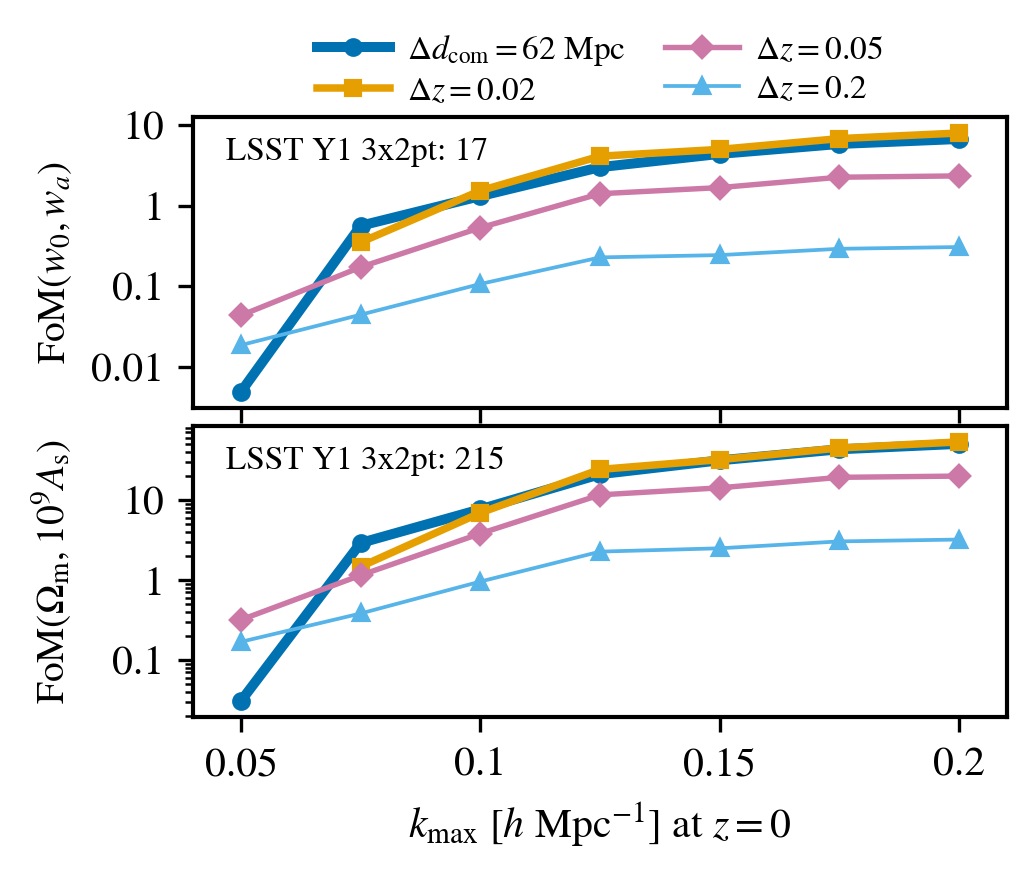

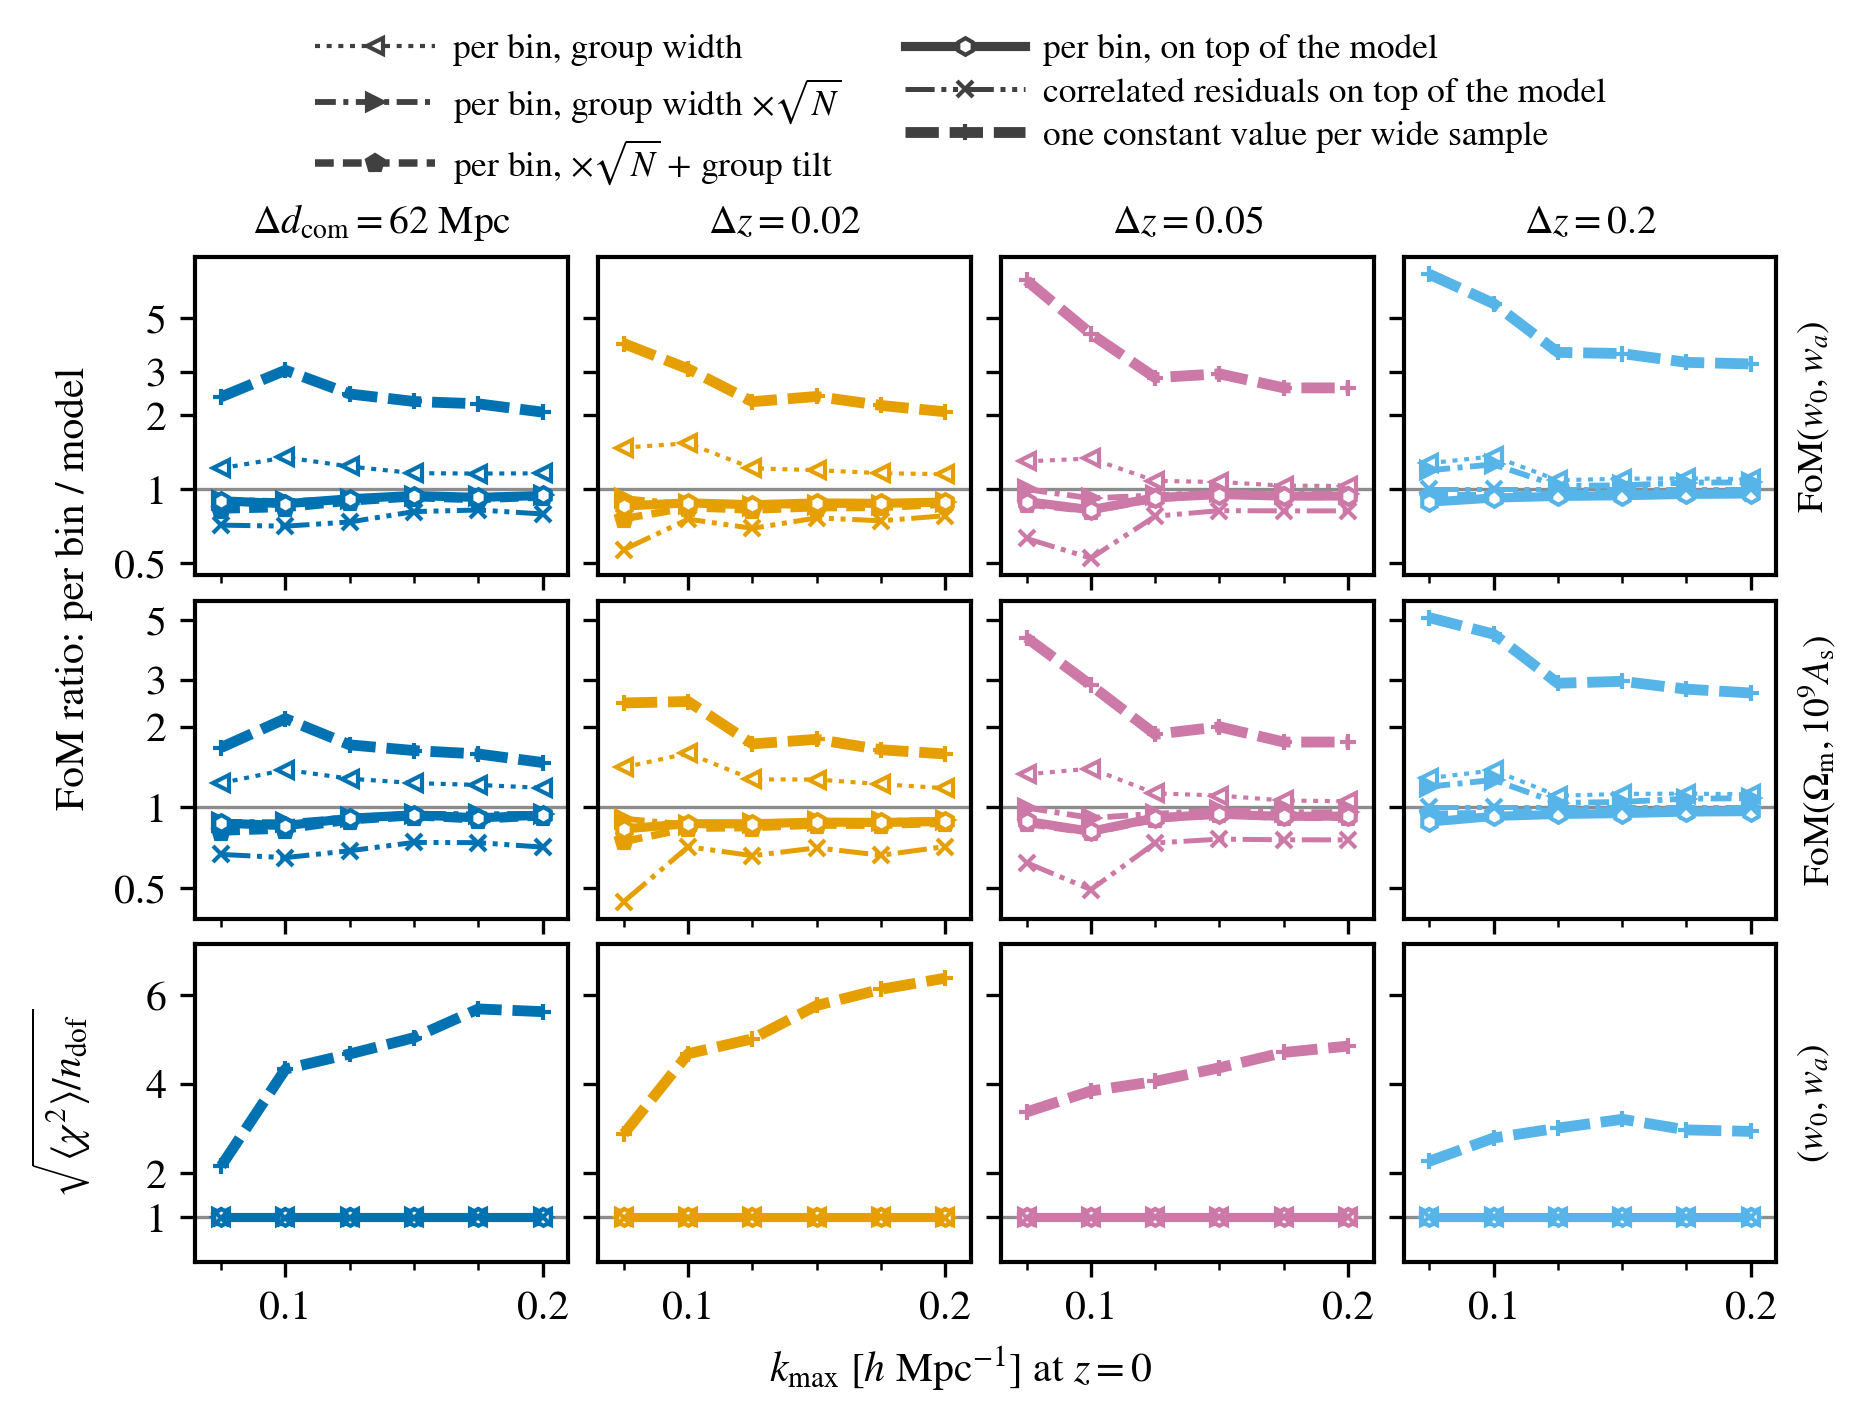

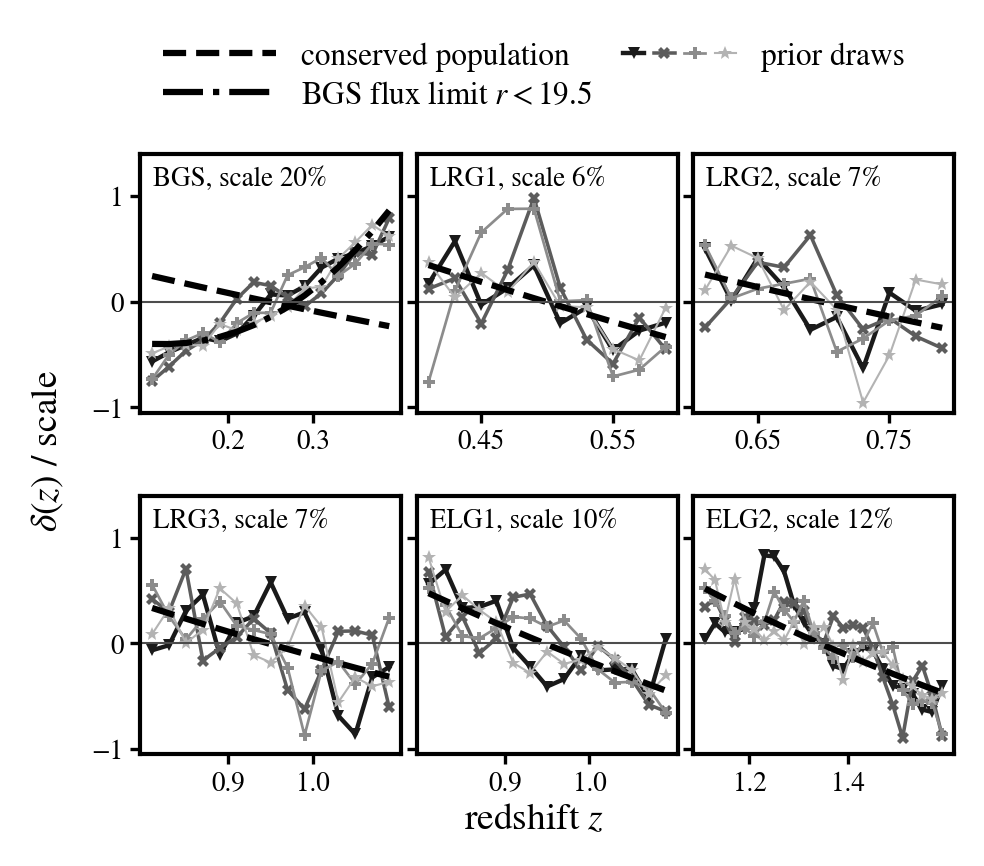

In [21]:
def summary_layouts(per_cut):
    '''The layout list of a summary data.json: name, label, color and the
    entries per_cut(key) adds.'''
    return [{**layout_entry(key), **per_cut(key)} for key in LAYOUTS]


def by_cut(key, get):
    '''One entry per cut (None: no fit).'''
    return [None if SUMMARY[(key, m)] is None else get(SUMMARY[(key, m)])
            for m in range(NK)]


SUMMARY_ABOUT = ('the paper model, model B + tilts without alpha_2 (notes/higher_order_bias: '
                 'the b2 and bs2 offsets and the counterterm alpha_0 per group, each with a '
                 'straight line in redshift, flat priors on the tilts, SN0 and SN2 per '
                 'group; alpha_2 = 0 in every bin) with the seven sigma_v prior widths '
                 f'{PAPER_SIGV_SCALE:g} times those of the exploration fits, on the '
                 'pessimistic linear-bias prior, DESI '
                 'C_gg alone, against the scale cut k_max [h/Mpc; the z = 0 value of a '
                 'per-bin cut at k_max/D(zbar_i), D the growth factor, by the UV-fraction '
                 'criterion, alpha = 0.05, within the shipped mask]; null where a cut '
                 'leaves no fit. Written by EXAMPLE_EVALUATE_FISHER_MODEL.ipynb.')
summary_common = {'kmax_h_per_Mpc': KMAX_LIST, 'variant': SUMMARY_VARIANT,
                  'prior': SUMMARY_PRIOR,
                  'prior_widths': {**FIXED_WIDTHS['B'],
                                   'alpha0': f'{COUNTERTERM_FRACTION}/k_max^2',
                                   'alpha2': 'fixed to 0',
                                   'sigma_v_width_factor': PAPER_SIGV_SCALE}}
summary_exports = {
    'summary_fom_kmax': {
        'about': 'FoM(w0, wa) (fom) and FoM(Omega_m, 10^9 A_s) (fom_om_as), each '
                 'det(marginalized 2x2 covariance)^(-1/2), of ' + SUMMARY_ABOUT
                 + ' LSST Y1 3x2pt references from the lsst_y1 project.',
        **summary_common, 'lsst_y1_3x2pt_fom': LSST_Y1_SRD_FOM,
        'lsst_y1_3x2pt_fom_om_as': LSST_Y1_SRD_FOM_OM_AS,
        'layouts': summary_layouts(lambda key: {
            'fom': by_cut(key, lambda e: e['fom']),
            'fom_om_as': by_cut(key, lambda e: e['fom_om_as'])})},
}
# the full-width comparison of the untied versions, per layout: the FoMs of the
# summary model and of each free-per-bin version, and their ratios
UNTIED_VERSIONS = ['gauss', 'sqrtn', 'sqrtn_tilt', 'nested', 'correlated_residuals',
                   'constant_per_sample']


def quality_entries(key, get, versions):
    '''{version: {score: one value per cut}} (None: no fit).'''
    out = {}
    for version in versions:
        out[version] = {}
        for score in SCORED:
            values = []
            for m in range(NK):
                entry = quality_entry(key, m, version)
                values.append(None if entry is None else get(entry, score))
            out[version][score] = values
    return out
summary_exports['summary_fom_untied'] = {
    'about': ('Figures of merit of DESI C_gg alone when the bias parameters are untied '
              'per bin, relative to the summary model. Model (fom_model, '
              'fom_om_as_model): ' + SUMMARY_ABOUT + ' Versions gauss, sqrtn, sqrtn_tilt '
              'and nested, each with b1 free per bin (flat prior) and one value per bin '
              'of Delta_2, Delta_s, alpha_0, SN0 and SN2 (every version without alpha_2 '
              'and with the model\'s sigma_v widths): gauss = each per-bin parameter with '
              'the width w '
              'the model gives its group, no group offsets, no tilts; sqrtn = width '
              'w sqrt(N_g), N_g the number of bins of the group in the layout; '
              'sqrtn_tilt = the same plus a flat tilt in redshift per group for '
              'Delta_2, Delta_s and alpha_0; nested = per-bin parameters of '
              'width w on top of the model\'s group offsets and tilts; '
              'correlated_residuals = the model plus a per-bin residual of Delta_2, '
              'Delta_s and alpha_0 (not SN0, SN2) with a Gaussian prior '
              'correlated in redshift, <eps_i eps_j> = w^2 exp(-|zbar_i - zbar_j|/L), '
              f'L = {RESIDUAL_L}, applied as the projected precision that charges only '
              'the deviation from the group\'s line (no residual in a group of one or '
              'two bins; b1 on the model\'s pessimistic prior, unlike the other '
              'versions, which free b1 per bin; nested is this idea with L -> 0, no '
              'projection and b1 free); constant_per_sample = one value per group of '
              'every bias parameter, b1 constant in redshift (not B_g/D(z)), Delta_2, '
              'Delta_s, alpha_0, SN0 and SN2, with the model\'s priors on the '
              'group values (b1 flat, the others the model B widths), no tilts and no '
              'residuals (b2 and bs2 follow b1 through the calibrations). Per layout, '
              'version (model = the summary model itself, and every version above) and '
              'score (w0wa, omegam, As_1e9), one value per cut: eta = sqrt(<chi2>/n_dof) '
              'and coverage = the probability that the truth falls in the fit\'s 68.3% '
              'region, under the known drifts plus the pessimistic scatter (for '
              'constant_per_sample plus the fiducial\'s own evolution within each '
              'sample, b1_i = B_g/D(zbar_i) about a group constant, which a constant '
              'cannot follow; every other version holds it in its span, so it is no '
              'departure for them); largest_shift = the largest shift over the fixed '
              'truths of section 9 (paper_truths) [sigma]; evolution_shift = the shift of the '
              'evolution alone for constant_per_sample [sigma]. A version with b1 free per '
              'bin has eta = 1 and coverage 0.683 by construction. fom and '
              'fom_om_as: per version and cut; ratio_fom and ratio_fom_om_as: version / '
              'model. FoM(w0, wa) and FoM(Omega_m, 10^9 A_s) are each det(marginalized '
              '2x2 covariance)^(-1/2).'),
    **summary_common, 'versions': UNTIED_VERSIONS,
    'layouts': summary_layouts(lambda key: {
        'fom_model': by_cut(key, lambda e: e['fom']),
        'fom_om_as_model': by_cut(key, lambda e: e['fom_om_as']),
        **{field: {v: [None if FREE_BINS[(key, m)] is None
                       or FREE_BINS[(key, m)][v][field.replace('ratio_', '')] is None
                       or (field.startswith('ratio_') and SUMMARY[(key, m)] is None)
                       else FREE_BINS[(key, m)][v][field.replace('ratio_', '')]
                       / (1.0 if not field.startswith('ratio_')
                          else SUMMARY[(key, m)][field.replace('ratio_', '')])
                       for m in range(NK)]
                   for v in UNTIED_VERSIONS}
           for field in ('fom', 'fom_om_as', 'ratio_fom', 'ratio_fom_om_as')},
        'eta': quality_entries(key, lambda e, s: e['honesty'][s]['error_inflation'],
                               QUALITY_VERSIONS),
        'coverage': quality_entries(key, lambda e, s: e['honesty'][s]['coverage'],
                                    QUALITY_VERSIONS),
        'largest_shift': quality_entries(key, lambda e, s: e['largest'][s],
                                         QUALITY_VERSIONS),
        'evolution_shift': quality_entries(key, lambda e, s: e['evolution'][s],
                                           ['constant_per_sample'])})}
# the pessimistic-prior draws of the correlated-prior note's prior_draws figure
with open(NOTE_PLOTS + 'prior_draws/data.json') as f:
    draws_v2 = json.load(f)
summary_exports['summary_prior_draws'] = {
    'about': ('The pessimistic-prior row of notes/correlated_bias_prior_v2/plots/'
              'prior_draws/data.json, copied by EXAMPLE_EVALUATE_FISHER_MODEL.ipynb. '
              'Its about: ' + draws_v2['about']),
    'prior': draws_v2['priors']['pessimistic'],
    **{k: draws_v2[k] for k in draws_v2 if k not in ('about', 'priors', 'groups')},
    'groups': [{**{k: v for k, v in group.items() if k not in ('draws', 'neighbor_rms_prior')},
                'draws': group['draws']['pessimistic'],
                **({'neighbor_rms_prior': group['neighbor_rms_prior']['pessimistic']}
                   if isinstance(group.get('neighbor_rms_prior'), dict) else {})}
               for group in draws_v2['groups']],
}

for name, data in summary_exports.items():
    folder = SUMMARY_PLOTS + name
    script = folder + f'/plot_{name}.py'
    if not os.path.exists(script):
        raise RuntimeError(f'{script} is missing: the folder needs its plot script')
    with open(folder + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
    display(Image(filename=f'{folder}/{name}.png', width=420))

## 10. Conclusion

The printed tables and the figures hold four results:

1. **Where model B breaks** (section 7, column (c) of the figure), tested only
   on the truth outside its prior, the calibration drift; the truths inside it
   are reported, never held to $\sigma/3$. In the baseline scenario model B
   breaks at $0.075$ on the two thin layouts and at
   $0.05$ on the two wide ones. In the pessimistic scenario the tilts absorb the
   drift exactly, so model B + tilts passes every cut on every layout, a pass
   that carries no information on its own; its accuracy rests on the reported
   in-prior shifts and on its honest error bars (section 9, the growth-tied
   comparison).
2. **The FoMs of model B** (section 6, columns (a) and (b)). At every cut the
   baseline scenario gives the larger FoMs and, from $0.125$ on, tested shifts
   up to $2.79\sigma$; the reported in-prior shifts of model B +
   tilts reach $0.73\sigma$ from $0.125$ on. Model B reaches
   ${\rm FoM}(w_0, w_a) = 8.46$, $9.91$, $2.77$ and $0.478$ at $0.2$ in the baseline scenario, and model
   B + tilts $7.53$, $8.42$, $2.45$
   and $0.300$ in the pessimistic one ($\Delta d_\mathrm{com} = 62$ Mpc,
   $\Delta z = 0.02$, $0.05$, $0.2$).
3. **The correlated-prior note's figure**:
   `notes/correlated_bias_prior_v2/plots/fom_kmax_models/`, two rows (the
   scenarios) by three columns, whose `data.json` holds every FoM, shift and
   break point it draws, the per-truth shifts and the free prior.
4. **The paper model** (section 9): model B + tilts without $\alpha_2$ and with
   the $\sigma_v$ prior widths times 6, on the pessimistic prior, keeps honest
   error bars at every cut
   ($\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}} \leq 1.030$). The widened
   $\sigma_v$ absorb $\alpha_2 = \pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$ at every cut
   (at most $0.327\sigma$), but not $\alpha_2$ at one model B prior width at
   the smaller cuts: it stays above $\sigma/3$ up to $0.125$ on
   $\Delta d_\mathrm{com} = 62$ Mpc and up to $0.175$ on $\Delta z = 0.02$,
   reaching $1.64\sigma$ at $0.075$. Its largest reported in-prior shift is
   $0.69\sigma$. Freeing every bias parameter per bin with the model's
   widths does not cost FoM on any layout; added on top of the model, it
   costs up to a factor $0.67$. The figures of
   `notes/bias_model_summary/plots/` hold its FoMs, the free-per-bin
   comparison, the prior draws and the pair-threshold scan.

The absolute FoMs depend on the covariance: Gaussian, computed at the one-loop
fiducial ($b_2$ and $b_{s^2}$ on the calibrations of each bin's
$b_{1,i} = B_g/D(\bar z_i)$, every other higher-order term zero), the same for
every variant; the comparisons between variants and priors hold it fixed.
Model B has no redshift-space one-loop terms here.

All $k_\mathrm{max}$ above are quoted at $z = 0$; each bin is cut by the
UV-fraction criterion at $k_\mathrm{max}/D(\bar z_i)$ ($\alpha = 0.05$) within the
shipped mask, computed on the paper fiducial.

## 11. $\alpha_2$ and the Fingers-of-God dispersions $\sigma_v$

Both the redshift-space counterterm $\alpha_2$ of model B and the velocity
dispersions $\sigma_v$ (the Fingers-of-God convolution of each thin bin's
$n(z)$, one dispersion per group of bins, seven in all) change the projected
spectra through $k_\parallel^2$. This section measures how far the two
describe the same signal, on every layout and cut. Its reference is model B +
tilts on the pessimistic prior with $\alpha_2$ free and the exploration
$\sigma_v$ widths (`FOG_MODEL`, the reference model below); its fit without
$\alpha_2$ is the same model with $\alpha_2$ and its tilts fixed at 0
(`'B tilts noA2'`), which is the paper model at $\sigma_v$ width factor
$s = 1$. Item 8 evaluates the adopted paper model, $s = 6$.

1. the redundancy of the templates: the fraction $f$ of an $\alpha_2$
   column's information that the best combination of the $\sigma_v$
   columns reproduces, and the canonical correlations of the two column sets;
2. the correlations of $\alpha_2$ and $\sigma_v$ in the reference model's
   posterior;
3. what $\alpha_2$ costs: the FoMs with $\alpha_2$ (group values and tilts)
   fixed at 0 against $\alpha_2$ free, with $\sigma_v$ on its Gaussian prior
   and flat;
4. how far $\sigma_v$ absorbs an $\alpha_2$ truth in the fit without
   $\alpha_2$.

This cell registers the variants with parameters removed (fixed at the
fiducial) or with flat $\sigma_v$ priors, and prints the $\sigma_v$
fiducials and the exploration prior widths.

In [22]:
FOG_MODEL, FOG_PRIOR = 'B tilts', 'pessimistic'
FOG_TRUTH = 12.5


def fog_kfmt(m):
    '''The key of cut m in the tables and the exports: '0.075', '0.2', ...'''
    return f'{float(KMAX_CUTS[m]):g}'


def fog_ginv(X, rtol=1e-12):
    '''Pseudo-inverse of a symmetric positive semi-definite matrix, scaled to
    unit diagonal; directions below rtol of the largest eigenvalue dropped.'''
    d = np.sqrt(np.clip(np.diag(X), 1e-300, None))
    w, V = np.linalg.eigh(X/d[:, None]/d[None, :])
    keep = w > rtol*w.max()
    return (V[:, keep]/w[keep]) @ V[:, keep].T/d[:, None]/d[None, :], int(keep.sum())


def fog_reduced(key, variant, drop, tag):
    '''Register a variant with the parameters in drop removed (fixed at the
    fiducial) under the name tag.'''
    M, names, tags = COLUMNS[(key, variant)]
    keep = [j for j, n in enumerate(names) if n not in drop]
    COLUMNS[(key, tag)] = (M[:, keep], [names[j] for j in keep], [tags[j] for j in keep])
    return tag


def fog_flat_sigma_v(key, variant, tag):
    '''Register a variant whose sigma_v have flat priors under the name tag.'''
    M, names, tags = COLUMNS[(key, variant)]
    COLUMNS[(key, tag)] = (M, names, [('flat',) if 'SIGV' in n.upper() else t
                                      for n, t in zip(names, tags)])
    return tag


FOG_SHORT = {'Delta d_com = 62 Mpc': '62 Mpc', 'Delta z = 0.02': 'dz 0.02',
             'Delta z = 0.05': 'dz 0.05', 'Delta z = 0.2': 'dz 0.2'}
# FOG[key]: the names, the sigma_v fiducials and widths, and every result per cut
FOG = {}
for key in LAYOUTS:
    M, names, tags = COLUMNS[(key, FOG_MODEL)]
    der = derivs[key]
    a2 = [j for j, n in enumerate(names) if n.startswith('DESI_A2_')]
    ta2 = [j for j, n in enumerate(names) if n.startswith('DESI_TA2_')]
    sv = [j for j, n in enumerate(names) if 'SIGV' in n.upper()]
    fid = fiducial_of(key)
    fog_reduced(key, FOG_MODEL, {names[j] for j in a2 + ta2}, 'B tilts noA2')
    fog_flat_sigma_v(key, 'B tilts noA2', 'B tilts noA2 flatSV')
    fog_reduced(key, 'B tilts noA2', {names[j] for j in sv}, 'B tilts noA2 noSV')
    FOG[key] = {'a2': a2, 'ta2': ta2, 'sv': sv,
                'names': {'alpha2': [names[j] for j in a2],
                          'alpha2_tilts': [names[j] for j in ta2],
                          'sigma_v': [names[j] for j in sv]},
                'sigma_v': {names[j]: {'fiducial': float(fid.get(names[j], np.nan)),
                                       'prior_width': float(
                                           EXPLORATION_PRIORS[key].get(names[j], np.nan))}
                            for j in sv},
                'cuts': {fog_kfmt(m): (None if GRAM[key][m] is None else {})
                         for m in range(NK)}}
print('sigma_v: fiducial and exploration prior width [km/s] per layout')
for key in LAYOUTS:
    print(f'  {FOG_SHORT[key]:8s} ' + '; '.join(f'{n}: {v["fiducial"]:.4g} +- {v["prior_width"]:.4g}'
                                            for n, v in FOG[key]['sigma_v'].items()))

sigma_v: fiducial and exploration prior width [km/s] per layout
  62 Mpc   DESI_SIGV_1: 371 +- 145; DESI_SIGV_11: 358 +- 105; DESI_SIGV_19: 357 +- 70; DESI_SIGV_30: 348 +- 50; DESI_SIGV_39: 343 +- 50; DESI_SIGV_50: 304 +- 40; DESI_SIGV_62: 289 +- 30
  dz 0.02  DESI_SIGV_1: 371 +- 145; DESI_SIGV_9: 358 +- 105; DESI_SIGV_16: 357 +- 70; DESI_SIGV_26: 348 +- 50; DESI_SIGV_36: 343 +- 50; DESI_SIGV_51: 304 +- 40; DESI_SIGV_66: 289 +- 30
  dz 0.05  DESI_SIGV_1: 371 +- 145; DESI_SIGV_4: 358 +- 105; DESI_SIGV_7: 357 +- 70; DESI_SIGV_11: 348 +- 50; DESI_SIGV_15: 343 +- 50; DESI_SIGV_21: 304 +- 40; DESI_SIGV_27: 289 +- 30
  dz 0.2   DESI_SIGV_1: 371 +- 145; DESI_SIGV_2: 358 +- 105; DESI_SIGV_3: 357 +- 70; DESI_SIGV_4: 348 +- 50; DESI_SIGV_5: 343 +- 50; DESI_SIGV_7: 304 +- 40; DESI_SIGV_9: 289 +- 30


**1. The redundancy of the templates.** For an $\alpha_2$ column $a$ (a group
value or a tilt, as a data-vector template $B a$) and the seven $\sigma_v$
columns $S$, on the band powers a cut keeps,
$$f = 1 - \min_c \frac{(a - S c)^\mathsf{T} C^{-1} (a - S c)}{a^\mathsf{T} C^{-1} a},$$
the fraction of $a$'s information that the best combination of the $\sigma_v$
templates reproduces ($1$: fully redundant). The squared canonical
correlations of the $\alpha_2$ set with the $\sigma_v$ set in the same metric
are the eigenvalues of $(A^\mathsf{T} C^{-1} A)^{-1} A^\mathsf{T} C^{-1} S
(S^\mathsf{T} C^{-1} S)^{-1} S^\mathsf{T} C^{-1} A$. The table gives $f$ of the
group values and of the tilts (smallest, median and largest over the columns)
and the largest and smallest squared canonical correlation of the group
values and of the group values with the tilts.

In [23]:
for key in LAYOUTS:
    M = COLUMNS[(key, FOG_MODEL)][0]
    names = COLUMNS[(key, FOG_MODEL)][1]
    a2, ta2, sv = FOG[key]['a2'], FOG[key]['ta2'], FOG[key]['sv']
    S = M[:, sv]
    for m in range(NK):
        G = GRAM[key][m]
        if G is None:
            continue
        cut = FOG[key]['cuts'][fog_kfmt(m)]
        GSS, rank_s = fog_ginv(S.T @ G @ S)
        frac = {}
        for j in a2 + ta2:
            a = M[:, j]
            norm = float(a @ G @ a)
            if norm <= 0.0:
                frac[names[j]] = None
                continue
            proj = float(a @ G @ S @ GSS @ S.T @ G @ a)
            frac[names[j]] = proj/norm
        canon = {}
        for label, cols in (('values', a2), ('values+tilts', a2 + ta2), ('tilts', ta2)):
            cols = [j for j in cols if frac.get(names[j]) is not None]
            if not cols:
                canon[label] = None
                continue
            A = M[:, cols]
            GAA, rank_a = fog_ginv(A.T @ G @ A)
            K = GAA @ (A.T @ G @ S) @ GSS @ (S.T @ G @ A)
            ev = np.sort(np.clip(np.real(np.linalg.eigvals(K)), 0.0, None))[::-1]
            n_cc = min(rank_a, rank_s)
            ev = ev[:n_cc]
            canon[label] = {'largest': float(ev[0]), 'smallest': float(ev[-1]), 'n': int(n_cc),
                            'all': [float(x) for x in ev]}
        cut['f'] = frac
        cut['canonical_r2'] = canon

print("1. redundancy: f = fraction of an alpha_2 column's C^-1 information that the sigma_v "
      'columns reproduce (min / median / max over the columns), and the squared canonical '
      'correlations of the alpha_2 set with the sigma_v set (largest / smallest)')
for key in LAYOUTS:
    for m in range(NK):
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if c is None:
            print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} no band kept')
            continue
        fv = [v for n, v in c['f'].items() if n.startswith('DESI_A2_') and v is not None]
        ft = [v for n, v in c['f'].items() if n.startswith('DESI_TA2_') and v is not None]
        cv, ct = c['canonical_r2']['values'], c['canonical_r2']['values+tilts']
        q = lambda x: f'{min(x):.3f}/{float(np.median(x)):.3f}/{max(x):.3f}' if x else '   -   '
        print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} f values {q(fv)}  f tilts {q(ft)}  '
              f'r2 values {cv["largest"]:.3f}/{cv["smallest"]:.3g} (n={cv["n"]})  '
              f'r2 values+tilts {ct["largest"]:.3f}/{ct["smallest"]:.3g} (n={ct["n"]})')

1. redundancy: f = fraction of an alpha_2 column's C^-1 information that the sigma_v columns reproduce (min / median / max over the columns), and the squared canonical correlations of the alpha_2 set with the sigma_v set (largest / smallest)
  62 Mpc   k=0.05  f values 0.996/0.999/0.999  f tilts 0.287/0.665/0.675  r2 values 1.000/0.996 (n=3)  r2 values+tilts 1.000/0.00603 (n=4)
  62 Mpc   k=0.075 f values 0.992/0.998/1.000  f tilts 0.007/0.068/0.937  r2 values 1.000/0.992 (n=6)  r2 values+tilts 1.000/0.000823 (n=7)
  62 Mpc   k=0.1   f values 0.987/0.997/1.000  f tilts 0.001/0.037/0.857  r2 values 1.000/0.987 (n=6)  r2 values+tilts 1.000/0.636 (n=7)
  62 Mpc   k=0.125 f values 0.978/0.995/0.999  f tilts 0.000/0.033/0.836  r2 values 0.999/0.978 (n=6)  r2 values+tilts 1.000/0.709 (n=7)
  62 Mpc   k=0.15  f values 0.977/0.995/0.999  f tilts 0.001/0.036/0.827  r2 values 0.999/0.977 (n=6)  r2 values+tilts 0.999/0.69 (n=7)
  62 Mpc   k=0.175 f values 0.978/0.994/0.999  f tilts 0.007/0.041/0.

**2. The correlations in the reference model's posterior.** From $F^{-1}$ of
model B + tilts on the pessimistic prior (priors included), the correlation
coefficient of every $\alpha_2$ parameter with every $\sigma_v$; the table
gives the largest $|\rho|$ per layout and cut and the pair that reaches it.

In [24]:
for key in LAYOUTS:
    names = COLUMNS[(key, FOG_MODEL)][1]
    a2, ta2, sv = FOG[key]['a2'], FOG[key]['ta2'], FOG[key]['sv']
    for m in range(NK):
        cut = FOG[key]['cuts'][fog_kfmt(m)]
        if cut is None:
            continue
        system, status = fit_system(key, m, FOG_MODEL, FOG_PRIOR)
        if system is None:
            cut['paper_status'] = status
            continue
        used = [names[j] for j in system['live']]
        sd = np.sqrt(np.diag(system['F_inv']))
        R = system['F_inv']/sd[:, None]/sd[None, :]
        ia = [used.index(names[j]) for j in a2 + ta2 if names[j] in used]
        isv = [used.index(names[j]) for j in sv if names[j] in used]
        best = max(((abs(R[i, s]), used[i], used[s], R[i, s]) for i in ia for s in isv),
                   default=None)
        cut['rho_max'] = None if best is None else {'abs': float(best[0]), 'signed': float(best[3]),
                                                    'alpha2': best[1], 'sigma_v': best[2]}
        cut['rho'] = {used[i]: {used[s]: float(R[i, s]) for s in isv} for i in ia}

print("2. reference-model posterior: largest |rho| between an alpha_2 parameter and a sigma_v")
for key in LAYOUTS:
    for m in range(NK):
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if not c or not c.get('rho_max'):
            continue
        r = c['rho_max']
        print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} |rho| = {r["abs"]:.3f} ({r["signed"]:+.3f}) '
              f'{r["alpha2"]} x {r["sigma_v"]}')

2. reference-model posterior: largest |rho| between an alpha_2 parameter and a sigma_v
  62 Mpc   k=0.05  |rho| = 0.006 (+0.006) DESI_TA2_LRG3 x DESI_SIGV_39
  62 Mpc   k=0.075 |rho| = 0.456 (+0.456) DESI_A2_LRG3 x DESI_SIGV_39
  62 Mpc   k=0.1   |rho| = 0.645 (+0.645) DESI_A2_LRG3 x DESI_SIGV_39
  62 Mpc   k=0.125 |rho| = 0.692 (+0.692) DESI_A2_LRG3 x DESI_SIGV_39
  62 Mpc   k=0.15  |rho| = 0.774 (+0.774) DESI_A2_LRG3 x DESI_SIGV_39
  62 Mpc   k=0.175 |rho| = 0.836 (+0.836) DESI_A2_LRG3 x DESI_SIGV_39
  62 Mpc   k=0.2   |rho| = 0.806 (+0.806) DESI_A2_LRG3 x DESI_SIGV_39
  dz 0.02  k=0.075 |rho| = 0.389 (+0.389) DESI_A2_LRG3 x DESI_SIGV_36
  dz 0.02  k=0.1   |rho| = 0.782 (+0.782) DESI_A2_LRG3 x DESI_SIGV_36
  dz 0.02  k=0.125 |rho| = 0.891 (+0.891) DESI_A2_LRG3 x DESI_SIGV_36
  dz 0.02  k=0.15  |rho| = 0.881 (+0.881) DESI_A2_LRG3 x DESI_SIGV_36
  dz 0.02  k=0.175 |rho| = 0.873 (+0.873) DESI_A2_LRG3 x DESI_SIGV_36
  dz 0.02  k=0.2   |rho| = 0.882 (+0.882) DESI_A2_LRG3 x DESI_SIGV_36
  

**3. What $\alpha_2$ costs.** ${\rm FoM}(w_0, w_a)$ and
${\rm FoM}(\Omega_m, 10^9 A_s)$ of the reference model with $\alpha_2$ free (the
`FOM` entries of section 6, checked here) against $\alpha_2$ and its tilts
fixed at 0, with $\sigma_v$ on its Gaussian prior and with $\sigma_v$ flat;
and each $\sigma_v$'s posterior width over its prior width, with and without
$\alpha_2$ (the table gives the smallest and largest over the seven).

In [25]:
worst_fom = 0.0
for key in LAYOUTS:
    names = COLUMNS[(key, FOG_MODEL)][1]
    names_n = COLUMNS[(key, 'B tilts noA2')][1]
    der = derivs[key]
    sv = FOG[key]['sv']
    for m in range(NK):
        cut = FOG[key]['cuts'][fog_kfmt(m)]
        if cut is None or 'rho_max' not in cut:
            continue
        sys_b, _ = fit_system(key, m, FOG_MODEL, FOG_PRIOR)
        sys_n, status_n = fit_system(key, m, 'B tilts noA2', FOG_PRIOR)
        sys_f, status_f = fit_system(key, m, 'B tilts noA2 flatSV', FOG_PRIOR)
        used = [names[j] for j in sys_b['live']]
        used_n = [names_n[j] for j in sys_n['live']] if sys_n else []
        sd = np.sqrt(np.diag(sys_b['F_inv']))
        width = {}
        for j in sv:
            nm = names[j]
            pw = EXPLORATION_PRIORS[key][nm]
            width[nm] = {'with_alpha2': float(sd[used.index(nm)]/pw) if nm in used else None,
                         'without_alpha2': (float(np.sqrt(sys_n['F_inv'][used_n.index(nm),
                                                                        used_n.index(nm)])/pw)
                                            if sys_n and nm in used_n else None)}
        cut['fom'] = {'with_alpha2': sys_b['fom'],
                      'without_alpha2': sys_n['fom'] if sys_n else None,
                      'without_alpha2_flat_sigma_v': sys_f['fom'] if sys_f else status_f}
        cut['fom_om_as'] = {'with_alpha2': sys_b['fom_om_as'],
                            'without_alpha2': sys_n['fom_om_as'] if sys_n else None,
                            'without_alpha2_flat_sigma_v': sys_f['fom_om_as'] if sys_f else status_f}
        cut['sigma_v_width_over_prior'] = width
        ref = FOM[(key, m, FOG_MODEL, FOG_PRIOR)]
        worst_fom = max(worst_fom, abs(sys_b['fom']/ref['fom'] - 1.0),
                        abs(sys_b['fom_om_as']/ref['fom_om_as'] - 1.0))
print(f'check: max |FoM/FoM of section 6 - 1| = {worst_fom:.1e}')
print('3. what alpha_2 costs: FoM(w0, wa) and FoM(Om, 10^9 A_s) with alpha_2 free / fixed at 0 '
      '(ratio), and sigma_v posterior/prior width (max over the 7) with / without alpha_2')
for key in LAYOUTS:
    for m in range(NK):
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if not c or 'fom' not in c:
            continue
        f, g = c['fom'], c['fom_om_as']
        w = c['sigma_v_width_over_prior']
        ww = [v['with_alpha2'] for v in w.values() if v['with_alpha2'] is not None]
        wo = [v['without_alpha2'] for v in w.values() if v['without_alpha2'] is not None]
        ff = f['without_alpha2_flat_sigma_v']
        fl = f' [flat sigma_v x{ff/f["with_alpha2"]:.2f}]' if isinstance(ff, float) else ''
        print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} FoM(w0,wa) {f["with_alpha2"]:.4g} -> '
              f'{f["without_alpha2"]:.4g} (x{f["without_alpha2"]/f["with_alpha2"]:.2f}){fl}  '
              f'FoM(Om,A_s) {g["with_alpha2"]:.4g} -> {g["without_alpha2"]:.4g} '
              f'(x{g["without_alpha2"]/g["with_alpha2"]:.2f})  sigma_v width/prior: min-max '
              f'{min(ww):.2f}-{max(ww):.2f} with, {min(wo):.2f}-{max(wo):.2f} without')

check: max |FoM/FoM of section 6 - 1| = 0.0e+00
3. what alpha_2 costs: FoM(w0, wa) and FoM(Om, 10^9 A_s) with alpha_2 free / fixed at 0 (ratio), and sigma_v posterior/prior width (max over the 7) with / without alpha_2
  62 Mpc   k=0.05  FoM(w0,wa) 0.003264 -> 0.004951 (x1.52) [flat sigma_v x1.40]  FoM(Om,A_s) 0.01479 -> 0.03078 (x2.08)  sigma_v width/prior: min-max 1.00-1.00 with, 1.00-1.00 without
  62 Mpc   k=0.075 FoM(w0,wa) 0.4071 -> 0.9778 (x2.40) [flat sigma_v x0.94]  FoM(Om,A_s) 2.001 -> 4.508 (x2.25)  sigma_v width/prior: min-max 0.98-1.00 with, 0.71-1.00 without
  62 Mpc   k=0.1   FoM(w0,wa) 1.293 -> 2.25 (x1.74) [flat sigma_v x0.84]  FoM(Om,A_s) 7.303 -> 12.01 (x1.64)  sigma_v width/prior: min-max 0.86-1.00 with, 0.58-0.97 without
  62 Mpc   k=0.125 FoM(w0,wa) 3.247 -> 4.266 (x1.31) [flat sigma_v x0.87]  FoM(Om,A_s) 21.9 -> 28.24 (x1.29)  sigma_v width/prior: min-max 0.76-0.99 with, 0.56-0.92 without
  62 Mpc   k=0.15  FoM(w0,wa) 4.797 -> 6.046 (x1.26) [flat sigma_v x0.87]  

**4. How far $\sigma_v$ absorbs an $\alpha_2$ truth.** The fit without
$\alpha_2$ (model B + tilts on the pessimistic prior with $\alpha_2$ and its
tilts fixed at 0, `'B tilts noA2'`) is fitted to the truth
$\alpha_2 = \pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$ and to one model B prior width,
$0.5/k_\mathrm{max}^2$, in every group: the $(w_0, w_a)$, $\Omega_m$ and $A_s$
shifts with $\sigma_v$ on its prior, fixed at the fiducial, and flat. A
$\sigma_v$ that shrinks the shift absorbs $\alpha_2$. The second table fits
the $\alpha_2 = 12.5$ truth with the $\sigma_v$ templates alone: its
$\Delta\chi^2$, what flat $\sigma_v$ leave, what $\sigma_v$ on its prior leave
(data residual and prior penalty), and the largest $\sigma_v$ shift it then
takes, in prior widths. A check line compares the shifts of the $+$ and $-$
truths, equal in linear response.

In [26]:
worst_shift = 0.0
for key in LAYOUTS:
    M = COLUMNS[(key, FOG_MODEL)][0]
    names = COLUMNS[(key, FOG_MODEL)][1]
    der = derivs[key]
    sv = FOG[key]['sv']
    S = M[:, sv]
    pw = np.array([EXPLORATION_PRIORS[key][names[j]] for j in sv])
    P = np.diag(1.0/pw**2)
    for m in range(NK):
        cut = FOG[key]['cuts'][fog_kfmt(m)]
        if cut is None or 'fom' not in cut:
            continue
        G = GRAM[key][m]
        k = float(KMAX_CUTS[m])
        w_b = prior_widths('B', k)['A2']
        truths = {'alpha2 = +12.5': block_vector(key, {'a2': 12.5}),
                  'alpha2 = -12.5': block_vector(key, {'a2': -12.5}),
                  f'alpha2 = +{w_b:.4g} (one model B width)': block_vector(key, {'a2': w_b}),
                  f'alpha2 = -{w_b:.4g} (one model B width)': block_vector(key, {'a2': -w_b})}
        absorb = {}
        for label, variant in (('sigma_v free', 'B tilts noA2'),
                               ('sigma_v fixed', 'B tilts noA2 noSV'),
                               ('sigma_v flat', 'B tilts noA2 flatSV')):
            system, status = fit_system(key, m, variant, FOG_PRIOR)
            absorb[label] = truth_scores(system, truths) if system else status
        cut['alpha2_truth_on_fit_without_alpha2'] = absorb
        for s in ('w0wa', 'omegam', 'As_1e9'):
            plus = absorb['sigma_v free']['alpha2 = +12.5'][s]
            minus = absorb['sigma_v free']['alpha2 = -12.5'][s]
            worst_shift = max(worst_shift, abs(plus - minus))
        t = truths['alpha2 = +12.5']
        GSS, _ = fog_ginv(S.T @ G @ S)
        chi2_t = float(t @ G @ t)
        cstar = GSS @ (S.T @ G @ t)
        resid = chi2_t - float(t @ G @ S @ cstar)
        cp = np.linalg.solve(S.T @ G @ S + P, S.T @ G @ t)
        left_prior = float((t - S @ cp) @ G @ (t - S @ cp) + cp @ P @ cp)
        cut['alpha2_12p5_vs_sigma_v'] = {
            'dchi2_truth': chi2_t, 'dchi2_left_after_flat_sigma_v': resid,
            'dchi2_left_after_sigma_v_with_prior': left_prior,
            'sigma_v_shift_with_prior_km_s': {names[j]: float(cp[i]) for i, j in enumerate(sv)},
            'sigma_v_shift_with_prior_in_prior_widths': {names[j]: float(cp[i]/pw[i])
                                                         for i, j in enumerate(sv)}}
print(f'check: max |shift(+12.5) - shift(-12.5)| = {worst_shift:.1e} (linear response: 0)')
print('4. model B + tilts without alpha_2, pessimistic prior, against alpha_2 truths: shifts '
      '[(w0,wa) ellipse units; Om and A_s in sigma], sigma_v free -> sigma_v fixed '
      '[sigma_v flat]')
for key in LAYOUTS:
    for m in range(NK):
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if not c or 'alpha2_truth_on_fit_without_alpha2' not in c:
            continue
        ab = c['alpha2_truth_on_fit_without_alpha2']
        for t in ab['sigma_v free']:
            if t.startswith('alpha2 = -'):
                continue
            a, b, fl = ab['sigma_v free'][t], ab['sigma_v fixed'][t], ab['sigma_v flat'][t]
            print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} {t:34s} (w0,wa) {a["w0wa"]:.3f} -> '
                  f'{b["w0wa"]:.3f}  Om {a["omegam"]:.3f} -> {b["omegam"]:.3f}  A_s '
                  f'{a["As_1e9"]:.3f} -> {b["As_1e9"]:.3f}   [flat sigma_v: {fl["w0wa"]:.3f} / '
                  f'{fl["omegam"]:.3f} / {fl["As_1e9"]:.3f}]')
print()
print('4b. the alpha_2 = 12.5 truth (every group) against the sigma_v templates alone: its '
      'delta chi2; what flat sigma_v leaves; what sigma_v with its Gaussian prior leaves (data '
      'residual + prior penalty); the largest sigma_v shift it then takes [prior widths]')
for key in LAYOUTS:
    for m in range(NK):
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if not c or 'alpha2_12p5_vs_sigma_v' not in c:
            continue
        v = c['alpha2_12p5_vs_sigma_v']
        sh = v['sigma_v_shift_with_prior_in_prior_widths']
        big = max(sh, key=lambda n: abs(sh[n]))
        print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} dchi2 {v["dchi2_truth"]:9.4g}  left: flat '
              f'sigma_v {v["dchi2_left_after_flat_sigma_v"]:8.4g}, with prior '
              f'{v["dchi2_left_after_sigma_v_with_prior"]:8.4g}  largest shift {sh[big]:+.2f} '
              f'widths ({big}, {v["sigma_v_shift_with_prior_km_s"][big]:+.0f} km/s)')

check: max |shift(+12.5) - shift(-12.5)| = 0.0e+00 (linear response: 0)
4. model B + tilts without alpha_2, pessimistic prior, against alpha_2 truths: shifts [(w0,wa) ellipse units; Om and A_s in sigma], sigma_v free -> sigma_v fixed [sigma_v flat]
  62 Mpc   k=0.05  alpha2 = +12.5                     (w0,wa) 0.010 -> 0.010  Om 0.002 -> 0.002  A_s 0.005 -> 0.005   [flat sigma_v: 0.002 / 0.001 / 0.001]
  62 Mpc   k=0.05  alpha2 = +200 (one model B width)  (w0,wa) 0.164 -> 0.164  Om 0.034 -> 0.034  A_s 0.079 -> 0.079   [flat sigma_v: 0.031 / 0.011 / 0.023]
  62 Mpc   k=0.075 alpha2 = +12.5                     (w0,wa) 0.315 -> 0.328  Om 0.192 -> 0.201  A_s 0.339 -> 0.347   [flat sigma_v: 0.019 / 0.005 / 0.001]
  62 Mpc   k=0.075 alpha2 = +88.89 (one model B width) (w0,wa) 2.240 -> 2.330  Om 1.368 -> 1.426  A_s 2.409 -> 2.467   [flat sigma_v: 0.132 / 0.032 / 0.009]
  62 Mpc   k=0.1   alpha2 = +12.5                     (w0,wa) 0.479 -> 0.525  Om 0.320 -> 0.357  A_s 0.545 -> 0.592   [flat si

**Export to the Fingers-of-God note.** This cell writes the data behind the
two figures of `notes/fog_parameter_degeneracy_study`, each into its own
folder under `notes/fog_parameter_degeneracy_study/plots/`, then runs each
folder's `plot_<name>.py`, which redraws its figure from `data.json` alone:

- `fog_templates/data.json`: on $\Delta d_\mathrm{com} = 62$ Mpc (and
  $\Delta z = 0.2$, not drawn), the $\alpha_2$ and $\sigma_v$ templates of a
  BGS auto spectrum, an LRG auto spectrum and an LRG cross spectrum of two
  adjacent bins, in units of the band-power error, and what is left of the
  $\alpha_2$ template after its best $\sigma_v$ combination at
  $k_\mathrm{max} = 0.075$ and $0.2$;
- `fog_degeneracy_kmax/data.json`: per layout and cut, $1 - f$ of the least
  redundant $\alpha_2$ group, the largest $|\rho|$, the FoM ratios and the
  shift ratios of the tables above.

check: max |f of the template figure - f of table 1| = 3.3e-16


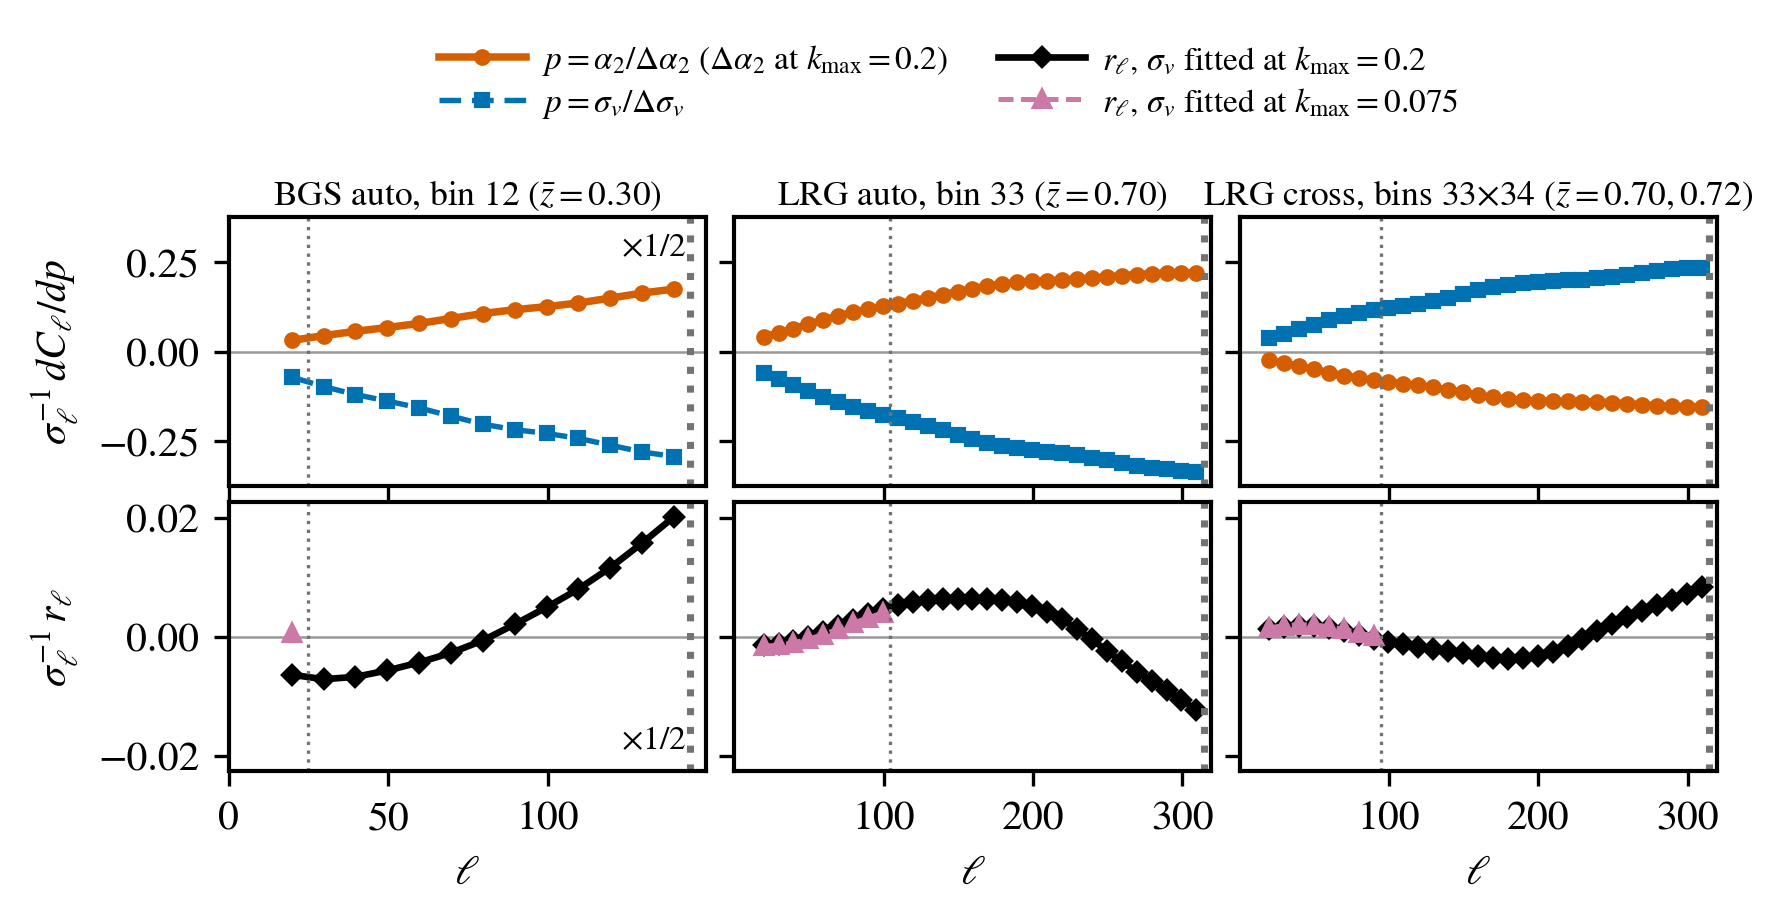

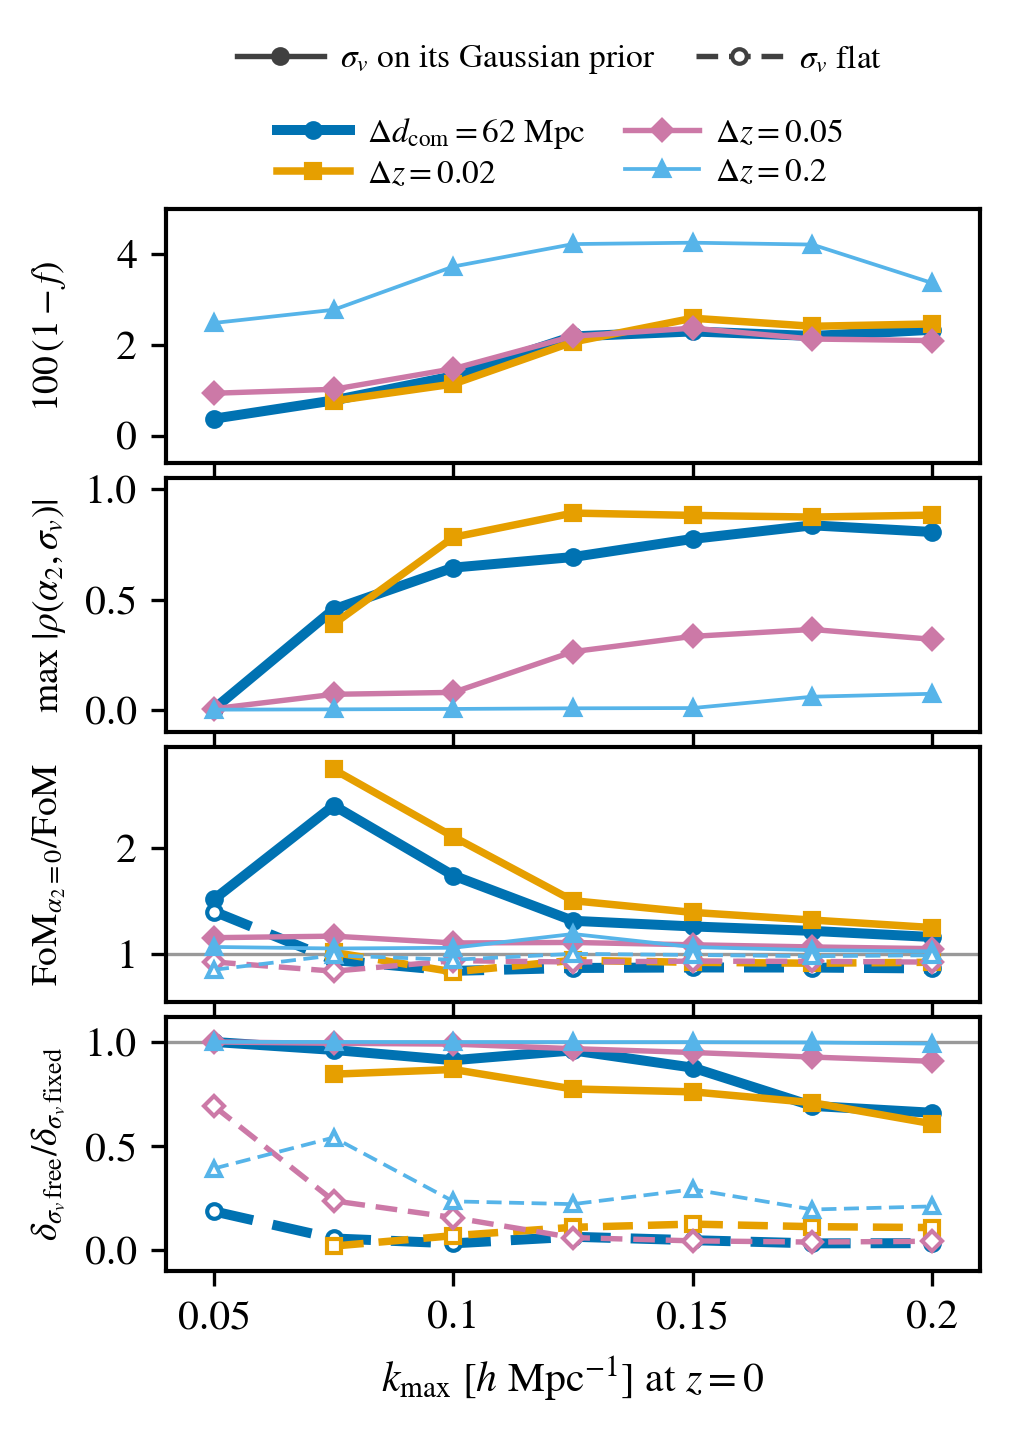

In [27]:
FOG_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/fog_parameter_degeneracy_study/plots/'
# the two cuts of the template figure [h/Mpc at z = 0]
FOG_TEMPLATE_CUTS = (0.075, 0.2)


def fog_cut_index(k):
    return int(np.argmin(np.abs(np.asarray(KMAX_CUTS) - k)))


def fog_spectrum_rows(key, s):
    '''The data-vector rows of spectrum s (the autos first, then the pairs).'''
    t = TABLES[key]
    nell = len(t['ells'])
    return t['n_ee'] + s*nell + np.arange(nell)


def fog_cut_ell(key, s, m, ells):
    '''(ell, limited_by): where spectrum s's kept bands end at cut m, halfway
    between the last kept band center and the next one, and what ends them
    ('cut' or 'shipped mask'); (None, 'no band kept') when nothing is kept.'''
    rows = fog_spectrum_rows(key, s)
    kept = np.isin(rows, kept_rows(key, m))
    shipped = np.isin(rows, kept_rows(key, 'shipped'))
    if not kept.any():
        return None, 'no band kept'
    last = int(np.where(kept)[0].max())
    edge = float(0.5*(ells[last] + ells[last + 1])) if last + 1 < len(ells) else float(ells[last])
    return edge, ('shipped mask' if np.array_equal(kept, shipped) else 'cut')


def fog_template_layout(key, same_group_pair):
    '''The template figure's entries of one layout: three spectra, each with the
    alpha_2 and sigma_v templates, the band-power errors and the leftover of the
    alpha_2 template after its best sigma_v combination at each cut.'''
    B, info = base_matrix(key)
    M, names, tags = COLUMNS[(key, FOG_MODEL)]
    der = derivs[key]
    t = TABLES[key]
    ells = np.asarray(t['ells'], dtype=float)
    nbins = len(t['bins'])
    sv = [j for j, n in enumerate(names) if 'SIGV' in n.upper()]
    # which bins each sigma_v moves: the auto spectra on which its column is
    # above round-off (1e-6 of the column's largest entry)
    sv_bins = {}
    for j in sv:
        d = np.abs(B @ M[:, j])
        sv_bins[names[j]] = [i for i in range(nbins)
                             if d[fog_spectrum_rows(key, i)].max() > 1.0e-6*d.max()]
    groups = {name: list(map(int, idx)) for name, leader, idx in bias_groups(key)}
    sample_of = {i: t['bins'][i][1] for i in range(nbins)}
    group_of = {i: g for g, idx in groups.items() for i in idx}
    m075 = fog_cut_index(0.075)
    n075 = {i: int(np.isin(fog_spectrum_rows(key, i), kept_rows(key, m075)).sum())
            for i in range(nbins)}
    # the BGS bin nearest the middle of the sample that keeps a band at
    # k_max = 0.075 (on a tie, the one keeping more bands), the middle bin of
    # the LRG sample, and that bin's cross spectrum with the next LRG bin
    bgs = [i for i in range(nbins) if sample_of[i] == 'bgs']
    lrg = [i for i in range(nbins) if sample_of[i] == 'lrg']
    middle = 0.5*(bgs[0] + bgs[-1])
    i_bgs = min((i for i in bgs if n075[i] > 0), key=lambda i: (abs(i - middle), -n075[i], i))
    i_lrg = lrg[len(lrg)//2]
    pairs = [tuple(p) for p in t['pairs']]
    pair = None
    for i in sorted(lrg, key=lambda i: abs(i - i_lrg)):
        if (i, i + 1) in pairs and sample_of.get(i + 1) == 'lrg' and \
                (not same_group_pair or group_of[i] == group_of[i + 1]):
            pair = (i, i + 1)
            break
    C = layout_covariance(key, B.shape[0])
    sigma = np.sqrt(np.diag(C))
    del C
    S = M[:, sv]
    panels = []
    for kind, s, bins_shown in (('BGS auto', i_bgs, (i_bgs,)), ('LRG auto', i_lrg, (i_lrg,)),
                                ('LRG cross', nbins + pairs.index(pair), pair)):
        g = group_of[bins_shown[0]]
        j_a2 = names.index(f'DESI_A2_{g}')
        rows = fog_spectrum_rows(key, s)
        # the bin's own velocity dispersion: the sigma_v that moves its spectrum most
        sv_name = max((names[j] for j in sv),
                      key=lambda n: np.abs((B @ M[:, names.index(n)])[rows]).max())
        j_sv = names.index(sv_name)
        a = M[:, j_a2]
        panel = {'kind': kind, 'bins': [int(b) for b in bins_shown],
                 'zbar': [float(BIN_ZBAR[key][b]) for b in bins_shown],
                 'group': g, 'sigma_v': sv_name,
                 'sigma_v_prior_width_km_s': float(EXPLORATION_PRIORS[key][sv_name]),
                 'sigma_v_fiducial_km_s': float(dict(zip(der['names'], der['fiducial']))[sv_name]),
                 'ell': ells.tolist(), 'sigma': sigma[rows].tolist(),
                 'shipped_mask': [bool(x) for x in np.isin(rows, kept_rows(key, 'shipped'))],
                 'dC_dalpha2': (B @ a)[rows].tolist(),
                 'dC_dsigma_v': (B @ M[:, j_sv])[rows].tolist(),
                 'cuts': {}}
        for k in FOG_TEMPLATE_CUTS:
            m = fog_cut_index(k)
            G = GRAM[key][m]
            Gs, _ = fog_ginv(S.T @ G @ S)
            c = Gs @ (S.T @ G @ a)
            resid = B @ (a - S @ c)
            norm = float(a @ G @ a)
            f = float(a @ G @ S @ c)/norm if norm > 0 else None
            edge, limited_by = fog_cut_ell(key, s, m, ells)
            panel['cuts'][f'{k:g}'] = {
                'alpha2_prior_width': float(prior_widths('B', float(KMAX_CUTS[m]))['A2']),
                'residual_per_unit_alpha2': resid[rows].tolist(),
                'kept': [bool(x) for x in np.isin(rows, kept_rows(key, m))],
                'cut_ell': edge, 'kept_bands_end_by': limited_by,
                'redundancy_f': f}
        panels.append(panel)
    return {'name': key, 'sigma_v_bins': sv_bins, 'groups': groups, 'panels': panels}


fog_templates = {
    'about': ('Derivative templates of DESI C_ell^gg against ell, in units of the band-power '
              'error sigma_ell = sqrt(C_ii) of the Gaussian covariance, each parameter p in units '
              'of its prior width Delta (Delta, not sigma: sigma_v is itself a dispersion): '
              'sigma_ell^-1 dC_ell/dp for p = alpha_2/Delta alpha_2 (alpha_2 of the shown bin\'s '
              'group, Delta alpha_2 = 0.5/k_max^2 h^-2 Mpc^2 at the cut) and for p = sigma_v/Delta '
              'sigma_v (the shown bin\'s velocity dispersion and its prior width); and '
              'sigma_ell^-1 r_ell with r_ell = dC_ell/d(alpha_2/Delta alpha_2) - sum_g c_g '
              'dC_ell/d(sigma_v,g/Delta sigma_v,g), the leftover after the best combination c of '
              'all sigma_v, fitted over the whole data vector in the C^-1 metric on the bands the '
              'cut keeps (redundancy_f is the fraction of the alpha_2 information that combination '
              'reproduces). The stored arrays are per unit alpha_2 and sigma_v (dC_dalpha2, '
              'dC_dsigma_v, residual_per_unit_alpha2), with the widths alongside. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 11, final-tier caches); '
              'the bins are the BGS bin nearest the middle of the sample that keeps a band at '
              'k_max = 0.075 (the thin low-redshift BGS bins keep none; on a tie, the one '
              'keeping more bands), the middle bin of the LRG sample, and that bin\'s cross '
              'spectrum with the next LRG bin (bins numbered from 0 as in the dataset\'s bin '
              'table). cut_ell: where the kept bands end at the cut (k_max at z = 0, each bin '
              'cut at k_max/D(zbar_i), intersected with the shipped mask), with '
              'kept_bands_end_by naming what ends them.'),
    'cuts_kmax_h_per_Mpc': list(FOG_TEMPLATE_CUTS),
    'layouts': [fog_template_layout('Delta d_com = 62 Mpc', True),
                fog_template_layout('Delta z = 0.2', False)],
}
worst_f = 0.0
for lay in fog_templates['layouts']:
    for p in lay['panels']:
        for k, entry in p['cuts'].items():
            worst_f = max(worst_f, abs(entry['redundancy_f']
                                       - FOG[lay['name']]['cuts'][k]['f'][f"DESI_A2_{p['group']}"]))
print(f'check: max |f of the template figure - f of table 1| = {worst_f:.1e}')

fog_layouts = []
for key in LAYOUTS:
    entry = FOG[key]
    row = {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
           'one_minus_f_least_redundant_group': [], 'one_minus_f_alpha2_12p5_all_groups': [],
           'rho_max': [], 'rho_max_pair': [], 'fom_ratio_alpha2_fixed': [],
           'fom_ratio_alpha2_fixed_flat_sigma_v': [], 'fom_om_as_ratio_alpha2_fixed': [],
           'shift_ratio_sigma_v_prior': {'w0wa': [], 'omegam': [], 'As_1e9': []},
           'shift_ratio_sigma_v_flat': {'w0wa': [], 'omegam': [], 'As_1e9': []}}
    for k in [float(k) for k in KMAX_CUTS]:
        c = entry['cuts'].get(f'{k:g}')
        if not c or 'fom' not in c:
            for value in row.values():
                if isinstance(value, list):
                    value.append(None)
                elif isinstance(value, dict):
                    for v in value.values():
                        v.append(None)
            continue
        fv = [v for n, v in c['f'].items() if n.startswith('DESI_A2_') and v is not None]
        row['one_minus_f_least_redundant_group'].append(1.0 - min(fv))
        t = c['alpha2_12p5_vs_sigma_v']
        row['one_minus_f_alpha2_12p5_all_groups'].append(
            t['dchi2_left_after_flat_sigma_v']/t['dchi2_truth'])
        row['rho_max'].append(c['rho_max']['abs'])
        row['rho_max_pair'].append([c['rho_max']['alpha2'], c['rho_max']['sigma_v']])
        row['fom_ratio_alpha2_fixed'].append(c['fom']['without_alpha2']/c['fom']['with_alpha2'])
        row['fom_ratio_alpha2_fixed_flat_sigma_v'].append(
            c['fom']['without_alpha2_flat_sigma_v']/c['fom']['with_alpha2'])
        row['fom_om_as_ratio_alpha2_fixed'].append(
            c['fom_om_as']['without_alpha2']/c['fom_om_as']['with_alpha2'])
        ab = c['alpha2_truth_on_fit_without_alpha2']
        for s in ('w0wa', 'omegam', 'As_1e9'):
            fixed = ab['sigma_v fixed']['alpha2 = +12.5'][s]
            row['shift_ratio_sigma_v_prior'][s].append(ab['sigma_v free']['alpha2 = +12.5'][s]/fixed)
            row['shift_ratio_sigma_v_flat'][s].append(ab['sigma_v flat']['alpha2 = +12.5'][s]/fixed)
    fog_layouts.append(row)
fog_degeneracy = {
    'about': ('alpha_2 against the sigma_v (Fingers-of-God) dispersions as a function of the scale '
              'cut, per bin layout. one_minus_f_least_redundant_group: 1 - f for the alpha_2 '
              'group template that the sigma_v templates reproduce least, f = 1 - min_c (a - S '
              'c)^T C^-1 (a - S c)/(a^T C^-1 a) on the band powers the cut keeps; '
              'one_minus_f_alpha2_12p5_all_groups: the same for alpha_2 equal in every group. '
              'rho_max: the largest |correlation| between an alpha_2 parameter and a sigma_v in '
              'the posterior of model B + tilts on the pessimistic linear-bias prior (priors '
              'included). fom_ratio_alpha2_fixed: FoM_{alpha_2 = 0}/FoM, FoM(w0, wa) of that '
              'model with alpha_2 and its tilts fixed at 0 over FoM with alpha_2 free '
              '(_flat_sigma_v: sigma_v priors also removed). shift_ratio_*: delta_{sigma_v '
              'free}/delta_{sigma_v fixed}, with delta the shift of model B + tilts on the '
              'pessimistic prior with alpha_2 and its tilts fixed at 0 (the fit without '
              'alpha_2) fitted to the truth alpha_2 = 12.5 h^-2 Mpc^2 in '
              'every group ((w0, wa) in its ellipse, Omega_m and A_s in their sigma), sigma_v '
              'free on its Gaussian prior (_prior) or flat (_flat), over sigma_v fixed at the '
              'fiducial. k_max is the z = 0 value of a per-bin cut at '
              'k_max/D(zbar_i). None: no band kept. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 11, final-tier caches).'),
    'kmax_h_per_Mpc': [float(k) for k in KMAX_CUTS],
    'layouts': fog_layouts,
}

for name, data in (('fog_templates', fog_templates), ('fog_degeneracy_kmax', fog_degeneracy)):
    folder = FOG_PLOTS + name
    script = folder + f'/plot_{name}.py'
    if not os.path.exists(script):
        raise RuntimeError(f'{script} is missing: the folder needs its plot script')
    with open(folder + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
    display(Image(filename=f'{folder}/{name}.png', width=640 if name == 'fog_templates' else 420))

**5. The $\sigma_v$ prior-width scan.** With $\sigma_v$ on a Gaussian prior,
how wide must that prior be for $\sigma_v$ to absorb a DESI-size $\alpha_2$?
All seven $\sigma_v$ prior widths are multiplied by a common factor
$s \in \{1, 1.5, 2, 3, 5, 10, \infty\}$ ($\infty$: flat), and the fit without
$\alpha_2$ (model B + tilts on the pessimistic prior, $\alpha_2$ and its tilts
fixed at 0; at $s = 6$ it is the paper model) is fitted to the truth
$\alpha_2 = +12.5\,h^{-2}\,\mathrm{Mpc}^2$ in every group. For each $s$, layout
and cut the cell gives the $(w_0, w_a)$, $\Omega_m$ and $A_s$ shifts and the
fit's ${\rm FoM}(w_0, w_a)$ and ${\rm FoM}(\Omega_m, 10^9 A_s)$ over those of the
reference model (model B + tilts, $\alpha_2$ free, $\sigma_v$ at $s = 1$). Two more variants widen only
the three LRG dispersions (LRG1, LRG2, LRG3) or only the two ELG ones (ELG1,
ELG2) and keep the others at $s = 1$. The table prints the largest of the
three shifts and the FoM ratio.

In [28]:
SIGV_SCALES = [1.0, 1.5, 2.0, 3.0, 5.0, 10.0]


def fog_scaled_sigma_v(key, variant, scale, which, tag):
    '''Register a variant whose sigma_v prior widths (all, or only those in
    which) are multiplied by scale; scale None makes them flat.'''
    M, names, tags = COLUMNS[(key, variant)]
    new = []
    for n, t in zip(names, tags):
        if 'SIGV' in n.upper() and (which is None or n in which):
            new.append(('flat',) if scale is None else ('gauss', t[1]*scale))
        else:
            new.append(t)
    COLUMNS[(key, tag)] = (M, names, new)
    return tag


def fog_sample_sigma_v(key, sample, expected):
    '''The sigma_v of one sample ('lrg', 'elg'): DESI_SIGV_<i> leads the group
    whose first bin is bin i - 1 (bins numbered from 0).'''
    names = [n for n in COLUMNS[(key, FOG_MODEL)][1] if 'SIGV' in n.upper()]
    out = {n for n in names if TABLES[key]['bins'][int(n.split('_')[-1]) - 1][1] == sample}
    if len(out) != expected:
        raise RuntimeError(f'{key}: expected {expected} {sample} sigma_v, found {sorted(out)}')
    return out


SIGV_SCAN = {}
for key in LAYOUTS:
    lrg = fog_sample_sigma_v(key, 'lrg', 3)
    elg = fog_sample_sigma_v(key, 'elg', 2)
    truth = {'alpha2 = +12.5': block_vector(key, {'a2': FOG_TRUTH})}
    SIGV_SCAN[key] = {'lrg_sigma_v': sorted(lrg), 'elg_sigma_v': sorted(elg),
                      'all': {}, 'LRG': {}, 'ELG': {}}
    for which_label, which in (('all', None), ('LRG', lrg), ('ELG', elg)):
        for scale in [*SIGV_SCALES, None]:
            s_key = 'flat' if scale is None else f'{scale:g}'
            tag = fog_scaled_sigma_v(key, 'B tilts noA2', scale, which,
                                     f'B tilts noA2 sv {which_label} x{s_key}')
            per_cut = {}
            for m in range(NK):
                paper = FOM[(key, m, FOG_MODEL, FOG_PRIOR)]
                system, status = fit_system(key, m, tag, FOG_PRIOR)
                if system is None or paper is None:
                    per_cut[fog_kfmt(m)] = None
                    continue
                shift = truth_scores(system, truth)['alpha2 = +12.5']
                per_cut[fog_kfmt(m)] = {
                    'shift': shift, 'max_shift': max(shift.values()),
                    'fom': system['fom'], 'fom_om_as': system['fom_om_as'],
                    'fom_ratio': system['fom']/paper['fom'],
                    'fom_om_as_ratio': system['fom_om_as']/paper['fom_om_as']}
            SIGV_SCAN[key][which_label][s_key] = per_cut

# s = 1 and s = flat with every sigma_v are the 'sigma_v free' and 'sigma_v
# flat' fits of item 4
worst = 0.0
for key in LAYOUTS:
    for m in range(NK):
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if not c or 'alpha2_truth_on_fit_without_alpha2' not in c:
            continue
        for s_key, label in (('1', 'sigma_v free'), ('flat', 'sigma_v flat')):
            ref = c['alpha2_truth_on_fit_without_alpha2'][label]['alpha2 = +12.5']
            ours = SIGV_SCAN[key]['all'][s_key][fog_kfmt(m)]['shift']
            worst = max(worst, *[abs(ours[p]/ref[p] - 1.0) for p in ref])
print(f'check: s = 1 and flat against item 4: max relative difference {worst:.1e}')
print('5. sigma_v prior-width scan: the largest alpha_2 = +12.5 shift [sigma] of the fit without '
      'alpha_2 (pessimistic) / its FoM(w0, wa) over the reference model\'s; columns: s')
header = '  '.join(f'{s:>11s}' for s in [*[f'{x:g}' for x in SIGV_SCALES], 'flat'])
for which_label in ('all', 'LRG', 'ELG'):
    print(f'  sigma_v widened: {which_label}{"" if which_label == "all" else " (the others at s = 1)"}')
    print(f'  {"":8s} {"k":5s}  {header}')
    for key in LAYOUTS:
        for m in range(NK):
            row = []
            for s_key in [*[f'{x:g}' for x in SIGV_SCALES], 'flat']:
                e = SIGV_SCAN[key][which_label][s_key][fog_kfmt(m)]
                row.append('          -' if e is None else
                           f'{e["max_shift"]:5.3f}/{e["fom_ratio"]:5.3f}')
            print(f'  {FOG_SHORT[key]:8s} {fog_kfmt(m):5s}  ' + '  '.join(row))

check: s = 1 and flat against item 4: max relative difference 1.7e-09
5. sigma_v prior-width scan: the largest alpha_2 = +12.5 shift [sigma] of the fit without alpha_2 (pessimistic) / its FoM(w0, wa) over the reference model's; columns: s
  sigma_v widened: all
           k                1          1.5            2            3            5           10         flat
  62 Mpc   0.05   0.010/1.517  0.010/1.517  0.010/1.517  0.010/1.517  0.010/1.517  0.010/1.516  0.002/1.401
  62 Mpc   0.075  0.339/2.402  0.331/2.208  0.323/2.041  0.302/1.782  0.255/1.477  0.157/1.182  0.019/0.943
  62 Mpc   0.1    0.545/1.741  0.504/1.546  0.461/1.406  0.383/1.229  0.264/1.061  0.122/0.924  0.018/0.841
  62 Mpc   0.125  0.609/1.314  0.563/1.188  0.505/1.108  0.387/1.018  0.227/0.942  0.096/0.891  0.037/0.868
  62 Mpc   0.15   0.866/1.260  0.736/1.147  0.614/1.075  0.429/0.993  0.227/0.927  0.090/0.888  0.047/0.873
  62 Mpc   0.175  1.146/1.218  0.893/1.111  0.691/1.045  0.428/0.971  0.205/0.915  0.079/0

**The width that passes.** For each layout and cut, the smallest $s$ at which
all three shifts fall below $\sigma/3$, and the ${\rm FoM}(w_0, w_a)$ ratio
there. Between two scanned values the largest shift and the FoM ratio are
interpolated linearly in $\log s$; a fit that passes only with flat
$\sigma_v$ is reported as "> 10 (flat)", and one that fails even then as
"fails".

In [29]:
def fog_passing_s(per_s, kfmt):
    '''(s, FoM ratio, how) at which the largest shift first drops below
    SHIFT_THRESHOLD, interpolated in log s between the scanned values;
    how is 'scanned', 'interpolated', 'flat only', 'fails' or 'no band'.'''
    xs, ys, fs = [], [], []
    for s in SIGV_SCALES:
        e = per_s[f'{s:g}'][kfmt]
        if e is None:
            return None, None, 'no band'
        xs.append(s)
        ys.append(e['max_shift'])
        fs.append(e['fom_ratio'])
    if ys[0] < SHIFT_THRESHOLD:
        return xs[0], fs[0], 'scanned'
    for i in range(1, len(xs)):
        if ys[i] < SHIFT_THRESHOLD:
            t = (SHIFT_THRESHOLD - ys[i - 1])/(ys[i] - ys[i - 1])
            log_s = np.log(xs[i - 1]) + t*(np.log(xs[i]) - np.log(xs[i - 1]))
            return float(np.exp(log_s)), float(fs[i - 1] + t*(fs[i] - fs[i - 1])), 'interpolated'
    flat = per_s['flat'][kfmt]
    if flat['max_shift'] < SHIFT_THRESHOLD:
        return None, flat['fom_ratio'], 'flat only'
    return None, None, 'fails'


SIGV_PASS = {}
for key in LAYOUTS:
    SIGV_PASS[key] = {}
    for which_label in ('all', 'LRG', 'ELG'):
        SIGV_PASS[key][which_label] = {}
        for m in range(NK):
            s, ratio, how = fog_passing_s(SIGV_SCAN[key][which_label], fog_kfmt(m))
            SIGV_PASS[key][which_label][fog_kfmt(m)] = {'s': s, 'fom_ratio': ratio, 'how': how}


def fog_pass_text(e):
    if e['how'] == 'no band':
        return '-'
    if e['how'] == 'fails':
        return 'fails'
    if e['how'] == 'flat only':
        return f'> 10 (flat), FoM x{e["fom_ratio"]:.2f}'
    return f'{e["s"]:.2f}, FoM x{e["fom_ratio"]:.2f}'


print('the smallest s at which every alpha_2 = +12.5 shift is below sigma/3, and FoM(w0, wa) '
      'of the fit without alpha_2 there over the reference model\'s (interpolated in log s between '
      'the scanned values)')
for key in LAYOUTS:
    for m in range(NK):
        a = SIGV_PASS[key]['all'][fog_kfmt(m)]
        b = SIGV_PASS[key]['LRG'][fog_kfmt(m)]
        c = SIGV_PASS[key]['ELG'][fog_kfmt(m)]
        print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} every sigma_v: {fog_pass_text(a):26s} '
              f'LRG only: {fog_pass_text(b):26s} ELG only: {fog_pass_text(c)}')

the smallest s at which every alpha_2 = +12.5 shift is below sigma/3, and FoM(w0, wa) of the fit without alpha_2 there over the reference model's (interpolated in log s between the scanned values)
  62 Mpc   k=0.05  every sigma_v: 1.00, FoM x1.52            LRG only: 1.00, FoM x1.52            ELG only: 1.00, FoM x1.52
  62 Mpc   k=0.075 every sigma_v: 1.35, FoM x2.26            LRG only: fails                      ELG only: 1.73, FoM x2.33
  62 Mpc   k=0.1   every sigma_v: 3.71, FoM x1.16            LRG only: fails                      ELG only: fails
  62 Mpc   k=0.125 every sigma_v: 3.56, FoM x0.99            LRG only: fails                      ELG only: fails
  62 Mpc   k=0.15  every sigma_v: 3.82, FoM x0.96            LRG only: fails                      ELG only: fails
  62 Mpc   k=0.175 every sigma_v: 3.73, FoM x0.95            LRG only: fails                      ELG only: fails
  62 Mpc   k=0.2   every sigma_v: 3.64, FoM x0.93            LRG only: fails                      E

**Export.** This cell writes `fog_sigv_width/data.json` under
`notes/fog_parameter_degeneracy_study/plots/`: the scan of every layout and
cut (every $\sigma_v$ widened, and the LRG ones only), with the three shifts,
the FoM ratios and the passing $s$; then runs `plot_fog_sigv_width.py`.

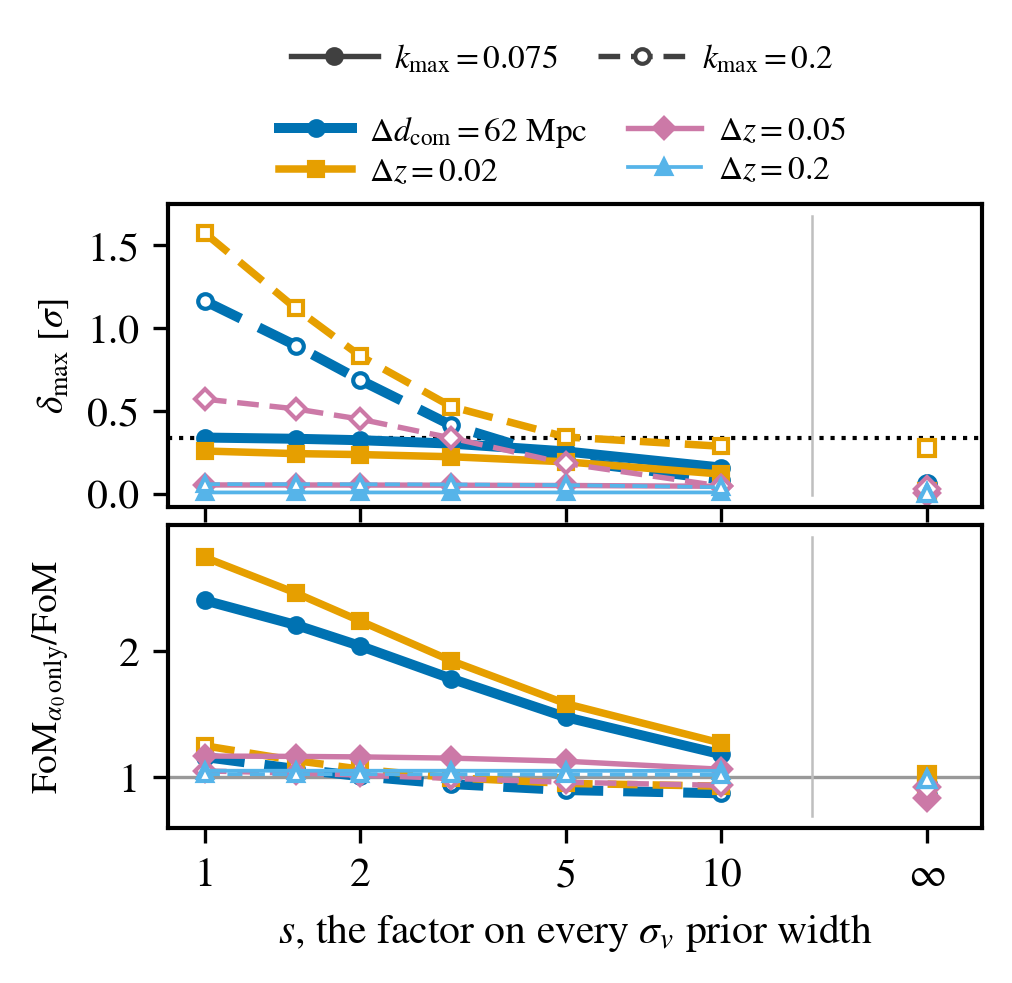

In [30]:
fog_sigv = {
    'about': ('The sigma_v prior-width scan: all seven sigma_v prior widths multiplied by a '
              'common factor s (s_finite, plus flat), the fit without alpha_2 (model B + tilts '
              'on the pessimistic linear-bias prior, alpha_2 and its tilts fixed at 0; the '
              'paper model at s = 6) fitted to the truth alpha_2 = '
              '+12.5 h^-2 Mpc^2 in every group. Per layout and cut: the shifts ((w0, wa) in its '
              'ellipse, Omega_m and A_s in their sigma) and max_shift, the largest of the three; '
              'fom_ratio and fom_om_as_ratio, FoM(w0, wa) and FoM(Omega_m, 10^9 A_s) of that fit '
              'over the reference model\'s (model B + tilts, alpha_2 free, sigma_v at s = 1); '
              'passing: the smallest s with every shift below shift_threshold and the FoM '
              'ratio there, interpolated linearly in log s between the scanned values '
              '(how: scanned, interpolated, flat only, fails). lrg_only, elg_only: the same with '
              'only the LRG or the ELG sigma_v widened, the others at s = 1. k_max is the z = 0 '
              'value of a per-bin cut at '
              'k_max/D(zbar_i). None: no band kept. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 11, item 5, final-tier caches).'),
    's_finite': SIGV_SCALES,
    'kmax_h_per_Mpc': [float(k) for k in KMAX_CUTS],
    'shift_threshold': SHIFT_THRESHOLD,
    'layouts': [],
}
for key in LAYOUTS:
    entry = {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
             'lrg_sigma_v': SIGV_SCAN[key]['lrg_sigma_v'],
             'elg_sigma_v': SIGV_SCAN[key]['elg_sigma_v']}
    for which_label, field in (('all', 'all_sigma_v'), ('LRG', 'lrg_only'), ('ELG', 'elg_only')):
        scan = SIGV_SCAN[key][which_label]
        per_cut = {}
        for m in range(NK):
            k = fog_kfmt(m)
            if scan['1'][k] is None:
                per_cut[k] = None
                continue
            pick = lambda name: [scan[f'{s:g}'][k][name] for s in SIGV_SCALES]
            per_cut[k] = {
                'max_shift': pick('max_shift'), 'max_shift_flat': scan['flat'][k]['max_shift'],
                'shift': {p: [scan[f'{s:g}'][k]['shift'][p] for s in SIGV_SCALES]
                          for p in ('w0wa', 'omegam', 'As_1e9')},
                'shift_flat': scan['flat'][k]['shift'],
                'fom_ratio': pick('fom_ratio'), 'fom_ratio_flat': scan['flat'][k]['fom_ratio'],
                'fom_om_as_ratio': pick('fom_om_as_ratio'),
                'fom_om_as_ratio_flat': scan['flat'][k]['fom_om_as_ratio'],
                'passing': SIGV_PASS[key][which_label][k]}
        entry[field] = per_cut
    fog_sigv['layouts'].append(entry)

folder = FOG_PLOTS + 'fog_sigv_width'
script = folder + '/plot_fog_sigv_width.py'
if not os.path.exists(script):
    raise RuntimeError(f'{script} is missing: the folder needs its plot script')
with open(folder + '/data.json', 'w') as f:
    json.dump(fog_sigv, f, indent=1)
subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
display(Image(filename=f'{folder}/fog_sigv_width.png', width=420))

**6. The pair list at the edges of the $\sigma_v$ prior.** The paper pair
list (`scripts/make_desi_pairs.py`) adds every pair of bins whose
Fingers-of-God-blurred kernels overlap by $O_{ij} \geq 10^{-6}$ at the
fiducial $\sigma_v$, with $O_{ij} = \int n_i n_j\,dz/\sqrt{\int n_i^2\,dz
\int n_j^2\,dz}$ and each bin's $n(z)$ convolved with a Gaussian of width
$\sigma_z = (1 + \bar z_i)\,\sigma_v/c$, truncated at $4\sigma_z$ (the
likelihood's convolution). A larger $\sigma_v$ widens the blur, so pairs left
out at the fiducial (bins two apart in a sample, above all) start to overlap.
This cell uses the script's own blur rule, groups, fiducials and prior widths
(no CosmoLike) and sets each group's $\sigma_v$ at
$\sigma_v^\mathrm{fid} + k\,s\,\Delta\sigma_v$, with $\Delta\sigma_v$ its
prior width, $k$ the offset in prior widths and $s$ the width factor of item
5. Since $O_{ij}$ depends only on the dispersions of bins $i$ and $j$, setting
every group at its edge and setting only the pair's own group(s) at their
edge give the same $O_{ij}$; the tables name the pair and its group. The
first table gives the largest $O_{ij}$ over the pairs outside the layout's
pair list at $k = 0, 1, 2, 3$ and $s = 1, 2, 4, 6$; the second the offset
$k\,s$ (in prior widths) at which that largest $O_{ij}$ first reaches
$10^{-6}$, $10^{-4}$, $10^{-3}$ and $10^{-2}$ (log-interpolated on a grid
of step 0.05 in $k\,s$), and the $k$ this means at $s = 1$ and $s = 4$.

In [31]:
# the pair rule's own blur, groups, fiducials and prior widths, imported
# without writing bytecode into the project
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/scripts')
_bytecode = sys.dont_write_bytecode
sys.dont_write_bytecode = True
import make_desi_pairs as desi_pairs
import make_desi_params as desi_params
sys.dont_write_bytecode = _bytecode
from scipy.ndimage import gaussian_filter1d

OVERLAP_THRESHOLDS = [1.0e-6, 1.0e-4, 1.0e-3, 1.0e-2]
OVERLAP_K = [0, 1, 2, 3]
OVERLAP_S = [1, 2, 4, 6]
# the grid of offsets k s [prior widths] for the crossings and the figure
OVERLAP_T = np.round(np.arange(0.0, 18.0 + 1.0e-9, 0.05), 10)
# the Gaussian truncation of the likelihood's convolution [sigma]
OVERLAP_TRUNCATE = 4.0


def fog_overlap_layout(key):
    '''The raw n(z), groups and pair list of one layout, as the pair rule reads
    them: z grid, per bin its raw n(z) support, sample, chunk, mean redshift and
    sigma_v group, and the listed pairs (0-based bins).'''
    stem = LAYOUTS[key]['dataset']
    table = np.loadtxt(os.path.join(desi_pairs.DATA, f'{stem}_bins.txt'), usecols=(1, 3),
                       dtype=str, ndmin=2)
    zbar = np.loadtxt(os.path.join(desi_pairs.DATA, f'{stem}_bins.txt'), usecols=4, ndmin=1)
    nz = np.loadtxt(os.path.join(desi_pairs.DATA, f'{stem}.nz'))
    z = nz[:, 0]
    raw = nz[:, 1:]
    support = []
    for i in range(raw.shape[1]):
        live = np.nonzero(raw[:, i] > 0.0)[0]
        support.append((int(live[0]), int(live[-1])))
    groups = [desi_params.sigv_group_key(str(s), str(g), zb)
              for (s, g), zb in zip(table, zbar)]
    listed = {tuple(int(v) for v in row) for row in
              np.loadtxt(os.path.join(desi_pairs.DATA, f'{stem}_pairs.txt'), dtype=int, ndmin=2)}
    return {'z': z, 'dz': float(z[1] - z[0]), 'raw': raw, 'support': support,
            'samples': [str(s) for s, g in table], 'chunks': [str(g) for s, g in table],
            'zbar': zbar, 'groups': groups, 'listed': listed}


def fog_kernels(lay, sigv):
    '''Each bin's blurred n(z) on the slice of the grid where it is nonzero:
    {bin: (first index, values)}. sigv = {group: sigma_v [km/s]}. The slice
    pads the raw support by the truncated Gaussian's radius, so the result
    equals the pair rule's full-grid convolution.'''
    out = {}
    n = len(lay['z'])
    for i, (a, b) in enumerate(lay['support']):
        sigma = max((1.0 + lay['zbar'][i])*sigv[lay['groups'][i]]/desi_pairs.C_KMS, 0.0)/lay['dz']
        pad = int(OVERLAP_TRUNCATE*sigma + 0.5) + 1
        lo, hi = max(a - pad, 0), min(b + pad, n - 1)
        values = lay['raw'][lo:hi + 1, i]
        if sigma > 0.0:
            values = gaussian_filter1d(values, sigma=sigma, mode='constant',
                                       truncate=OVERLAP_TRUNCATE)
        out[i] = (lo, values)
    return out


def fog_overlap(lay, kernels, i, j):
    '''O_ij of two sliced kernels (the trapezoid rule of the pair rule on a
    uniform grid whose ends the kernels do not reach).'''
    lo_i, k_i = kernels[i]
    lo_j, k_j = kernels[j]
    lo, hi = max(lo_i, lo_j), min(lo_i + len(k_i), lo_j + len(k_j))
    if hi <= lo:
        return 0.0
    cross = float(np.dot(k_i[lo - lo_i:hi - lo_i], k_j[lo - lo_j:hi - lo_j]))
    return cross/np.sqrt(float(np.dot(k_i, k_i))*float(np.dot(k_j, k_j)))


def fog_unlisted_max(lay, sigv):
    '''The largest O_ij over the pairs outside the pair list, and the pair.'''
    kernels = fog_kernels(lay, sigv)
    best, where = 0.0, None
    nbin = len(lay['support'])
    for i in range(nbin):
        for j in range(i + 1, nbin):
            if (i, j) in lay['listed']:
                continue
            value = fog_overlap(lay, kernels, i, j)
            if value > best:
                best, where = value, (i, j)
    return best, where


def fog_edges(t):
    '''Every sigma_v group at fiducial + t prior widths [km/s].'''
    fid = desi_params.MODELS['params_desi.yaml']['sigv_values']
    return {g: fid[g] + t*desi_params.SIGV_PRIOR_SIGMA[g] for g in fid}


def fog_pair_name(lay, pair):
    if pair is None:
        return '-'
    i, j = pair
    gi, gj = lay['groups'][i], lay['groups'][j]
    group = gi if gi == gj else f'{gi} x {gj}'
    return f'bins {i}, {j} ({group}, {j - i} apart)'


def fog_crossing(t, values, level):
    '''The first t at which values reach level, log-interpolated; None if never.'''
    for n in range(len(t)):
        if values[n] >= level:
            if n == 0:
                return float(t[0])
            lo, hi = max(values[n - 1], 1e-300), values[n]
            f = (np.log(level) - np.log(lo))/(np.log(hi) - np.log(lo))
            return float(t[n - 1] + f*(t[n] - t[n - 1]))
    return None


OVERLAP = {}
for key in LAYOUTS:
    lay = fog_overlap_layout(key)
    # the pair rule's fiducials and prior widths are the likelihood's
    fid_nb = fiducial_of(key)
    for name in [n for n in COLUMNS[(key, FOG_MODEL)][1] if 'SIGV' in n.upper()]:
        group = lay['groups'][int(name.split('_')[-1]) - 1]
        if (abs(fid_nb[name] - desi_params.MODELS['params_desi.yaml']['sigv_values'][group]) > 1e-9
                or abs(EXPLORATION_PRIORS[key][name] - desi_params.SIGV_PRIOR_SIGMA[group]) > 1e-9):
            raise RuntimeError(f'{key}: {name} ({group}) differs from make_desi_params')
    # the sliced kernels reproduce the pair rule's full-grid overlap
    kernels = fog_kernels(lay, fog_edges(0.0))
    full = desi_pairs.blurred_kernels(LAYOUTS[key]['dataset'])[1]
    probe = sorted(lay['listed'])[:3]
    worst = max(abs(fog_overlap(lay, kernels, i, j)
                    / desi_pairs.overlap(full[:, i], full[:, j], lay['z']) - 1.0) for i, j in probe)
    if worst > 1.0e-9:
        raise RuntimeError(f'{key}: the sliced overlaps differ from the pair rule by {worst:.1e}')
    scan = [fog_unlisted_max(lay, fog_edges(t)) for t in OVERLAP_T]
    values = np.array([v for v, p in scan])
    OVERLAP[key] = {
        'layout': lay, 'check_against_pair_rule': worst,
        't': OVERLAP_T, 'max_unlisted': values,
        'pair_at_t': [p for v, p in scan],
        'crossing_t': {level: fog_crossing(OVERLAP_T, values, level)
                       for level in OVERLAP_THRESHOLDS}}
print('check: sliced overlaps against make_desi_pairs.overlap, max relative difference '
      + ', '.join(f'{FOG_SHORT[k]} {v["check_against_pair_rule"]:.1e}' for k, v in OVERLAP.items()))
print()
print('largest O_ij over the pairs outside the pair list, each sigma_v group at fiducial + k s '
      'prior widths')
for key in LAYOUTS:
    o = OVERLAP[key]
    for s in OVERLAP_S:
        row = []
        for k in OVERLAP_K:
            n = int(np.argmin(np.abs(o['t'] - k*s)))
            row.append(f'k={k}: {o["max_unlisted"][n]:8.2e} {fog_pair_name(o["layout"], o["pair_at_t"][n])}')
        print(f'  {FOG_SHORT[key]:8s} s={s}  ' + ' | '.join(row))
print()
print('the offset k s [prior widths] at which the largest unlisted O_ij first reaches each level '
      '(the k at s = 1 and at s = 4); None: not within k s <= 18')
for key in LAYOUTS:
    o = OVERLAP[key]
    parts = []
    for level, t_c in o['crossing_t'].items():
        if t_c is None:
            parts.append(f'{level:.0e}: none')
            continue
        n = int(np.argmin(np.abs(o['t'] - t_c)))
        parts.append(f'{level:.0e}: k s = {t_c:.2f} (k = {t_c:.2f} at s = 1, {t_c/4:.2f} at s = 4; '
                     f'{fog_pair_name(o["layout"], o["pair_at_t"][n])})')
    print(f'  {FOG_SHORT[key]:8s} ' + '; '.join(parts))

check: sliced overlaps against make_desi_pairs.overlap, max relative difference 62 Mpc 7.8e-16, dz 0.02 8.9e-16, dz 0.05 8.9e-16, dz 0.2 3.3e-16

largest O_ij over the pairs outside the pair list, each sigma_v group at fiducial + k s prior widths
  62 Mpc   s=1  k=0: 0.00e+00 - | k=1: 1.71e-10 bins 6, 8 (BGS0, 2 apart) | k=2: 7.59e-07 bins 6, 8 (BGS0, 2 apart) | k=3: 2.93e-05 bins 6, 8 (BGS0, 2 apart)
  62 Mpc   s=2  k=0: 0.00e+00 - | k=1: 7.59e-07 bins 6, 8 (BGS0, 2 apart) | k=2: 2.60e-04 bins 6, 8 (BGS0, 2 apart) | k=3: 3.26e-03 bins 6, 8 (BGS0, 2 apart)
  62 Mpc   s=4  k=0: 0.00e+00 - | k=1: 2.60e-04 bins 6, 8 (BGS0, 2 apart) | k=2: 1.39e-02 bins 6, 8 (BGS0, 2 apart) | k=3: 7.10e-02 bins 6, 8 (BGS0, 2 apart)
  62 Mpc   s=6  k=0: 0.00e+00 - | k=1: 3.26e-03 bins 6, 8 (BGS0, 2 apart) | k=2: 7.10e-02 bins 6, 8 (BGS0, 2 apart) | k=3: 2.25e-01 bins 7, 9 (BGS0, 2 apart)
  dz 0.02  s=1  k=0: 1.50e-14 bins 87, 89 (ELG2, 2 apart) | k=1: 8.58e-10 bins 87, 89 (ELG2, 2 apart) | k=2: 5.05e-08 bin

**The $\alpha_2$ to $\sigma_v$ translation.** In the fit without $\alpha_2$
(model B + tilts on the pessimistic prior, $\alpha_2$ and its tilts fixed at 0)
a true $\alpha_2$ is partly taken up by $\sigma_v$. The linear response $\delta p = F^{-1} M^\mathsf{T} G c$ of
item 4 to $c = $ one unit of $\alpha_2$ in every group gives each group's
$\sigma_v$ shift per unit $\alpha_2$ [km/s per $h^{-2}\,\mathrm{Mpc}^2$], with
$\sigma_v$ on its prior and flat, at every cut. With those slopes (linear
response throughout), the cell finds the $|\alpha_2|$ at which some pair
outside the list first reaches $O_{ij} = 10^{-6}$, for each sign of
$\alpha_2$ (every group moved by its own slope; a negative $\alpha_2$ raises
$\sigma_v$, since the slopes are negative), and compares it with DESI's width
$12.5$ and with model B's prior width $0.5/k_\mathrm{max}^2$.

In [32]:
def fog_sigv_response(key, m, variant):
    '''{sigma_v group: shift per unit alpha_2 [km/s per h^-2 Mpc^2]} of the
    fit variant at cut m (the linear response of item 4).'''
    system, status = fit_system(key, m, variant, FOG_PRIOR)
    if system is None:
        return None
    M = COLUMNS[(key, variant)][0][:, system['live']]
    names = [COLUMNS[(key, variant)][1][j] for j in system['live']]
    c = block_vector(key, {'a2': 1.0})
    dp = system['F_inv'] @ (M.T @ (GRAM[key][m] @ c))
    lay = OVERLAP[key]['layout']
    out = {}
    for j, n in enumerate(names):
        if 'SIGV' in n.upper():
            out[lay['groups'][int(n.split('_')[-1]) - 1]] = float(dp[j])
    return out


# the scan of |alpha_2| stops at ALPHA2_MAX or once a sigma_v passes SIGV_MAX
# [km/s], far beyond any measured dispersion
ALPHA2_MAX = 1.0e4
SIGV_MAX = 5000.0
# the cuts of the |alpha_2| crossings
ALPHA2_CUTS = (0.075, 0.2)


def fog_alpha2_crossing(lay, slopes, sign, level=1.0e-6):
    '''The smallest |alpha_2| (of the given sign) at which the largest
    unlisted O_ij reaches level, with sigma_v,g = fiducial_g + slope_g alpha_2
    (at least 0): a log grid, then bisection; None if not before ALPHA2_MAX or
    SIGV_MAX.'''
    fid = desi_params.MODELS['params_desi.yaml']['sigv_values']

    def sigv_at(a):
        return {g: max(fid[g] + slopes.get(g, 0.0)*sign*a, 0.0) for g in fid}

    def largest(a):
        return fog_unlisted_max(lay, sigv_at(a))

    previous = 0.0
    for a in np.logspace(0.0, np.log10(ALPHA2_MAX), 33):
        if max(sigv_at(a).values()) > SIGV_MAX:
            return None, None
        value, pair = largest(a)
        if value >= level:
            lo, hi = previous, a
            for _ in range(30):
                mid = 0.5*(lo + hi)
                if largest(mid)[0] >= level:
                    hi = mid
                else:
                    lo = mid
            return hi, largest(hi)[1]
        previous = a
    return None, None


ALPHA2_SIGV = {}
for key in LAYOUTS:
    lay = OVERLAP[key]['layout']
    ALPHA2_SIGV[key] = {}
    for m in range(NK):
        if GRAM[key][m] is None or fit_system(key, m, 'B tilts noA2', FOG_PRIOR)[0] is None:
            ALPHA2_SIGV[key][fog_kfmt(m)] = None
            continue
        entry = {}
        for label, variant in (('prior', 'B tilts noA2'), ('flat', 'B tilts noA2 flatSV')):
            slopes = fog_sigv_response(key, m, variant)
            crossing = None
            if any(abs(float(KMAX_CUTS[m]) - k) < 1.0e-9 for k in ALPHA2_CUTS):
                crossing = {}
                for sign_label, sign in (('negative', -1.0), ('positive', 1.0)):
                    a, pair = fog_alpha2_crossing(lay, slopes, sign)
                    crossing[sign_label] = {'abs_alpha2': a,
                                            'pair': None if pair is None else list(pair),
                                            'pair_name': fog_pair_name(lay, pair)}
            entry[label] = {'slope_km_s_per_alpha2': slopes, 'crossing_1e-6': crossing}
        ALPHA2_SIGV[key][fog_kfmt(m)] = entry

print('sigma_v shift per unit alpha_2 [km/s per h^-2 Mpc^2] of the fit without alpha_2 (pessimistic), '
      'sigma_v on its prior / flat, and the |alpha_2| at which an unlisted pair reaches '
      'O = 1e-6 at k_max = 0.075 and 0.2 (negative alpha_2; positive alpha_2; never: not before '
      '|alpha_2| = 1e4 or sigma_v = 5000 km/s)')
for key in LAYOUTS:
    for m in range(NK):
        e = ALPHA2_SIGV[key][fog_kfmt(m)]
        if e is None:
            continue
        k = float(KMAX_CUTS[m])
        parts = []
        for label in ('prior', 'flat'):
            sl = e[label]['slope_km_s_per_alpha2']
            big = max(sl, key=lambda g: abs(sl[g]))
            cr = e[label]['crossing_1e-6']
            text = f'{label}: largest slope {sl[big]:+.3f} ({big})'
            if cr is not None:
                fmt = lambda c: 'never' if c['abs_alpha2'] is None else f'{c["abs_alpha2"]:.3g}'
                text += (f'; |alpha_2| {fmt(cr["negative"])} ({cr["negative"]["pair_name"]}) / '
                         f'{fmt(cr["positive"])}')
            parts.append(text)
        print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} (model B width {0.5/k**2:.3g}) '
              + ' | '.join(parts))

sigma_v shift per unit alpha_2 [km/s per h^-2 Mpc^2] of the fit without alpha_2 (pessimistic), sigma_v on its prior / flat, and the |alpha_2| at which an unlisted pair reaches O = 1e-6 at k_max = 0.075 and 0.2 (negative alpha_2; positive alpha_2; never: not before |alpha_2| = 1e4 or sigma_v = 5000 km/s)
  62 Mpc   k=0.05  (model B width 200) prior: largest slope -0.001 (ELG2) | flat: largest slope -5.849 (ELG2)
  62 Mpc   k=0.075 (model B width 88.9) prior: largest slope -0.297 (ELG1); |alpha_2| 1.17e+03 (bins 50, 52 (ELG1, 2 apart)) / 1.51e+03 | flat: largest slope -6.248 (ELG2); |alpha_2| 58.7 (bins 50, 52 (ELG1, 2 apart)) / never
  62 Mpc   k=0.1   (model B width 50) prior: largest slope -0.692 (ELG1) | flat: largest slope -6.669 (ELG2)
  62 Mpc   k=0.125 (model B width 32) prior: largest slope -0.754 (ELG1) | flat: largest slope -6.950 (ELG2)
  62 Mpc   k=0.15  (model B width 22.2) prior: largest slope -1.264 (ELG1) | flat: largest slope -7.190 (ELG2)
  62 Mpc   k=0.175 (model B wi

**The reference model's own $\sigma_v$ range.** With $\alpha_2$ free the
posterior of model B + tilts keeps each $\sigma_v$ at $0.60$–$1.00$ of its prior
width (item 3). The cell gives the largest unlisted $O_{ij}$ with every group
at its prior's $+2\sigma$ edge, and at $+2$ posterior widths of the reference
model at $k_\mathrm{max} = 0.075$ and $0.2$.

In [33]:
PAPER_SIGV_RANGE = {}
for key in LAYOUTS:
    lay = OVERLAP[key]['layout']
    fid = desi_params.MODELS['params_desi.yaml']['sigv_values']
    entry = {}
    value, pair = fog_unlisted_max(lay, fog_edges(2.0))
    entry['prior_plus_2'] = {'max_unlisted': value, 'pair': list(pair) if pair else None,
                             'pair_name': fog_pair_name(lay, pair)}
    for k in (0.075, 0.2):
        m = int(np.argmin(np.abs(KMAX_CUTS - k)))
        c = FOG[key]['cuts'][fog_kfmt(m)]
        if c is None or 'sigma_v_width_over_prior' not in c:
            entry[f'posterior_plus_2_at_{k:g}'] = None
            continue
        ratio = {lay['groups'][int(n.split('_')[-1]) - 1]: w['with_alpha2']
                 for n, w in c['sigma_v_width_over_prior'].items()}
        sigv = {g: fid[g] + 2.0*ratio[g]*desi_params.SIGV_PRIOR_SIGMA[g] for g in fid}
        value, pair = fog_unlisted_max(lay, sigv)
        entry[f'posterior_plus_2_at_{k:g}'] = {'max_unlisted': value,
                                               'pair': list(pair) if pair else None,
                                               'pair_name': fog_pair_name(lay, pair)}
    PAPER_SIGV_RANGE[key] = entry
print('largest unlisted O_ij at the +2 sigma edge of the sigma_v prior, and at +2 posterior widths '
      'of the reference model (k_max = 0.075 and 0.2)')
for key in LAYOUTS:
    e = PAPER_SIGV_RANGE[key]
    show = lambda x: '-' if x is None else f'{x["max_unlisted"]:.2e} ({x["pair_name"]})'
    print(f'  {FOG_SHORT[key]:8s} prior +2: {show(e["prior_plus_2"])}; posterior +2 at 0.075: '
          f'{show(e["posterior_plus_2_at_0.075"])}; at 0.2: {show(e["posterior_plus_2_at_0.2"])}')

largest unlisted O_ij at the +2 sigma edge of the sigma_v prior, and at +2 posterior widths of the reference model (k_max = 0.075 and 0.2)
  62 Mpc   prior +2: 7.59e-07 (bins 6, 8 (BGS0, 2 apart)); posterior +2 at 0.075: 7.59e-07 (bins 6, 8 (BGS0, 2 apart)); at 0.2: 4.90e-09 (bins 6, 8 (BGS0, 2 apart))
  dz 0.02  prior +2: 5.05e-08 (bins 47, 49 (LRG3, 2 apart)); posterior +2 at 0.075: 4.44e-08 (bins 47, 49 (LRG3, 2 apart)); at 0.2: 1.89e-08 (bins 87, 89 (ELG2, 2 apart))
  dz 0.05  prior +2: 0.00e+00 (-); posterior +2 at 0.075: 0.00e+00 (-); at 0.2: 0.00e+00 (-)
  dz 0.2   prior +2: 0.00e+00 (-); posterior +2 at 0.075: 0.00e+00 (-); at 0.2: 0.00e+00 (-)


**Export.** This cell writes `fog_pair_overlap/data.json` under
`notes/fog_parameter_degeneracy_study/plots/`: per layout the largest
unlisted $O_{ij}$ on the grid of offsets $k\,s$ with the pair that reaches
it, the crossings, the $\alpha_2$ to $\sigma_v$ slopes and $|\alpha_2|$
crossings, and the reference model's $\pm 2\sigma$ check; then runs
`plot_fog_pair_overlap.py`.

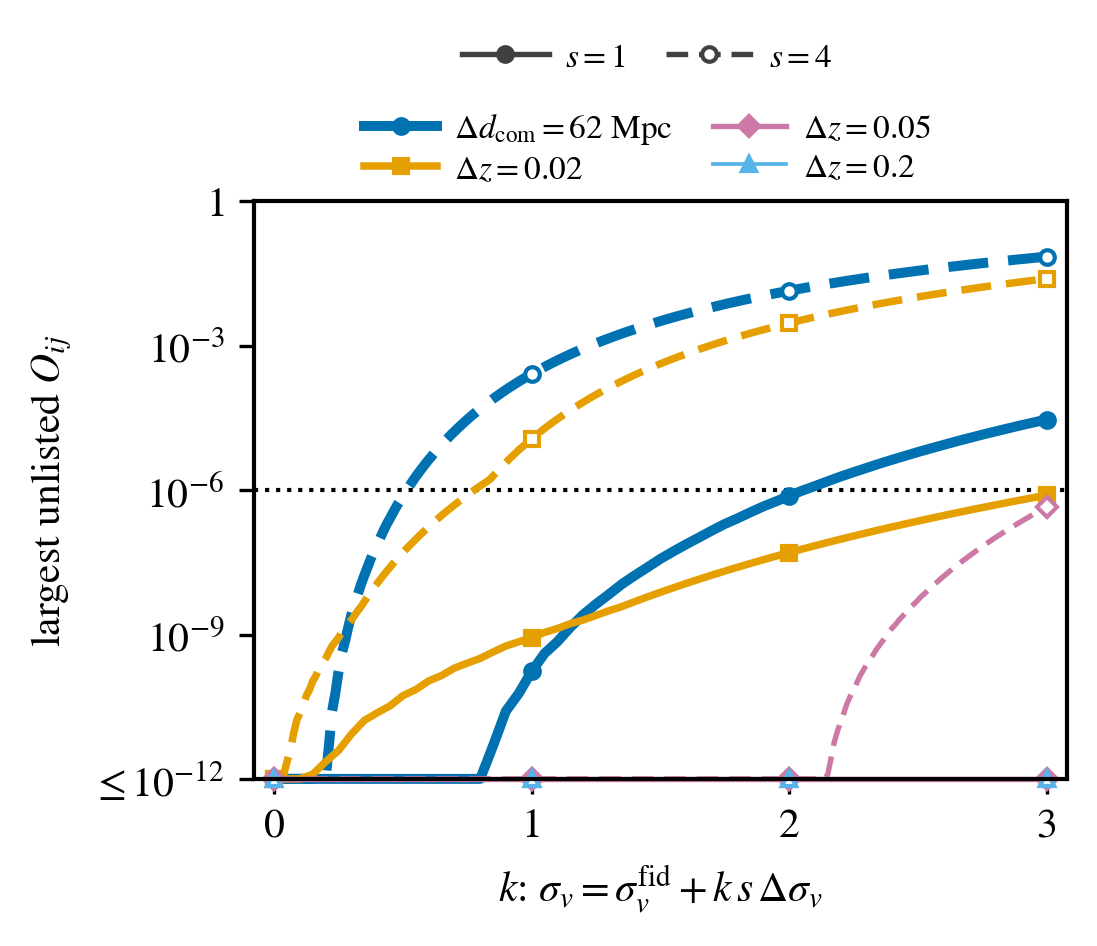

In [34]:
def fog_json_pair(lay, pair):
    return None if pair is None else {'bins': list(pair), 'name': fog_pair_name(lay, pair),
                                      'groups': [lay['groups'][pair[0]], lay['groups'][pair[1]]]}


fog_pairs = {
    'about': ('The FoG pair rule at the edges of the sigma_v prior. O_ij = int n_i n_j dz / sqrt(int '
              'n_i^2 dz int n_j^2 dz) of two bins\' Fingers-of-God-blurred n(z) (a Gaussian of '
              'sigma_z = (1 + zbar_i) sigma_v/c truncated at 4 sigma_z, scripts/make_desi_pairs.py); '
              'the paper pair list holds every pair with O_ij >= 1e-6 at the fiducial sigma_v. '
              'max_unlisted: the largest O_ij over the pairs outside the layout\'s pair list, with '
              'every sigma_v group at fiducial + t prior widths, t = k s (k: the offset in prior '
              'widths; s: the width factor of the prior-width scan), on the grid t; pair_at_t: the '
              'pair that reaches it (bins numbered from 0). crossing_t: the t at which max_unlisted '
              'first reaches each level (log-interpolated; null: not within the grid). '
              'alpha2_to_sigma_v: per cut, each group\'s sigma_v shift per unit alpha_2 of the '
              'fit without alpha_2 (model B + tilts with alpha_2 and its tilts fixed at 0, '
              'pessimistic prior; sigma_v on its prior or flat; '
              'linear response) and the |alpha_2| of each sign at which an unlisted pair reaches '
              'O = 1e-6. paper_sigma_v_range: the largest unlisted O_ij at the +2 sigma edge of the '
              'prior and at +2 posterior widths of model B + tilts. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 11, item 6).'),
    'overlap_min': 1.0e-6,
    'levels': OVERLAP_THRESHOLDS,
    't': [float(t) for t in OVERLAP_T],
    'k_values': OVERLAP_K, 's_values': OVERLAP_S,
    'sigma_v_fiducial_km_s': desi_params.MODELS['params_desi.yaml']['sigv_values'],
    'sigma_v_prior_width_km_s': desi_params.SIGV_PRIOR_SIGMA,
    'layouts': [],
}
for key in LAYOUTS:
    o = OVERLAP[key]
    lay = o['layout']
    fog_pairs['layouts'].append({
        'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
        'n_listed_pairs': len(lay['listed']),
        'max_unlisted': [float(v) for v in o['max_unlisted']],
        'pair_at_t': [fog_json_pair(lay, p) for p in o['pair_at_t']],
        'crossing_t': {f'{level:.0e}': t_c for level, t_c in o['crossing_t'].items()},
        'alpha2_to_sigma_v': ALPHA2_SIGV[key],
        'paper_sigma_v_range': PAPER_SIGV_RANGE[key]})

folder = FOG_PLOTS + 'fog_pair_overlap'
script = folder + '/plot_fog_pair_overlap.py'
if not os.path.exists(script):
    raise RuntimeError(f'{script} is missing: the folder needs its plot script')
with open(folder + '/data.json', 'w') as f:
    json.dump(fog_pairs, f, indent=1)
subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
display(Image(filename=f'{folder}/fog_pair_overlap.png', width=420))

**7. The science against the pair-overlap threshold.** Every listed cross
pair's overlap $O_{ij}$ at the fiducial $\sigma_v$ (the pair rule's blur and
`overlap()`), and the constraints of the reference model and of the paper model
when only the cross pairs with $O_{ij} \geq O_\mathrm{min}$ are kept, $O_\mathrm{min} \in \{10^{-6},
10^{-4}, 10^{-3}, 10^{-2}\}$, applied to every cross pair, the
DESI-measured ones included ("current": every listed pair, as now). The
autos are always kept, and a kept pair keeps its bands. Dropping a pair
removes its rows: the covariance block of the kept rows is inverted (through
its Cholesky factor, as in section 5), never a subset of the inverse. Only the
cached derivatives and the covariance file are used. The first table lists
the pairs each threshold drops, by sample combination, and the measured pairs
below $10^{-6}$; the second, per layout, cut and threshold, the reference
model's ${\rm FoM}(w_0, w_a)$ and ${\rm FoM}(\Omega_m, 10^9 A_s)$ and their
ratios to "current", the cross pairs and cross bands kept, the $\sigma_v$
posterior widths over their prior widths, the largest
$|\rho(\alpha_2, \sigma_v)|$ and the FoM of the fit without $\alpha_2$
($\alpha_2$ and its tilts removed); the third the same FoMs and ratios of the
paper model (section 9, $\sigma_v$ widths $\times 6$, posterior widths over the
paper yaml's priors). "current" reproduces the FoMs of sections 6 and 9
(checked).

In [35]:
PAIR_THRESHOLDS = [1.0e-6, 1.0e-4, 1.0e-3, 1.0e-2]
PAIR_VARIANTS = ['current', *[f'{o:.0e}' for o in PAIR_THRESHOLDS]]


def fog_listed_overlaps(key):
    '''{(i, j): O_ij at the fiducial sigma_v} of every listed pair, in the
    order of the pair file (the data-vector order).'''
    lay = OVERLAP[key]['layout']
    kernels = fog_kernels(lay, fog_edges(0.0))
    return {tuple(p): fog_overlap(lay, kernels, *p) for p in TABLES[key]['pairs']}


def fog_measured_pairs(key):
    '''The DESI-measured base list of the 62 Mpc layout (its linear pair file);
    None elsewhere (the Delta z lists are the raw-range rule's).'''
    stem = LAYOUTS[key]['dataset']
    path = os.path.join(desi_pairs.DATA, f'{stem}_linear_pairs.txt')
    if not os.path.exists(path):
        return None
    return {tuple(int(v) for v in row) for row in np.loadtxt(path, dtype=int, ndmin=2)}


def fog_pair_rows(key, p):
    '''The data-vector rows of listed pair number p.'''
    return fog_spectrum_rows(key, len(TABLES[key]['bins']) + p)


def fog_fit_with_gram(key, m, variant, prior, gram):
    '''fit_system with the Gram matrix of cut m replaced by gram.'''
    saved = GRAM[key][m]
    GRAM[key][m] = gram
    try:
        return fit_system(key, m, variant, prior)
    finally:
        GRAM[key][m] = saved


PAIR_O = {key: fog_listed_overlaps(key) for key in LAYOUTS}
print('pairs each threshold drops, by sample combination (of the listed pairs); measured pairs '
      'below 1e-6')
for key in LAYOUTS:
    lay = OVERLAP[key]['layout']
    pairs_o = PAIR_O[key]
    parts = []
    for o_min in PAIR_THRESHOLDS:
        counts = {}
        for (i, j), o in pairs_o.items():
            if o < o_min:
                combo = ' x '.join(sorted([lay['samples'][i].upper(), lay['samples'][j].upper()]))
                counts[combo] = counts.get(combo, 0) + 1
        dropped = sum(counts.values())
        parts.append(f'{o_min:.0e}: {dropped}' + (' (' + ', '.join(f'{c} {n}' for c, n in
                                                            sorted(counts.items())) + ')'
                                                  if counts else ''))
    print(f'  {FOG_SHORT[key]:8s} {len(pairs_o)} listed: ' + '; '.join(parts))
    measured = fog_measured_pairs(key)
    low = sorted((o, p) for p, o in pairs_o.items() if o < 1.0e-6)
    for o, (i, j) in low:
        tag = '' if measured is None else (' (DESI-measured)' if (i, j) in measured
                                            else ' (added by the rule)')
        print(f'      below 1e-6: bins {i}, {j} ({lay["groups"][i]} x {lay["groups"][j]}, '
              f'zbar {lay["zbar"][i]:.3f}, {lay["zbar"][j]:.3f}): O = {o:.2e}{tag}')

pairs each threshold drops, by sample combination (of the listed pairs); measured pairs below 1e-6
  62 Mpc   107 listed: 1e-06: 1 (BGS x LRG 1); 1e-04: 1 (BGS x LRG 1); 1e-03: 1 (BGS x LRG 1); 1e-02: 1 (BGS x LRG 1)
      below 1e-6: bins 17, 18 (BGS1 x LRG1, zbar 0.381, 0.409): O = 3.43e-07 (DESI-measured)
  dz 0.02  133 listed: 1e-06: 0; 1e-04: 0; 1e-03: 0; 1e-02: 0
  dz 0.05  52 listed: 1e-06: 0; 1e-04: 0; 1e-03: 0; 1e-02: 0
  dz 0.2   13 listed: 1e-06: 0; 1e-04: 0; 1e-03: 0; 1e-02: 10 (BGS x BGS 1, BGS x LRG 1, ELG x ELG 3, ELG x LRG 2, LRG x LRG 3)


The Fisher systems at every threshold: one Cholesky factorization of the
kept covariance block per layout, cut and threshold (a threshold that drops
no pair reuses "current").

In [36]:
PAIR_SCAN, PAPER_PAIR_SCAN = {}, {}
worst_current = 0.0
for key in LAYOUTS:
    B, _ = base_matrix(key)
    C = layout_covariance(key, B.shape[0])
    pairs_o = list(PAIR_O[key].values())
    npair = len(pairs_o)
    names = COLUMNS[(key, FOG_MODEL)][1]
    names_p = COLUMNS[(key, SUMMARY_VARIANT)][1]
    PAIR_SCAN[key], PAPER_PAIR_SCAN[key] = {}, {}
    for m in range(NK):
        kept_all = kept_rows(key, m)
        if kept_all.size == 0:
            PAIR_SCAN[key][fog_kfmt(m)] = None
            PAPER_PAIR_SCAN[key][fog_kfmt(m)] = None
            continue
        per, per_p = {}, {}
        previous_rows = None
        for variant in PAIR_VARIANTS:
            o_min = 0.0 if variant == 'current' else float(variant)
            dropped_rows = np.concatenate([fog_pair_rows(key, p) for p in range(npair)
                                           if pairs_o[p] < o_min] or [np.zeros(0, dtype=int)])
            rows = np.setdiff1d(kept_all, dropped_rows) if dropped_rows.size else kept_all
            cross_rows = np.concatenate([fog_pair_rows(key, p) for p in range(npair)
                                         if pairs_o[p] >= o_min] or [np.zeros(0, dtype=int)])
            if previous_rows is not None and np.array_equal(rows, previous_rows[0]):
                gram = previous_rows[1]
            else:
                L = scipy.linalg.cholesky(C[np.ix_(rows, rows)], lower=True, overwrite_a=True,
                                          check_finite=False)
                W = scipy.linalg.solve_triangular(L, B[rows], lower=True, check_finite=False)
                gram = INVCOV_SCALE*(W.T @ W)
                del L, W
            previous_rows = (rows, gram)
            sys_b, status = fog_fit_with_gram(key, m, FOG_MODEL, FOG_PRIOR, gram)
            sys_0, _ = fog_fit_with_gram(key, m, 'B tilts noA2', FOG_PRIOR, gram)
            # the paper model on the same rows, its sigma_v widths against the
            # paper yaml's priors (derivs' priors)
            sys_p, status_p = fog_fit_with_gram(key, m, SUMMARY_VARIANT, SUMMARY_PRIOR, gram)
            if sys_p is None:
                per_p[variant] = {'status': status_p}
            else:
                used_p = [names_p[j] for j in sys_p['live']]
                sd_p = np.sqrt(np.diag(sys_p['F_inv']))
                widths_p = [sd_p[used_p.index(n)]/derivs[key]['priors'][n] for n in names_p
                            if n in used_p and 'SIGV' in n.upper()]
                per_p[variant] = {
                    'n_pairs': int(sum(o >= o_min for o in pairs_o)),
                    'n_cross_bands': int(np.isin(cross_rows, rows).sum()),
                    'fom': sys_p['fom'], 'fom_om_as': sys_p['fom_om_as'],
                    'sigma_v_width_over_prior': [float(min(widths_p)), float(max(widths_p))]}
            if sys_b is None:
                per[variant] = {'status': status}
                continue
            used = [names[j] for j in sys_b['live']]
            sd = np.sqrt(np.diag(sys_b['F_inv']))
            R = sys_b['F_inv']/sd[:, None]/sd[None, :]
            ia = [used.index(n) for n in names if n in used and ('DESI_A2_' in n or 'DESI_TA2_' in n)]
            isv = [used.index(n) for n in names if n in used and 'SIGV' in n.upper()]
            widths = [sd[used.index(n)]/EXPLORATION_PRIORS[key][n] for n in names
                      if n in used and 'SIGV' in n.upper()]
            per[variant] = {
                'n_pairs': int(sum(o >= o_min for o in pairs_o)),
                'n_cross_bands': int(np.isin(cross_rows, rows).sum()),
                'fom': sys_b['fom'], 'fom_om_as': sys_b['fom_om_as'],
                'sigma_v_width_over_prior': [float(min(widths)), float(max(widths))],
                'rho_max': float(max(abs(R[i, s]) for i in ia for s in isv)),
                'fom_alpha0_only': sys_0['fom'] if sys_0 else None,
                'fom_om_as_alpha0_only': sys_0['fom_om_as'] if sys_0 else None}
        for table in (per, per_p):
            for variant in PAIR_VARIANTS:
                e = table[variant]
                if 'fom' in e and 'fom' in table['current']:
                    e['fom_ratio'] = e['fom']/table['current']['fom']
                    e['fom_om_as_ratio'] = e['fom_om_as']/table['current']['fom_om_as']
        for table, ref in ((per, FOM[(key, m, FOG_MODEL, FOG_PRIOR)]), (per_p, SUMMARY[(key, m)])):
            if ref is not None and 'fom' in table['current']:
                worst_current = max(worst_current, abs(table['current']['fom']/ref['fom'] - 1.0),
                                    abs(table['current']['fom_om_as']/ref['fom_om_as'] - 1.0))
        PAIR_SCAN[key][fog_kfmt(m)] = per
        PAPER_PAIR_SCAN[key][fog_kfmt(m)] = per_p
    del B, C
print(f'check: "current" against the FoMs of section 6 (B tilts pessimistic) and of section 9 '
      f'(the paper model): max |ratio - 1| = {worst_current:.1e}')
print('the reference model, model B + tilts (pessimistic), per pair threshold: FoM(w0, wa) '
      '[ratio to current], FoM(Om, 10^9 A_s) [ratio], cross pairs / cross bands kept, sigma_v '
      'posterior/prior width (min-max), max |rho(alpha_2, sigma_v)|, FoM(w0, wa) without alpha_2')
for key in LAYOUTS:
    for m in range(NK):
        per = PAIR_SCAN[key][fog_kfmt(m)]
        if per is None:
            print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} no band kept')
            continue
        for variant in PAIR_VARIANTS:
            e = per[variant]
            if 'fom' not in e:
                print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} {variant:7s} {e["status"]}')
                continue
            print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} {variant:7s} '
                  f'FoM {e["fom"]:8.4g} [{e["fom_ratio"]:.3f}]  FoM(Om,A_s) {e["fom_om_as"]:8.4g} '
                  f'[{e["fom_om_as_ratio"]:.3f}]  pairs {e["n_pairs"]:3d} / bands '
                  f'{e["n_cross_bands"]:5d}  sigma_v {e["sigma_v_width_over_prior"][0]:.2f}-'
                  f'{e["sigma_v_width_over_prior"][1]:.2f}  |rho| {e["rho_max"]:.2f}  '
                  f'without alpha_2 FoM {e["fom_alpha0_only"]:.4g}')
print(f'the paper model ({SUMMARY_VARIANT}, {SUMMARY_PRIOR}) per pair threshold: FoM(w0, wa) '
      '[ratio to current], FoM(Om, 10^9 A_s) [ratio], sigma_v posterior/prior width (min-max), '
      'the paper yaml\'s priors')
for key in LAYOUTS:
    for m in range(NK):
        per = PAPER_PAIR_SCAN[key][fog_kfmt(m)]
        if per is None:
            print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} no band kept')
            continue
        for variant in PAIR_VARIANTS:
            e = per[variant]
            if 'fom' not in e:
                print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} {variant:7s} {e["status"]}')
                continue
            print(f'  {FOG_SHORT[key]:8s} k={fog_kfmt(m):5s} {variant:7s} '
                  f'FoM {e["fom"]:8.4g} [{e["fom_ratio"]:.3f}]  FoM(Om,A_s) {e["fom_om_as"]:8.4g} '
                  f'[{e["fom_om_as_ratio"]:.3f}]  sigma_v {e["sigma_v_width_over_prior"][0]:.2f}-'
                  f'{e["sigma_v_width_over_prior"][1]:.2f}')

check: "current" against the FoMs of section 6 (B tilts pessimistic) and of section 9 (the paper model): max |ratio - 1| = 0.0e+00
the reference model, model B + tilts (pessimistic), per pair threshold: FoM(w0, wa) [ratio to current], FoM(Om, 10^9 A_s) [ratio], cross pairs / cross bands kept, sigma_v posterior/prior width (min-max), max |rho(alpha_2, sigma_v)|, FoM(w0, wa) without alpha_2
  62 Mpc   k=0.05  current FoM 0.003264 [1.000]  FoM(Om,A_s)  0.01479 [1.000]  pairs 107 / bands    74  sigma_v 1.00-1.00  |rho| 0.01  without alpha_2 FoM 0.004951
  62 Mpc   k=0.05  1e-06   FoM 0.003264 [1.000]  FoM(Om,A_s)  0.01479 [1.000]  pairs 106 / bands    74  sigma_v 1.00-1.00  |rho| 0.01  without alpha_2 FoM 0.004951
  62 Mpc   k=0.05  1e-04   FoM 0.003264 [1.000]  FoM(Om,A_s)  0.01479 [1.000]  pairs 106 / bands    74  sigma_v 1.00-1.00  |rho| 0.01  without alpha_2 FoM 0.004951
  62 Mpc   k=0.05  1e-03   FoM 0.003264 [1.000]  FoM(Om,A_s)  0.01479 [1.000]  pairs 106 / bands    74  sigma_v 1.00

**Export to the cross-correlations and summary notes.** This cell writes
`pair_threshold/data.json` under `notes/cross_correlations/plots/` (the
note that owns the pair rule): the listed pairs' overlaps and every entry of
the reference model's table above; and `summary_pair_threshold/data.json`
under `notes/bias_model_summary/plots/`, the same for the paper model. Then it
runs `plot_pair_threshold.py` and `plot_summary_pair_threshold.py`.

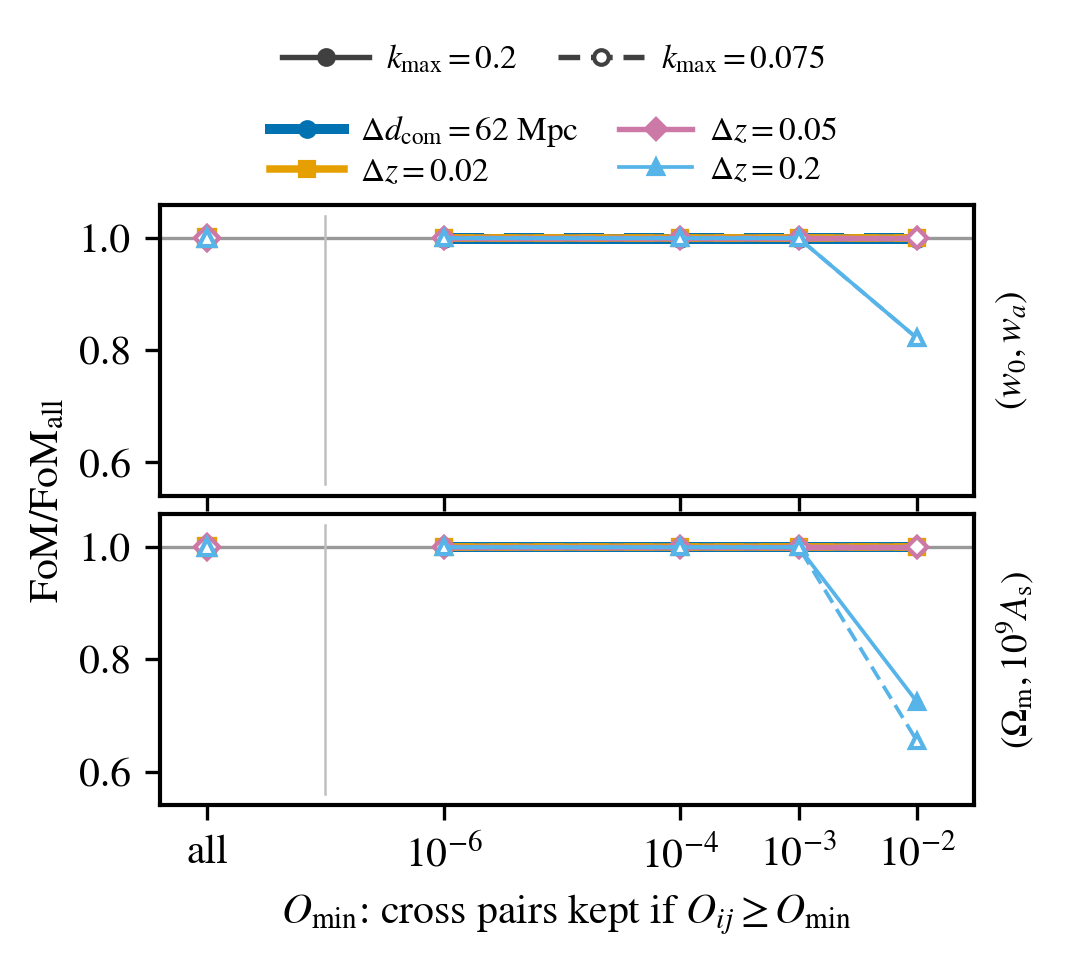

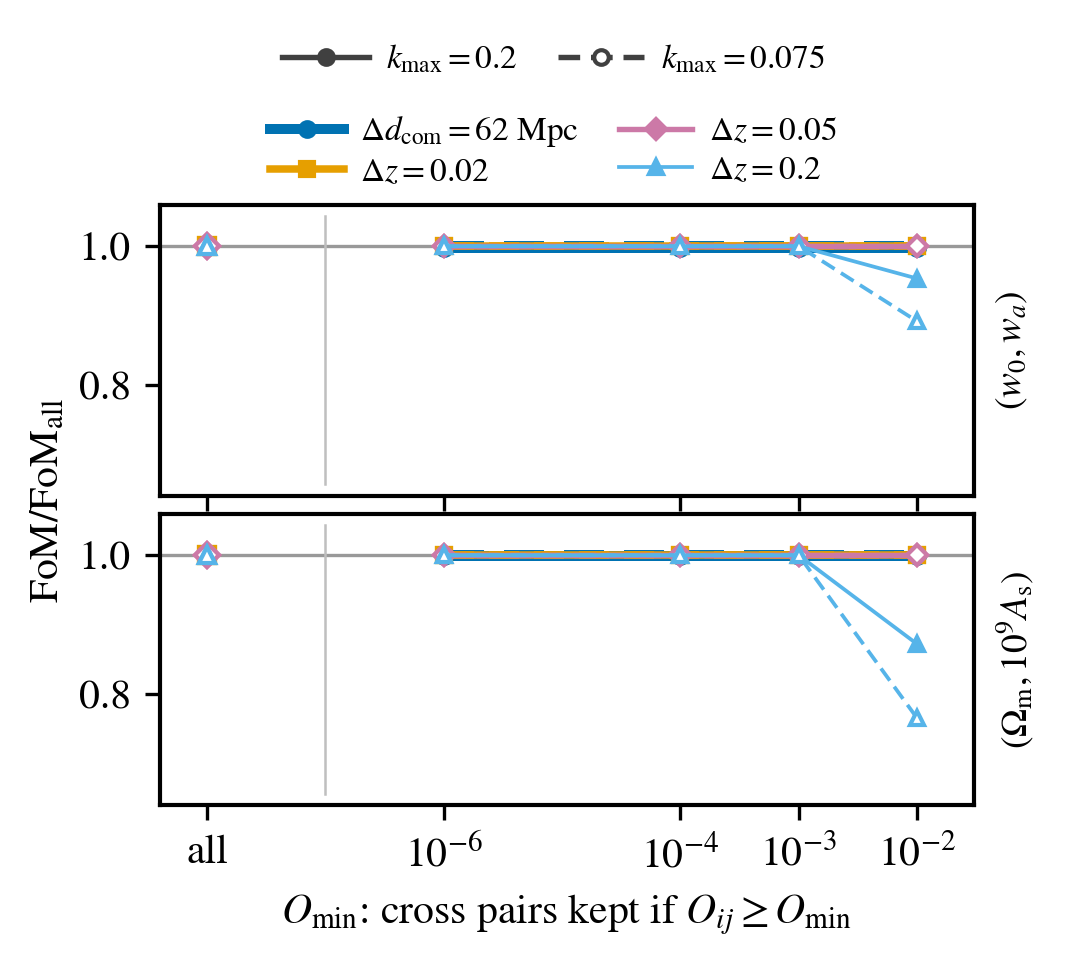

In [37]:
CROSS_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/cross_correlations/plots/'
pair_threshold = {
    'about': ('Model B + tilts on the pessimistic linear-bias prior (alpha_2 free, the '
              'exploration sigma_v widths; the reference model of the Fingers-of-God study) '
              'when only '
              'the cross pairs whose Fingers-of-God-blurred kernels overlap by O_ij >= O_min at '
              'the fiducial sigma_v are kept (O_ij = int n_i n_j dz / sqrt(int n_i^2 dz int n_j^2 '
              'dz), the blur and overlap() of scripts/make_desi_pairs.py, Gaussian truncated at 4 '
              'sigma_z), applied to every listed pair, the DESI-measured ones included; current: '
              'every listed pair. Autos always kept; a kept pair keeps its bands; the covariance '
              'block of the kept rows is inverted. Per layout and cut: FoM(w0, wa), '
              'FoM(Omega_m, 10^9 A_s) and their ratios to current, the cross pairs and cross '
              'bands kept, the sigma_v posterior widths over their prior widths (min, max), the '
              'largest |correlation| of alpha_2 and sigma_v, and the FoMs with alpha_2 and its '
              'tilts removed (alpha0_only). pair_overlaps: every listed pair\'s O_ij (bins from '
              '0). k_max is the z = 0 value of a per-bin cut at k_max/D(zbar_i). Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 11, item 7, final-tier caches).'),
    'o_min': PAIR_THRESHOLDS,
    'variants': PAIR_VARIANTS,
    'kmax_h_per_Mpc': [float(k) for k in KMAX_CUTS],
    'layouts': [],
}
for key in LAYOUTS:
    lay = OVERLAP[key]['layout']
    measured = fog_measured_pairs(key)
    pair_threshold['layouts'].append({
        'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
        'pair_overlaps': [{'bins': [i, j], 'samples': [lay['samples'][i], lay['samples'][j]],
                           'groups': [lay['groups'][i], lay['groups'][j]], 'overlap': o,
                           'desi_measured': None if measured is None else (i, j) in measured}
                          for (i, j), o in PAIR_O[key].items()],
        'scan': PAIR_SCAN[key]})

# the paper model's scan for the summary note: the same structure, without the
# alpha_2 entries the model does not have
summary_pair_threshold = {
    'about': ('The paper model (model B + tilts without alpha_2, every sigma_v prior width '
              f'{PAPER_SIGV_SCALE:g} times the exploration ones, on the pessimistic '
              'linear-bias prior) when only the cross pairs whose Fingers-of-God-blurred '
              'kernels overlap by O_ij >= O_min at the fiducial sigma_v are kept (O_ij = int '
              'n_i n_j dz / sqrt(int n_i^2 dz int n_j^2 dz), the blur and overlap() of '
              'scripts/make_desi_pairs.py, Gaussian truncated at 4 sigma_z), applied to every '
              'listed pair, the DESI-measured ones included; current: every listed pair. Autos '
              'always kept; a kept pair keeps its bands; the covariance block of the kept rows '
              'is inverted. Per layout and cut: FoM(w0, wa), FoM(Omega_m, 10^9 A_s) and their '
              'ratios to current, the cross pairs and cross bands kept, and the sigma_v '
              'posterior widths over the paper yaml\'s prior widths (min, max). pair_overlaps: '
              'every listed pair\'s O_ij (bins from 0). k_max is the z = 0 value of a per-bin '
              'cut at k_max/D(zbar_i), computed on the paper fiducial. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL.ipynb (section 11, item 7, final-tier caches).'),
    'variant': SUMMARY_VARIANT, 'prior': SUMMARY_PRIOR,
    'o_min': PAIR_THRESHOLDS,
    'variants': PAIR_VARIANTS,
    'kmax_h_per_Mpc': [float(k) for k in KMAX_CUTS],
    'layouts': [{**{k: v for k, v in lay.items() if k != 'scan'},
                 'scan': PAPER_PAIR_SCAN[lay['name']]} for lay in pair_threshold['layouts']],
}
for folder, name, data in ((CROSS_PLOTS + 'pair_threshold', 'pair_threshold', pair_threshold),
                           (SUMMARY_PLOTS + 'summary_pair_threshold', 'summary_pair_threshold',
                            summary_pair_threshold)):
    script = folder + f'/plot_{name}.py'
    if not os.path.exists(script):
        raise RuntimeError(f'{script} is missing: the folder needs its plot script')
    with open(folder + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
    display(Image(filename=f'{folder}/{name}.png', width=420))

**8. The adopted model.** The paper model, section 9's summary model, drops
$\alpha_2$ (its group values and tilts fixed at 0) and multiplies all seven
$\sigma_v$ prior widths by $s = 6$ (the largest passing $s$ of item 5, interpolated in
$\log s$ between the scanned $5$ and $10$, is $6.3$, on $\Delta z = 0.02$ at
$k_\mathrm{max} = 0.1$; at $s = 6$ itself the $\alpha_2 = 12.5$ truth moves that
fit by $0.327\sigma$, below $\sigma/3$, section 9). This cell sets it
against this section's reference, model B + tilts with $\alpha_2$ free and
$s = 1$, layout by layout and cut by cut: the ratio of
${\rm FoM}(w_0, w_a)$ and of ${\rm FoM}(\Omega_m, 10^9 A_s)$ of the adopted
model to the reference's, the same ratio with $\alpha_2$ fixed at $s = 1$
(item 3), and the adopted model's largest shift under the two $\alpha_2$
truths it lacks, $\pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$ and one model B prior
width (section 9), against $\sigma/3$. A check rebuilds item 3's
$\alpha_2$-fixed fit with section 9's construction at $s = 1$. The last
lines quote item 6 at the edges of the adopted prior, $\sigma_v$ at its
fiducial plus $k$ widened prior widths.

In [38]:
# section 9's construction at s = 1 against item 3's alpha_2-fixed fit
worst_check = 0.0
for key in LAYOUTS:
    COLUMNS[(key, 'B tilts noA2 sv x1')] = without_alpha2(COLUMNS[(key, FOG_MODEL)], 1.0)
    for m in range(NK):
        ours, status = fit_system(key, m, 'B tilts noA2 sv x1', FOG_PRIOR)
        item3, status3 = fit_system(key, m, 'B tilts noA2', FOG_PRIOR)
        if ours is not None and item3 is not None:
            worst_check = max(worst_check, abs(ours['fom']/item3['fom'] - 1.0),
                              abs(ours['fom_om_as']/item3['fom_om_as'] - 1.0))
print(f'check: without_alpha2 at s = 1 against item 3, max |FoM ratio - 1| = {worst_check:.1e}')

ADOPTED = {}
for key in LAYOUTS:
    for m in range(NK):
        reference = FOM[(key, m, FOG_MODEL, FOG_PRIOR)]
        adopted = SUMMARY[(key, m)]
        fixed, status = fit_system(key, m, 'B tilts noA2', FOG_PRIOR)
        if reference is None or adopted is None or fixed is None:
            ADOPTED[(key, m)] = None
            continue
        tested = adopted['tested']
        ADOPTED[(key, m)] = {
            'FoM(w0, wa) adopted / reference': adopted['fom']/reference['fom'],
            'FoM(w0, wa) alpha_2 fixed, s = 1 / reference': fixed['fom']/reference['fom'],
            'FoM(Om, A_s) adopted / reference': adopted['fom_om_as']/reference['fom_om_as'],
            **{f'largest shift, {family} [sigma]':
               max(v[s] for t, v in tested.items() if truth_family(t) == family for s in SCORED)
               for family in TESTED_FAMILIES[:2]}}
rows = {}
for key in LAYOUTS:
    for what in next(e for e in ADOPTED.values() if e is not None):
        rows[(FOG_SHORT[key], what)] = {fog_kfmt(m): (np.nan if ADOPTED[(key, m)] is None
                                                      else ADOPTED[(key, m)][what])
                                        for m in range(NK)}
print(f'8. the adopted model ({SUMMARY_VARIANT}) against model B + tilts with alpha_2 free at '
      f's = 1, both on the {FOG_PRIOR} prior; shifts against sigma/3 = {SHIFT_THRESHOLD:.3f}; '
      'columns: k_max')
display(pd.DataFrame(rows).T)
print(f'item 6 at the adopted prior edges: the largest O_ij outside the pair list with every '
      f'sigma_v group at fiducial + k x {PAPER_SIGV_SCALE:g} prior widths')
for key in LAYOUTS:
    o = OVERLAP[key]
    parts = []
    for k in (1, 2):
        n = int(np.argmin(np.abs(o['t'] - k*PAPER_SIGV_SCALE)))
        parts.append(f'k = {k}: {o["max_unlisted"][n]:.2e} '
                     f'{fog_pair_name(o["layout"], o["pair_at_t"][n])}')
    print(f'  {FOG_SHORT[key]:8s} ' + ' | '.join(parts))

check: without_alpha2 at s = 1 against item 3, max |FoM ratio - 1| = 0.0e+00
8. the adopted model (B tilts noA2 sv x6) against model B + tilts with alpha_2 free at s = 1, both on the pessimistic prior; shifts against sigma/3 = 0.333; columns: k_max


0.05   0.075      0.1   0.125    0.15   0.175     0.2
62 Mpc  FoM(w0, wa) adopted / reference                 1.517   1.385    1.016  0.9233  0.9126  0.9029  0.8889
        FoM(w0, wa) alpha_2 fixed, s = 1 / reference    1.517   2.402    1.741   1.314    1.26   1.218   1.161
        FoM(Om, A_s) adopted / reference                2.081    1.45    1.047  0.9588  0.9454  0.9234   0.898
        largest shift, alpha2 12.5 [sigma]             0.0102  0.2312   0.2194  0.1825  0.1759  0.1549  0.1545
        largest shift, alpha2 model B width [sigma]    0.1633   1.644   0.8775  0.4673  0.3126  0.2024  0.1545
dz 0.02 FoM(w0, wa) adopted / reference                   NaN   1.485    1.036   1.001  0.9685  0.9455  0.9432
        FoM(w0, wa) alpha_2 fixed, s = 1 / reference      NaN   2.743    2.107   1.503   1.393    1.32    1.25
        FoM(Om, A_s) adopted / reference                  NaN   1.439   0.9934  0.9546  0.9319  0.9091  0.9152
        largest shift, alpha2 12.5 [sigma]                NaN  0.1758   0.3269   0.279  0.2864  0.2907  0.3153
        largest shift, alpha2 model B width [sigma]       NaN    1.25    1.308  0.7142  0.5091  0.3797  0.3153
dz 0.05 FoM(w0, wa) adopted / reference                 1.154   1.114     1.06   1.019  0.9982   0.966  0.9523
        FoM(w0, wa) alpha_2 fixed, s = 1 / reference    1.154   1.169    1.104   1.109   1.087   1.067   1.051
        FoM(Om, A_s) adopted / reference                 1.19   1.157    1.086   1.025  0.9891  0.9456  0.9248
        largest shift, alpha2 12.5 [sigma]           0.008263 0.04807  0.07083  0.1328  0.1463  0.1446  0.1353
        largest shift, alpha2 model B width [sigma]    0.1322  0.3419   0.2833  0.3399  0.2601  0.1888  0.1353
dz 0.2  FoM(w0, wa) adopted / reference                 1.066   1.052    1.058   1.188   1.065   1.034   1.022
        FoM(w0, wa) alpha_2 fixed, s = 1 / reference    1.067   1.052    1.059   1.189   1.066   1.037   1.025
        FoM(Om, A_s) adopted / reference                1.054    1.03    1.062   1.203   1.083   1.044   1.032
        largest shift, alpha2 12.5 [sigma]           0.004387  0.0071 0.008256 0.01226 0.01652 0.03483 0.04892
        largest shift, alpha2 model B width [sigma]   0.07019 0.05049  0.03302 0.03139 0.02938  0.0455 0.04892

item 6 at the adopted prior edges: the largest O_ij outside the pair list with every sigma_v group at fiducial + k x 6 prior widths
  62 Mpc   k = 1: 3.26e-03 bins 6, 8 (BGS0, 2 apart) | k = 2: 7.10e-02 bins 6, 8 (BGS0, 2 apart)
  dz 0.02  k = 1: 4.23e-04 bins 5, 7 (BGS0, 2 apart) | k = 2: 2.48e-02 bins 5, 7 (BGS0, 2 apart)
  dz 0.05  k = 1: 0.00e+00 - | k = 2: 4.45e-07 bins 0, 2 (BGS0, 2 apart)
  dz 0.2   k = 1: 0.00e+00 - | k = 2: 0.00e+00 -
